# Health

In [50]:
import requests

r = requests.get("http://127.0.0.1:5000/health")

print(r.status_code)
print(r.text)

200
{"app_file":"/home/miggon/workspace/cc-ddh-ai-analytic-engine/app/legacy_app.py","status":"OK"}



# Helpers

In [2]:
import requests

def _dataframe_from_split(payload: dict, name: str):
    """
    Reconstruct a pandas DataFrame from a pandas 'split' payload.
    """
    import pandas as pd

    if not isinstance(payload, dict):
        raise ValueError(
            f"{name!r} must be an object containing "
            "'columns', 'index', and 'data'."
        )

    required = {"columns", "data"}
    missing = required - set(payload)

    if missing:
        raise ValueError(
            f"{name!r} is missing fields: {sorted(missing)}."
        )

    columns = payload["columns"]
    data = payload["data"]
    index = payload.get("index")

    if index is None:
        return pd.DataFrame(
            data=data,
            columns=columns,
        )

    return pd.DataFrame(
        data=data,
        columns=columns,
        index=index,
    )

def _extract_grouped_json(
    out: dict,
    show_tables: bool = False,
):
    """
    Extract the two DataFrames returned by
    POST /process-data/grouped with output_format='json'.
    """
    from IPython.display import display

    if not isinstance(out, dict):
        raise ValueError(
            "The grouped process-data response must be a JSON object."
        )

    if "data" not in out:
        raise ValueError(
            "The grouped response does not contain 'data'."
        )

    if "grouped" not in out:
        raise ValueError(
            "The grouped response does not contain 'grouped'."
        )

    process_df = _dataframe_from_split(
        out["data"],
        "data",
    )

    grouped_df = _dataframe_from_split(
        out["grouped"],
        "grouped",
    )

    metadata = out.get("metadata", {})

    tables = {
        "process": process_df,
        "grouped": grouped_df,
    }

    if show_tables:
        print("process")
        display(process_df.head())

        print("grouped")
        display(grouped_df.head())

        if metadata:
            print("metadata")
            print(metadata)

    return tables, {}, metadata

def _extract_grouped_parquet(
    response,
    show_tables: bool = False,
):
    """
    Extract the two DataFrames returned by
    POST /process-data/grouped with output_format='parquet'.

    Expected ZIP members:
        process_data.parquet
        process_grouped.parquet
        metadata.json
    """
    import io
    import json
    import zipfile

    import pandas as pd
    from IPython.display import display

    try:
        archive_buffer = io.BytesIO(response.content)

        with zipfile.ZipFile(archive_buffer) as archive:
            members = set(archive.namelist())

            required = {
                "process_data.parquet",
                "process_grouped.parquet",
            }

            missing = required - members

            if missing:
                raise ValueError(
                    "The grouped Parquet response is missing ZIP members: "
                    f"{sorted(missing)}."
                )

            with archive.open(
                "process_data.parquet"
            ) as parquet_file:
                process_df = pd.read_parquet(
                    io.BytesIO(parquet_file.read())
                )

            with archive.open(
                "process_grouped.parquet"
            ) as parquet_file:
                grouped_df = pd.read_parquet(
                    io.BytesIO(parquet_file.read())
                )

            if "metadata.json" in members:
                with archive.open(
                    "metadata.json"
                ) as metadata_file:
                    metadata = json.load(metadata_file)
            else:
                metadata = {}

    except zipfile.BadZipFile as exc:
        raise ValueError(
            "The server response is not a valid grouped Parquet ZIP file."
        ) from exc

    tables = {
        "process": process_df,
        "grouped": grouped_df,
    }

    if show_tables:
        print("process")
        display(process_df.head())

        print("grouped")
        display(grouped_df.head())

        if metadata:
            print("metadata")
            print(metadata)

    return tables, {}, metadata

def _extract_analytical_parquet(
    response,
    show_text: bool = True,
    show_tables: bool = False,
    show_figures: bool = False,
):
    """
    Extract tables from an analytical endpoint response
    when output_format='parquet'.

    Expected ZIP members:
        <table_id>.parquet  (one per table)
        metadata.json
    """
    import io
    import json
    import zipfile

    import pandas as pd
    from IPython.display import display, Markdown

    try:
        archive_buffer = io.BytesIO(response.content)

        with zipfile.ZipFile(archive_buffer) as archive:
            members = archive.namelist()

            metadata = {}
            if "metadata.json" in members:
                with archive.open(
                    "metadata.json"
                ) as metadata_file:
                    metadata = json.load(metadata_file)

            tables = {}
            for name in members:
                if name.endswith(".parquet"):
                    table_id = name.replace(
                        ".parquet", ""
                    )
                    with archive.open(name) as pf:
                        df = pd.read_parquet(
                            io.BytesIO(pf.read())
                        )
                    tables[table_id] = df

    except zipfile.BadZipFile as exc:
        raise ValueError(
            "The server response is not a valid "
            "Parquet ZIP file."
        ) from exc

    if show_text and metadata.get("text"):
        display(Markdown(metadata["text"]))

    if show_tables:
        for table_id, df in tables.items():
            print(table_id)
            display(df.head())

    return tables, {}

def extract(
    out,
    download_artifacts,
    show_text=True,
    show_tables=False,
    show_figures=False,
    base_url="http://127.0.0.1:5000",
    output_format=None,
):
    import io

    import pandas as pd
    import plotly.graph_objects as go
    import requests
    from IPython.display import display, Markdown

    normalized_format = (
        output_format.strip().lower()
        if isinstance(output_format, str)
        else None
    )

    # --------------------------------------------------------------
    # Special response from POST /process-data/grouped in JSON mode
    # --------------------------------------------------------------
    if (
        normalized_format == "json"
        and isinstance(out, dict)
        and "data" in out
        and "grouped" in out
    ):
        tables, figures, _ = _extract_grouped_json(
            out,
            show_tables=show_tables,
        )
        return tables, figures

    # Defensive automatic detection, even when output_format was not
    # explicitly passed to extract().
    if (
        isinstance(out, dict)
        and "data" in out
        and "grouped" in out
        and "tables" not in out
        and "figures" not in out
    ):
        tables, figures, _ = _extract_grouped_json(
            out,
            show_tables=show_tables,
        )
        return tables, figures

    # --------------------------------------------------------------
    # Normal analytical/card response
    # --------------------------------------------------------------
    if show_text and out.get("text"):
        display(Markdown(out["text"]))

    tables = {}
    figures = {}

    if download_artifacts:
        for table in out.get("tables", []):
            table_url = (
                base_url.rstrip("/")
                + table["artifact"]["url"]
            )

            rt = requests.get(
                table_url,
                timeout=120,
            )
            rt.raise_for_status()

            df = pd.read_parquet(
                io.BytesIO(rt.content)
            )

            tables[table["id"]] = df

            if show_tables:
                print(table["id"])
                display(df.head())

        for fig_payload in out.get("figures", []):
            fig_url = (
                base_url.rstrip("/")
                + fig_payload["artifact"]["url"]
            )

            rf = requests.get(
                fig_url,
                timeout=120,
            )
            rf.raise_for_status()

            fig = go.Figure(rf.json())
            figures[fig_payload["id"]] = fig

            if show_figures:
                fig.show()

    else:
        for table in out.get("tables", []):
            inline = table.get("inline", {})

            # Support both records and split-style inline tables.
            if {
                "columns",
                "data",
            }.issubset(inline):
                df = _dataframe_from_split(
                    inline,
                    table.get("id", "table"),
                )
            else:
                df = pd.DataFrame(
                    inline.get("data", [])
                )

            tables[table["id"]] = df

            if show_tables:
                print(table["id"])
                display(df.head())

        for fig_payload in out.get("figures", []):
            fig_json = fig_payload["plotly_json"]

            fig = go.Figure(fig_json)
            figures[fig_payload["id"]] = fig

            if show_figures:
                fig.show()

    return tables, figures

def wait_for_job(
    job_id: str,
    endpoint_url: str = "http://127.0.0.1:5000/",
    poll_interval: float = 2.0,
    timeout: float = 15 * 60,
):
    import time
    import requests

    base_url = endpoint_url.rstrip("/")
    job_url = f"{base_url}/jobs/{job_id}"

    start_time = time.monotonic()
    previous_status = None

    while True:
        r = requests.get(
            job_url,
            timeout=30,
        )

        print("Job HTTP status:", r.status_code)

        if not r.ok:
            try:
                response = r.json()
            except ValueError:
                response = r.text

            raise RuntimeError(
                f"Could not retrieve job {job_id}: {response}"
            )

        job = r.json()
        status = job.get("status")

        if status != previous_status:
            print(f"Job status: {status}")
            previous_status = status

        if status == "completed":
            if "result" not in job:
                raise RuntimeError(
                    f"Job {job_id} completed but returned no result."
                )

            return job["result"]

        if status == "failed":
            error = job.get("error", "Unknown optimisation error")
            result = job.get("result")

            if result:
                raise RuntimeError(
                    f"Optimisation failed: {error}\n"
                    f"Engine response: {result}"
                )

            raise RuntimeError(
                f"Optimisation failed: {error}"
            )

        if status not in {"queued", "running"}:
            raise RuntimeError(
                f"Unexpected job status: {status}"
            )

        elapsed = time.monotonic() - start_time

        if elapsed >= timeout:
            raise TimeoutError(
                f"Job {job_id} did not finish within "
                f"{timeout:.0f} seconds."
            )

        time.sleep(poll_interval)

def run_query(
    query: str,
    download_artifacts: bool = True,
    endpoint_url: str = "http://127.0.0.1:5000/ask-card",
):
    import requests

    r = requests.post(
        endpoint_url,
        json={
            "query": query,
            "download_artifacts": download_artifacts,
            "diagnosis_summary": True,
            "cost_driver_summary": False,
        },
        timeout=120,
    )

    print("HTTP status:", r.status_code)

    try:
        response = r.json()
    except ValueError:
        print("The server did not return JSON:")
        print(r.text)
        return None, None

    if r.ok:
        base_url = endpoint_url.rsplit("/", 1)[0]

        return extract(
            response,
            download_artifacts,
            show_tables=True,
            show_figures=True,
            base_url=base_url,
        )

    print("\nERROR RESPONSE")
    print(response)

    if isinstance(response, dict):
        print("\nMessage:")
        print(response.get("message", response))

    return None, None

def ask_engine(
    params: dict,
    endpoint: str,
    download_artifacts: bool = True,
    endpoint_url: str = "http://127.0.0.1:5000/",
    run_async: bool = True,
    poll_interval: float = 5.0,
    job_timeout: float = 30 * 60,
):
    import io
    import time

    import pandas as pd
    import requests

    base_url = endpoint_url.rstrip("/")
    endpoint = endpoint.strip("/")
    full_endpoint = f"{base_url}/{endpoint}"

    # Do not modify the caller's dictionary.
    request_params = dict(params)

    print(f"Calling: {full_endpoint}")

    # ==============================================================
    # GET /process-data/parquet
    # ==============================================================

    if endpoint == "process-data/parquet":
        print("Response format: parquet")

        try:
            response = requests.get(
                full_endpoint,
                params=request_params,
                timeout=(10, 120),
            )

        except requests.exceptions.RequestException as exc:
            print(f"Request failed: {exc}")
            return None, None

        print("HTTP status:", response.status_code)

        if response.ok:
            try:
                process_df = pd.read_parquet(
                    io.BytesIO(response.content)
                )
            except Exception as exc:
                print(
                    "The response could not be read as Parquet:"
                )
                print(exc)
                return None, None

            return {
                "process": process_df,
            }, {}

        print("\nERROR RESPONSE")

        try:
            error_response = response.json()
        except ValueError:
            error_response = response.text

        print(error_response)
        return None, None

    # ==============================================================
    # POST /process-data/grouped
    # ==============================================================

    if endpoint == "process-data/grouped":
        output_format = request_params.get(
            "output_format",
            "json",
        )

        if not isinstance(output_format, str):
            print(
                "output_format must be either "
                "'json' or 'parquet'."
            )
            return None, None

        output_format = output_format.strip().lower()

        if output_format not in {
            "json",
            "parquet",
        }:
            print(
                f"Unsupported output_format={output_format!r}. "
                "Supported values are 'json' and 'parquet'."
            )
            return None, None

        request_params["output_format"] = output_format

        # This endpoint returns either JSON or a ZIP directly.
        # A binary ZIP cannot be transported through the normal
        # JSON-based asynchronous job response.
        if run_async:
            print(
                "Note: /process-data/grouped is being called "
                "synchronously because it returns DataFrames "
                "directly."
            )

        print(f"Output format: {output_format}")

        try:
            response = requests.post(
                full_endpoint,
                json=request_params,
                timeout=(10, job_timeout),
            )

        except requests.exceptions.ReadTimeout:
            print(
                "The grouped process-data request timed out."
            )
            return None, None

        except requests.exceptions.ConnectionError as exc:
            print(
                f"Could not connect to the engine: {exc}"
            )
            return None, None

        except requests.exceptions.RequestException as exc:
            print(f"Request failed: {exc}")
            return None, None

        print("HTTP status:", response.status_code)

        if not response.ok:
            print("\nERROR RESPONSE")

            try:
                error_response = response.json()
            except ValueError:
                error_response = response.text

            print(error_response)
            return None, None

        if output_format == "parquet":
            try:
                tables, figures, metadata = (
                    _extract_grouped_parquet(
                        response,
                        show_tables=True,
                    )
                )

            except Exception as exc:
                print(
                    "Could not extract the grouped "
                    "Parquet response:"
                )
                print(exc)
                return None, None

        else:
            try:
                response_payload = response.json()

            except ValueError:
                print(
                    "The grouped endpoint did not "
                    "return valid JSON:"
                )
                print(response.text)
                return None, None

            try:
                tables, figures, metadata = (
                    _extract_grouped_json(
                        response_payload,
                        show_tables=True,
                    )
                )

            except Exception as exc:
                print(
                    "Could not reconstruct the grouped "
                    "DataFrames:"
                )
                print(exc)
                return None, None

        if metadata:
            print("Grouped process-data metadata:")
            print(metadata)

        return tables, figures

    # ==============================================================
    # Normal analytical endpoints (with output_format support)
    # ==============================================================

    output_format = request_params.pop(
        "output_format", "json"
    )
    if isinstance(output_format, str):
        output_format = output_format.strip().lower()
    else:
        output_format = "json"

    if output_format not in {"json", "parquet"}:
        print(
            f"Unsupported output_format={output_format!r}. "
            "Using 'json'."
        )
        output_format = "json"

    request_params["output_format"] = output_format
    request_params["download_artifacts"] = (
        download_artifacts
    )
    request_params["async"] = run_async

    # Parquet output requires synchronous mode because
    # the ZIP binary cannot travel through the JSON job response.
    if output_format == "parquet" and run_async:
        print(
            "Note: output_format='parquet' requires "
            "synchronous mode. Setting async=false."
        )
        request_params["async"] = False
        run_async = False

    print(
        f"Mode: "
        f"{'asynchronous' if run_async else 'synchronous'}"
    )

    submission_started = time.monotonic()

    try:
        response = requests.post(
            full_endpoint,
            json=request_params,
            timeout=(
                10,
                30 if run_async else job_timeout,
            ),
        )

    except requests.exceptions.ReadTimeout:
        elapsed = (
            time.monotonic()
            - submission_started
        )

        if run_async:
            print(
                f"The initial POST timed out after "
                f"{elapsed:.1f} seconds.\n"
                "An asynchronous endpoint should return "
                "a job_id almost immediately. Check that "
                "the service was restarted and that this "
                "endpoint supports async mode."
            )
        else:
            print(
                f"The synchronous request timed out after "
                f"{elapsed:.1f} seconds."
            )

        return None, None

    except requests.exceptions.ConnectionError as exc:
        print(
            f"Could not connect to the engine: {exc}"
        )
        return None, None

    except requests.exceptions.RequestException as exc:
        print(f"Request failed: {exc}")
        return None, None

    submission_elapsed = (
        time.monotonic()
        - submission_started
    )

    print(
        "Submission response received after "
        f"{submission_elapsed:.2f} seconds."
    )
    print("HTTP status:", response.status_code)

    # ----------------------------------------------------------
    # Synchronous parquet response (binary ZIP, not JSON)
    # ----------------------------------------------------------
    if (
        output_format == "parquet"
        and response.ok
        and response.status_code != 202
    ):
        try:
            return _extract_analytical_parquet(
                response,
                show_text=True,
                show_tables=True,
                show_figures=False,
            )
        except Exception as exc:
            print(
                "Could not extract the Parquet "
                "response:"
            )
            print(exc)
            return None, None

    try:
        response_payload = response.json()

    except ValueError:
        print(
            "\nThe server did not return valid JSON:"
        )
        print(response.text)
        return None, None

    if not response.ok:
        print("\nERROR RESPONSE")
        print(response_payload)

        if isinstance(response_payload, dict):
            print("\nMessage:")
            print(
                response_payload.get(
                    "message",
                    response_payload.get(
                        "text",
                        response_payload,
                    ),
                )
            )

        return None, None

    # Generic asynchronous response handling.
    if response.status_code == 202:
        if "job_id" not in response_payload:
            print(
                "\nThe endpoint returned HTTP 202 "
                "but no job_id."
            )
            print(response_payload)
            return None, None

        job_id = response_payload["job_id"]
        job_type = response_payload.get(
            "job_type",
            endpoint,
        )

        print(f"{job_type} accepted.")
        print(f"Job ID: {job_id}")

        try:
            response_payload = wait_for_job(
                job_id=job_id,
                endpoint_url=endpoint_url,
                poll_interval=poll_interval,
                timeout=job_timeout,
            )

        except Exception as exc:
            print(f"\nJob failed: {exc}")
            return None, None

        print(f"{job_type} completed.")

    elif run_async:
        print(
            "Warning: asynchronous mode was requested, "
            f"but the endpoint returned HTTP "
            f"{response.status_code} instead of HTTP 202. "
            "Treating the response as a final result."
        )

    return extract(
        response_payload,
        download_artifacts,
        show_tables=True,
        show_figures=True,
        base_url=base_url,
    )


# Process data

## Raw

### Reels

In [51]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/process-data/reels",
    params={
        "start": "2026-08-25T00:00:00",
        "end": "2026-08-26T00:00:00"
    }
)

print(response.json())
pd.DataFrame(response.json()["items"])

{'count': 26, 'items': [{'reel_id': '12606000', 'timestamp': '2026-08-25T02:15:00'}, {'reel_id': '12606001', 'timestamp': '2026-08-25T03:12:00'}, {'reel_id': '12606002', 'timestamp': '2026-08-25T04:08:00'}, {'reel_id': '12606003', 'timestamp': '2026-08-25T05:04:00'}, {'reel_id': '12606004', 'timestamp': '2026-08-25T06:00:00'}, {'reel_id': '12606005', 'timestamp': '2026-08-25T06:57:00'}, {'reel_id': '12606006', 'timestamp': '2026-08-25T07:54:00'}, {'reel_id': '12606007', 'timestamp': '2026-08-25T08:50:00'}, {'reel_id': '12606008', 'timestamp': '2026-08-25T09:47:00'}, {'reel_id': '12606009', 'timestamp': '2026-08-25T10:43:00'}, {'reel_id': '12606010', 'timestamp': '2026-08-25T11:04:00'}, {'reel_id': '12606011', 'timestamp': '2026-08-25T12:24:00'}, {'reel_id': '12606012', 'timestamp': '2026-08-25T13:20:00'}, {'reel_id': '12606013', 'timestamp': '2026-08-25T14:17:00'}, {'reel_id': '12606014', 'timestamp': '2026-08-25T15:13:00'}, {'reel_id': '12606015', 'timestamp': '2026-08-25T16:10:00'}, 

,reel_id,timestamp
0,12606000,2026-08-25T02:15:00
1,12606001,2026-08-25T03:12:00
2,12606002,2026-08-25T04:08:00
3,12606003,2026-08-25T05:04:00
4,12606004,2026-08-25T06:00:00
5,12606005,2026-08-25T06:57:00
6,12606006,2026-08-25T07:54:00
7,12606007,2026-08-25T08:50:00
8,12606008,2026-08-25T09:47:00
9,12606009,2026-08-25T10:43:00


In [28]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/process-data/reels",
    params={
        "start": "2026-08-01T00:00:00",
        "end": "2026-08-08T23:59:59"
    }
)

print(response.json())
pd.DataFrame(response.json()["items"])

{'count': 139, 'items': [{'reel_id': '12605418', 'timestamp': '2026-08-01T02:40:00'}, {'reel_id': '12605419', 'timestamp': '2026-08-01T03:44:00'}, {'reel_id': '12605420', 'timestamp': '2026-08-01T04:32:00'}, {'reel_id': '12605421', 'timestamp': '2026-08-01T05:45:00'}, {'reel_id': '12605422', 'timestamp': '2026-08-01T06:50:00'}, {'reel_id': '12605423', 'timestamp': '2026-08-01T07:54:00'}, {'reel_id': '12605424', 'timestamp': '2026-08-01T08:59:00'}, {'reel_id': '12605425', 'timestamp': '2026-08-01T10:03:00'}, {'reel_id': '12605426', 'timestamp': '2026-08-01T11:08:00'}, {'reel_id': '12605427', 'timestamp': '2026-08-01T12:12:00'}, {'reel_id': '12605428', 'timestamp': '2026-08-01T13:17:00'}, {'reel_id': '12605429', 'timestamp': '2026-08-01T14:21:00'}, {'reel_id': '12605430', 'timestamp': '2026-08-01T15:26:00'}, {'reel_id': '12605431', 'timestamp': '2026-08-01T16:30:00'}, {'reel_id': '12605432', 'timestamp': '2026-08-01T17:35:00'}, {'reel_id': '12605433', 'timestamp': '2026-08-01T18:39:00'},

,reel_id,timestamp
0,12605418,2026-08-01T02:40:00
1,12605419,2026-08-01T03:44:00
2,12605420,2026-08-01T04:32:00
3,12605421,2026-08-01T05:45:00
4,12605422,2026-08-01T06:50:00
...,...,...
134,12605564,2026-08-07T05:34:00
135,12605565,2026-08-07T06:30:00
136,12605566,2026-08-07T07:27:00
137,12605567,2026-08-07T08:23:00


### Snapshot

#### by timestamp

In [ ]:
response = requests.get(
    "http://localhost:5000/process-data/snapshot",
    params={"timestamp": "2026-03-11T15:50:00"},
)

pd.DataFrame([response.json()["snapshot"]])

,3200,3300,6010,AB_Grade_ID,AD6_fabric_tension,AD6_speed,AD7_fabric_tension_bottom,AD7_speed_bottom,AD7_speed_top,APA_400V__-1..10_MW_,...,mismatch_run_length,mismatch_run_pos,new_grammage_batch,overprocessing_score,overprocessing_std,pH-Messung_Verdünnungswasser__2..12_pH_,pH_measurement_white_water_B41,paper_type,retention,underprocessing_score
0,False,False,True,6010100,1.083623,1317.600098,0.989583,1317.675049,1317.677856,0.0,...,0,0,True,4.732469,3.366235,6.936343,6.818518,6010,0.754693,0.0


#### by reel id

In [127]:
response = requests.get(
    "http://localhost:5000/process-data/snapshot",
    params={"reel_id": "12601843"},
)

pd.DataFrame([response.json()["snapshot"]])

,3200,3300,6010,AB_Grade_ID,AD6_fabric_tension,AD6_speed,AD7_fabric_tension_bottom,AD7_speed_bottom,AD7_speed_top,APA_400V__-1..10_MW_,...,mismatch_run_length,mismatch_run_pos,new_grammage_batch,overprocessing_score,overprocessing_std,pH-Messung_Verdünnungswasser__2..12_pH_,pH_measurement_white_water_B41,paper_type,retention,underprocessing_score
0,False,False,True,6010100,1.083623,1317.600098,0.989583,1317.675049,1317.677856,0.0,...,0,0,True,4.732469,3.366235,6.936343,6.818518,6010,0.754693,0.0


### Grades

In [8]:
response = requests.get(
    "http://localhost:5000/process-data/grades",
)

response.json()["grades"]

['3200115',
 '3300085',
 '3300100',
 '3300110',
 '3300115',
 '3300120',
 '3300125',
 '6010085',
 '6010090',
 '6010100',
 '6010120']

### Variables

#### All variables

In [33]:
[v for v in response.json()["variables"] if "price" in v.lower()]

['Bentonite_price',
 'Deaerator_price',
 'Defoamer_price',
 'Dry_Strength_Agent_price',
 'Electricity_price',
 'Fibre_price',
 'Fixative_2_price',
 'Natriumhydroxide_price',
 'Retention_Aid_price',
 'Sizing_Agent_price',
 'Starch_price',
 'Steam_price']

In [34]:
response = requests.get(
        "http://localhost:5000/process-data/variables",
        params={
            "functions":None
        },
    )
response.json()["variables"]

['3200',
 '3300',
 '6010',
 'AB_Grade_ID',
 'AD6_fabric_tension',
 'AD6_speed',
 'AD7_fabric_tension_bottom',
 'AD7_speed_bottom',
 'AD7_speed_top',
 'APA_400V__-1..10_MW_',
 'APA_660V__-1..10_MW_',
 'APA_660V__-1..10_MW_~^0',
 'APA_6KV__-1..10_MW_',
 'ATS1_differential_pressure',
 'ATS1_light_reject_flow',
 'ATS1_power',
 'ATS2_differential_pressure',
 'ATS2_light_reject_flow',
 'ATS2_power',
 'Act_Deaerator_mass_flow__g/T_',
 'Act_Deaerator_mass_flow__l/h_',
 'Act_Production_Rate_Gross',
 'Actual_moisture',
 'Afterdryers_sensor_1_to_9',
 'Aggregated_cost__€/T_',
 'AirTurn_Temperature',
 'Air_pressure_of_rod_clamping_hose_Bottom_Roll',
 'Air_pressure_of_rod_clamping_hose_Top_Roll',
 'Airturn_pillow_pressure',
 'Aktuelle_Arbeitsbreite_in_cm~^0',
 'Approach_flow_returns',
 'Arbeit_0,7kV_RSM2_und_RTA_(Ab)__MWh_',
 'Arbeit_DSS_P5_Eigenbedarf_Werk_gesamt__MWh_',
 'Ash_measurement_HC-line',
 'Auftrag_Stärkeslurry_BW',
 'Auftrag_Stärkeslurry_FW',
 'BSW_2_sigma',
 'Backflow_cross-flow_distrib

#### by function

In [22]:
response = requests.get(
        "http://localhost:5000/process-data/variables",
        params={
            "functions":["SCT CD"]
        },
    )
response.json()["variables"]

['Consistency_starch_main_line',
 'Current_basis_weight',
 'Current_reel_width',
 'Draw_AD6-AD7',
 'Draw_AD7-PR',
 'Draw_PD1-PD2',
 'Draw_PD2-PD3',
 'Draw_PD3-PD4',
 'Draw_PD4-PD5',
 'Draw_PD5-SS',
 'Draw_PS-PD1',
 'Draw_SS-AD6',
 'Draw_WS-PS',
 'Headbox_consistency',
 'Jet/wire_ratio',
 'Linepressure_1st_press_DS__bar_',
 'Linepressure_1st_press_FS__bar_',
 'Linepressure_2nd_press_DS__bar_',
 'Linepressure_2nd_press_FS__bar_',
 'Linepressure_shoe_press__bar_',
 'Lip_settings',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'MBS_SCT_CD_state',
 'Moisture_after_SpeedSizer',
 'Retention_Aid_mass_flow__g/T_',
 'Short_fibre_B06_consistency',
 'Short_fibre_flow',
 'Speed',
 'SpeedSizer_Linepressure_DS',
 'SpeedSizer_Linepressure_FS',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Starch_uptake_by_paper_Top_Roll__g/m2_',
 'Viscosity_for_working_tank_bottom_roll',
 'White_water_temperature',
 'concentration_starch_working_tank_1',
 'concentration_starch_working_tank_2',
 'grammage',
 'r

In [18]:
response = requests.get(
        "http://localhost:5000/process-data/variables",
        params={
            "functions":["SCT CD","steam"]
        },
    )
response.json()["variables"]

['Act_Deaerator_mass_flow__g/T_',
 'Current_basis_weight',
 'Current_reel_moisture_average(reel)',
 'Current_reel_width',
 'DG1_temperature_Inlet_Air',
 'DG2_temperature_Inlet_Air',
 'DG3_temperature_Inlet_Air',
 'DG4_Temperature_Inlet_Air',
 'DG5_Temperature_Inlet_Air',
 'Dewatering_First_Press_Roll',
 'Dewatering_Shoe_press',
 'Dewatering_Suction_Press_Roll',
 'Dewatering_top_wire_suction_box_zone_2',
 'Dissolved_gas_after_stock_deculator_measurement_1',
 'Dissolved_gas_before_dilution_water_deculator',
 'Draw_PD3-PD4',
 'Fixative_2_mass_flow__g/T_',
 'Free_gas_after_stock_deculator~^0',
 'Free_gas_before_dilution_water_deculator_measurement_1~^0',
 'Free_gas_before_dilution_water_deculator_measurement_2',
 'Headbox_consistency',
 'Jet/wire_ratio',
 'Linepressure_1st_press_DS__bar_',
 'Linepressure_1st_press_FS__bar_',
 'Linepressure_shoe_press__bar_',
 'Lip_settings',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'MBS_SCT_CD_L1',
 'Moisture_out_of_PreDryer',
 'PickUp_Tension',

In [20]:
response = requests.get(
        "http://localhost:5000/process-data/variables",
        params={
            "functions":["starch uptake"]
        },
    )
response.json()["variables"]

['Conductivity_white_water_B46',
 'Current_reel_moisture_average(SpeedSizer)',
 'Jet/wire_ratio',
 'Lip_settings',
 'Moisture_after_SpeedSizer',
 'Moisture_out_of_PreDryer',
 'Retention_Aid_mass_flow__g/T_',
 'Rod_Pressure_Bottom_Roll',
 'Rod_pressure_Top_Roll',
 'SpeedSizer_Linepressure_DS',
 'SpeedSizer_Linepressure_FS',
 'Speed_Size_Press',
 'Temperature_starch_working_tank_1',
 'Temperature_starch_working_tank_2',
 'Top_wire_tenstion',
 'White_water_temperature',
 'concentration_starch_working_tank_1',
 'concentration_starch_working_tank_2',
 'grammage',
 'retention']

### Cost label

In [17]:
response = requests.get(
        "http://localhost:5000/process-data/cost-label",
    )
response.json()["cost_label"]

'Combined_cost__€/T_'

### Cost Subcomponents

In [13]:
response = requests.get(
        "http://localhost:5000/process-data/chemical-subcomponents",
    )
response.json()["chemical_subcomponents"]

{'consumption': ['Retention_Aid_mass_flow__g/T_',
  'Bentonite_1_mass_flow__g/T_',
  'Bentonite_2_mass_flow__g/T_',
  'Fixative_2_mass_flow__g/T_',
  'Act_Deaerator_mass_flow__g/T_',
  'Defoamer_mass_flow__g/T_',
  'Sizing_Agent__g/T_',
  'Dry_Strength_Agent_mass_flow__kg/T_',
  'Natriumhydroxide_mass_flow__g/T_'],
 'cost': ['Retention_Aid__€/T_',
  'Bentonite_1__€/T_',
  'Bentonite_2__€/T_',
  'Fixative_2__€/T_',
  'Deaerator__€/T_',
  'Defoamer__€/T_',
  'Sizing_Agent__€/T_',
  'Dry_Strength_Agent__€/T_',
  'Natriumhydroxide__€/T_']}

In [14]:
response = requests.get(
        "http://localhost:5000/process-data/steam-subcomponents",
    )
response.json()["steam_subcomponents"]

{'consumption': ['Steam_Predryers__kWh/T_',
  'Steam_Afterdryers__kWh/T_',
  'Steam_Starchkitchen__kWh/T_',
  'Steam_Heatexchangers__kWh/T_',
  'Steam_Whitewater__kWh/T_'],
 'cost': ['Steam_Predryers__€/T_',
  'Steam_Afterdryers__€/T_',
  'Steam_Starchkitchen__€/T_',
  'Steam_Heatexchangers__€/T_',
  'Steam_Whitewater__€/T_']}

In [15]:
response = requests.get(
        "http://localhost:5000/process-data/electricity-subcomponents",
    )
response.json()["electricity_subcomponents"]

{'consumption': ['Electricity_Wiresection__kWh/T_',
  'Electricity_Press_and_Steambox__kWh/T_',
  'Electricity_Freqconverters__kWh/T_',
  'Electricity_Other__kWh/T_',
  'Electricity_Predryer__kWh/T_',
  'Electricity_Afterdryer__kWh/T_',
  'Electricity_Specific__kWh/T_'],
 'cost': ['Electricity_Wiresection__€/T_',
  'Electricity_Press_and_Steambox__€/T_',
  'Electricity_Freqconverters__€/T_',
  'Electricity_Other__€/T_',
  'Electricity_Predryer__€/T_',
  'Electricity_Afterdryer__€/T_',
  'Electricity_Specific__€/T_']}

### Variable bounds

In [43]:
r = requests.get(
    "http://localhost:5000/process-data/variable-bounds",
    params={
        "variables": [
            'Steam__€/T_','Electricity__€/T_','Starch__€/T_','Chemicals__€/T_','Fibre_cost__€/T_'      
        ],
        #"grade": "6010120",
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

pd.DataFrame(r.json()["bounds"])

ConnectionError: HTTPConnectionPool(host='localhost', port=5000): Max retries exceeded with url: /process-data/variable-bounds?variables=Steam__%E2%82%AC%2FT_&variables=Electricity__%E2%82%AC%2FT_&variables=Starch__%E2%82%AC%2FT_&variables=Chemicals__%E2%82%AC%2FT_&variables=Fibre_cost__%E2%82%AC%2FT_&lower_percentile=0.05&upper_percentile=0.95 (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x000002264A19E360>: Failed to establish a new connection: [WinError 10061] No connection could be made because the target machine actively refused it'))

In [45]:
r = requests.get(
    "http://localhost:5000/process-data/variable-bounds",
    params={
        "variables": [
            "Current_basis_weight", 'Current_reel_moisture_average(reel)'      
        ],
        "grades": ["6010120","6010100"],
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

pd.DataFrame(r.json()["bounds"])

,available,conditional_error,conditional_lower_bound,conditional_median,conditional_upper_bound,current_value,grade,lower_bound,method,mode,upper_bound,variable
0,True,None,None,None,None,None,6010120,118.001073,marginal_quantile,marginal_quantile,121.293686,Current_basis_weight
1,True,None,None,None,None,None,6010120,7.798764,marginal_quantile,marginal_quantile,8.383088,Current_reel_moisture_average(reel)
2,True,None,None,None,None,None,6010100,99.502520,marginal_quantile,marginal_quantile,101.890709,Current_basis_weight
3,True,None,None,None,None,None,6010100,7.590360,marginal_quantile,marginal_quantile,8.214874,Current_reel_moisture_average(reel)


In [ ]:
r = requests.get(
    "http://localhost:5000/process-data/variable-bounds",
    params={
        "variables": [
            ['Steam__€/T_','Electricity__€/T_','Starch__€/T_','Chemicals__€/T_','Fibre_cost__€/T_']   
        ],
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

df = pd.DataFrame(r.json()["bounds"])[["lower_bound","upper_bound","variable"]]
df["median"] = df["lower_bound"] + df["upper_bound"]
df["weight"] = df["median"] / df["median"] .sum()
df[["weight","variable"]]

,available,conditional_error,conditional_lower_bound,conditional_median,conditional_upper_bound,current_value,grade,lower_bound,method,mode,upper_bound,variable
0,True,None,None,None,None,None,ALL,79.676595,marginal_quantile,marginal_quantile,99.331994,Steam__€/T_
1,True,None,None,None,None,None,ALL,32.445134,marginal_quantile,marginal_quantile,42.859851,Electricity__€/T_
2,True,None,None,None,None,None,ALL,17.989943,marginal_quantile,marginal_quantile,26.511966,Starch__€/T_
3,True,None,None,None,None,None,ALL,2.575128,marginal_quantile,marginal_quantile,8.868359,Chemicals__€/T_
4,True,None,None,None,None,None,ALL,126.510465,marginal_quantile,marginal_quantile,129.643292,Fibre_cost__€/T_


In [44]:
r = requests.get(
    "http://localhost:5000/process-data/variable-bounds",
    params={
        "variables": [
            "Current_basis_weight", 'Current_reel_moisture_average(reel)'      
        ],
        "reel_id": 12602792,
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

pd.DataFrame(r.json()["bounds"])

,available,conditional_error,conditional_lower_bound,conditional_median,conditional_upper_bound,current_value,grade,lower_bound,method,mode,upper_bound,variable
0,True,None,117.925124,118.899438,121.177685,118.834610,6010120,117.925124,joint_conditional,conditional_joint_distribution,121.177685,Current_basis_weight
1,True,None,7.808433,8.273570,8.408472,8.308628,6010120,7.808433,joint_conditional,conditional_joint_distribution,8.408472,Current_reel_moisture_average(reel)


### Function (cost or strength) evaluation

In [26]:
import requests

r = requests.post(
    "http://localhost:5000/process-data/snapshot-predictions",
    json={
        "reel_id": 12602792,
        "functions": ["SCT CD"]
    }
)

pd.DataFrame(r.json()["predictions"])

,available,features,function,n_features,prediction
0,True,"[retention, Speed, Moisture_after_SpeedSizer, ...",SCT CD,39,2.138127


In [31]:
pd.DataFrame(r.json()["predictions"]).iloc[0]["features"]

['retention',
 'Speed',
 'Moisture_after_SpeedSizer',
 'Consistency_starch_main_line',
 'Headbox_consistency',
 'Lip_settings',
 'Jet/wire_ratio',
 'Retention_Aid_mass_flow__g/T_',
 'White_water_temperature',
 'Current_reel_width',
 'grammage',
 'Draw_PD5-SS',
 'Draw_AD7-PR',
 'Draw_AD6-AD7',
 'Draw_PD4-PD5',
 'Draw_WS-PS',
 'Draw_PD1-PD2',
 'Draw_PD3-PD4',
 'Draw_SS-AD6',
 'Draw_PS-PD1',
 'Draw_PD2-PD3',
 'SpeedSizer_Linepressure_DS',
 'SpeedSizer_Linepressure_FS',
 'Linepressure_1st_press_FS__bar_',
 'Linepressure_2nd_press_FS__bar_',
 'Linepressure_1st_press_DS__bar_',
 'Linepressure_2nd_press_DS__bar_',
 'Linepressure_shoe_press__bar_',
 'concentration_starch_working_tank_2',
 'concentration_starch_working_tank_1',
 'Viscosity_for_working_tank_bottom_roll',
 'Current_basis_weight',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'Short_fibre_B06_consistency',
 'Short_fibre_flow',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Starch_uptake_by_paper_Top_Roll__g/m2_',
 'MBS_SCT_

In [3]:
import requests

r = requests.post(
    "http://localhost:5000/process-data/snapshot-predictions",
    json={
        "reel_id": 12602792,
        "functions": ["SCT CD", "steam", "electricity"]
    }
)

pd.DataFrame(r.json()["predictions"])

,available,features,function,n_features,prediction
0,True,"[Current_reel_moisture_average(reel), Short_fi...",SCT CD,13,2.176161
1,True,"[concentration_starch_working_tank_1, Speed, V...",steam,41,84.726545
2,True,"[Speed, Vacuum_wire_suction_box_2, Vacuum_uhle...",electricity,38,34.087758


In [4]:
import requests

r = requests.post(
    "http://localhost:5000/process-data/snapshot-predictions",
    json={
        "reel_id": 12602792,
        "functions": ["SCT CD", "steam", "electricity"],
        "cost_per_m2":True
    }
)

pd.DataFrame(r.json()["predictions"])

,available,features,function,n_features,prediction,unit
0,True,"[Current_reel_moisture_average(reel), Short_fi...",SCT CD,13,2.176161,NaN
1,True,"[concentration_starch_working_tank_1, Speed, V...",steam,41,0.010079,€/m2
2,True,"[Speed, Vacuum_wire_suction_box_2, Vacuum_uhle...",electricity,38,0.004055,€/m2


### Process Data

In [37]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "start": "2026-01-01",
    "end": "2026-08-01",
    "variables": "MBS_SCT_CD,MBS_SCT_CD_state",
}, endpoint="process-data/parquet")

tables["process"].tail()

Calling: http://127.0.0.1:5000/process-data/parquet
Response format: parquet
HTTP status: 200


,Wedge_Time,AB_Grade_ID,MBS_Current_reel_ID,MBS_SCT_CD,MBS_SCT_CD_state
1729,2026-07-30 07:23:00,6010120,12605385,2.07,1.753894
1730,2026-07-30 08:56:00,6010120,12605387,2.15,1.736346
1731,2026-07-30 12:22:00,6010120,12605388,2.22,1.729735
1732,2026-07-30 13:19:00,6010120,12605389,2.25,1.724819
1733,2026-07-30 13:55:00,6010120,12605390,2.24,1.724819


<Axes: xlabel='Wedge_Time', ylabel='MBS_SCT_CD_state'>

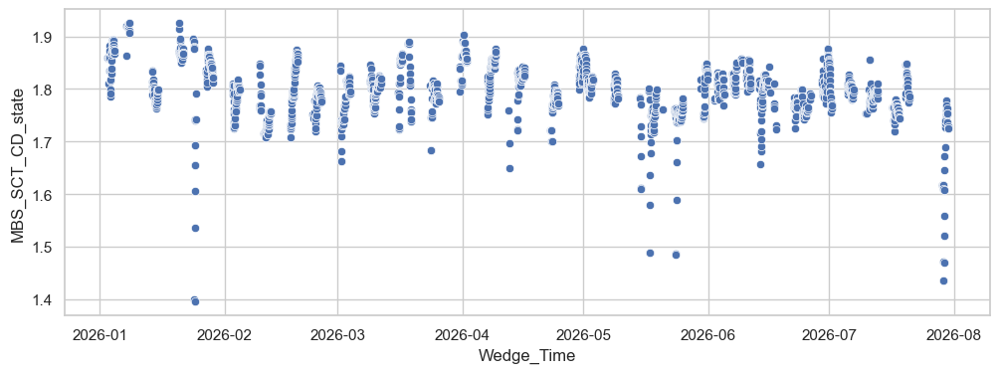

In [38]:
import seaborn as sns

sns.set(rc={"figure.figsize":(12, 4)})
sns.set_style('whitegrid')
sns.set_context('notebook')

sns.scatterplot(tables["process"], x="Wedge_Time", y= "MBS_SCT_CD_state")

In [27]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "start": "2026-07-01",
    "end": "2026-08-10",
    "variables": "MBS_SCT_CD,Combined_cost__€/T_",
}, endpoint="process-data/parquet")

tables["process"].tail()

Calling: http://127.0.0.1:5000/process-data/parquet
Response format: parquet
HTTP status: 200


,Wedge_Time,AB_Grade_ID,MBS_Current_reel_ID,MBS_SCT_CD,Combined_cost__€/T_
246,2026-08-07 05:34:00,6010120,12605564,2.30,278.289368
247,2026-08-07 06:30:00,6010120,12605565,2.30,276.108978
248,2026-08-07 07:27:00,6010120,12605566,2.24,277.024231
249,2026-08-07 08:23:00,6010120,12605567,2.30,275.777405
250,2026-08-07 09:19:00,6010120,12605568,2.28,265.158722


In [22]:
import pandas as pd

### Grouped Process Data

#### Weekly cost grouped by grade. Output format JSON

In [11]:
params = {
    "y_variable_summary": 'Chemicals__€/T_',
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    # "grades": [
    #     "3300110",
    #     "6010100",
    # ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
6037,2026-03-05T19:54:00,12601665,6010085,1.70,3.11,220.610001,0.0,767.380615,1342.397705,39053.671875,...,1.333334,0.0,3.082,1.676,218.382004,0.0,historic,10,3,2026
6038,2026-03-05T20:00:00,12601666,6010085,1.70,3.11,220.610001,0.0,767.355469,1342.872314,3928.125488,...,1.333334,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026
6039,2026-03-05T20:20:00,12601667,6010085,1.70,3.11,220.610001,0.0,768.282104,1341.722290,2170.519043,...,1.333334,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026
6040,2026-03-05T21:30:00,12601668,6010085,1.70,3.11,220.610001,0.0,747.231201,1320.777100,47892.410156,...,1.333334,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026
6041,2026-03-05T22:33:00,12601669,6010085,1.69,3.00,208.429993,0.0,747.462830,1320.692871,48490.164062,...,1.200001,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Chemicals__€/T_,n
0,2026,9,3200115,8.009963,12
1,2026,9,3300120,7.614721,5
2,2026,9,6010120,2.589042,8
3,2026,10,3200115,8.068631,32
4,2026,10,3300100,7.873400,12


metadata
{'color_map': {'3200115': 'rgb(235, 206, 57)', '3300100': 'rgb(42, 184, 232)', '3300110': 'rgb(164, 252, 59)', '3300115': 'rgb(248, 127, 33)', '3300120': 'rgb(207, 48, 5)', '6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(69, 105, 220)', '6010100': 'rgb(51, 240, 151)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 68, 'prepared_rows': 1563, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'3200115': 'rgb(235, 206, 57)', '3300100': 'rgb(42, 184, 232)', '3300110': 'rgb(164, 252, 59)', '3300115': 'rgb(248, 127, 33)', '3300120': 'rgb(207, 48, 5)', '6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(69, 105, 220)', '6010100': 'rgb(51, 240, 151)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 68, 'prepared_rows': 1563, 'x_variable': 'Wedge_Week'}


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
6037,2026-03-05T19:54:00,12601665,6010085,1.70,3.11,220.610001,0.0,767.380615,1342.397705,39053.671875,...,1.333334,0.0,3.082,1.676,218.382004,0.0,historic,10,3,2026
6038,2026-03-05T20:00:00,12601666,6010085,1.70,3.11,220.610001,0.0,767.355469,1342.872314,3928.125488,...,1.333334,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026
6039,2026-03-05T20:20:00,12601667,6010085,1.70,3.11,220.610001,0.0,768.282104,1341.722290,2170.519043,...,1.333334,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026
6040,2026-03-05T21:30:00,12601668,6010085,1.70,3.11,220.610001,0.0,747.231201,1320.777100,47892.410156,...,1.333334,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026
6041,2026-03-05T22:33:00,12601669,6010085,1.69,3.00,208.429993,0.0,747.462830,1320.692871,48490.164062,...,1.200001,0.0,3.110,1.700,220.610001,0.0,historic,10,3,2026


,Wedge_Year,Wedge_Week,AB_Grade_ID,Chemicals__€/T_,n
0,2026,9,3200115,8.009963,12
1,2026,9,3300120,7.614721,5
2,2026,9,6010120,2.589042,8
3,2026,10,3200115,8.068631,32
4,2026,10,3300100,7.873400,12


In [13]:
params = {
    "y_variable_summary": ['Retention_Aid__€/T_','Bentonite_1__€/T_','Bentonite_2__€/T_','Fixative_2__€/T_','Deaerator__€/T_','Defoamer__€/T_','Sizing_Agent__€/T_','Dry_Strength_Agent__€/T_','Natriumhydroxide__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value
0,12601627,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.818197
1,12601628,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.837838
2,12601629,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.826997
3,12601630,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.942323
4,12601631,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.821229


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n
0,2026,9,6010120,Bentonite_1__€/T_,0.496846,8
1,2026,9,6010120,Bentonite_2__€/T_,0.354889,8
2,2026,9,6010120,Deaerator__€/T_,0.208141,8
3,2026,9,6010120,Defoamer__€/T_,0.317024,8
4,2026,9,6010120,Dry_Strength_Agent__€/T_,0.000000,8


metadata
{'color_map': {'Bentonite_1__€/T_': '#EF553B', 'Bentonite_2__€/T_': '#00CC96', 'Deaerator__€/T_': '#FFA15A', 'Defoamer__€/T_': '#19D3F3', 'Dry_Strength_Agent__€/T_': '#B6E880', 'Fixative_2__€/T_': '#AB63FA', 'Natriumhydroxide__€/T_': '#FF97FF', 'Retention_Aid__€/T_': '#636EFA', 'Sizing_Agent__€/T_': '#FF6692'}, 'color_variable': 'variable', 'grouped_rows': 162, 'prepared_rows': 6489, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'Bentonite_1__€/T_': '#EF553B', 'Bentonite_2__€/T_': '#00CC96', 'Deaerator__€/T_': '#FFA15A', 'Defoamer__€/T_': '#19D3F3', 'Dry_Strength_Agent__€/T_': '#B6E880', 'Fixative_2__€/T_': '#AB63FA', 'Natriumhydroxide__€/T_': '#FF97FF', 'Retention_Aid__€/T_': '#636EFA', 'Sizing_Agent__€/T_': '#FF6692'}, 'color_variable': 'variable', 'grouped_rows': 162, 'prepared_rows': 6489, 'x_variable': 'Wedge_Week'}


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value
0,12601627,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.818197
1,12601628,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.837838
2,12601629,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.826997
3,12601630,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.942323
4,12601631,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.821229


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n
0,2026,9,6010120,Bentonite_1__€/T_,0.496846,8
1,2026,9,6010120,Bentonite_2__€/T_,0.354889,8
2,2026,9,6010120,Deaerator__€/T_,0.208141,8
3,2026,9,6010120,Defoamer__€/T_,0.317024,8
4,2026,9,6010120,Dry_Strength_Agent__€/T_,0.000000,8


In [7]:
params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
5999,2026-03-04T04:16:00,12601627,6010100,2.040,4.000,279.570007,159.584442,835.982788,1329.924194,49270.425781,...,2.533333e+00,0.0,3.880,2.070,277.000000,191.000000,historic,10,3,2026
6000,2026-03-04T05:09:00,12601628,6010100,1.841,3.607,248.931000,159.584442,835.799744,1329.942383,44172.230469,...,0.000000e+00,0.0,4.000,2.040,279.570007,159.584442,historic,10,3,2026
6001,2026-03-04T06:01:00,12601629,6010100,1.850,3.410,249.259995,160.000000,836.395752,1329.831665,47961.750000,...,3.178914e-07,0.0,3.607,1.841,248.931000,159.584442,historic,10,3,2026
6002,2026-03-04T06:43:00,12601630,6010100,1.850,3.410,249.259995,160.000000,836.425659,1329.816040,34768.722656,...,3.178914e-07,0.0,3.410,1.850,249.259995,160.000000,historic,10,3,2026
6003,2026-03-04T07:54:00,12601631,6010100,1.843,3.657,246.232010,156.000000,836.655884,1330.145874,48760.382812,...,0.000000e+00,0.0,3.410,1.850,249.259995,160.000000,historic,10,3,2026


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Combined_cost__€/T_,n
0,2026,9,6010120,277.819366,8
1,2026,10,6010100,50291.265625,30
2,2026,10,6010120,5115.422852,62
3,2026,11,6010100,37328.226562,18
4,2026,11,6010120,19004.732422,89


metadata
{'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 18, 'prepared_rows': 721, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 18, 'prepared_rows': 721, 'x_variable': 'Wedge_Week'}


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
5999,2026-03-04T04:16:00,12601627,6010100,2.040,4.000,279.570007,159.584442,835.982788,1329.924194,49270.425781,...,2.533333e+00,0.0,3.880,2.070,277.000000,191.000000,historic,10,3,2026
6000,2026-03-04T05:09:00,12601628,6010100,1.841,3.607,248.931000,159.584442,835.799744,1329.942383,44172.230469,...,0.000000e+00,0.0,4.000,2.040,279.570007,159.584442,historic,10,3,2026
6001,2026-03-04T06:01:00,12601629,6010100,1.850,3.410,249.259995,160.000000,836.395752,1329.831665,47961.750000,...,3.178914e-07,0.0,3.607,1.841,248.931000,159.584442,historic,10,3,2026
6002,2026-03-04T06:43:00,12601630,6010100,1.850,3.410,249.259995,160.000000,836.425659,1329.816040,34768.722656,...,3.178914e-07,0.0,3.410,1.850,249.259995,160.000000,historic,10,3,2026
6003,2026-03-04T07:54:00,12601631,6010100,1.843,3.657,246.232010,156.000000,836.655884,1330.145874,48760.382812,...,0.000000e+00,0.0,3.410,1.850,249.259995,160.000000,historic,10,3,2026


,Wedge_Year,Wedge_Week,AB_Grade_ID,Combined_cost__€/T_,n
0,2026,9,6010120,277.819366,8
1,2026,10,6010100,50291.265625,30
2,2026,10,6010120,5115.422852,62
3,2026,11,6010100,37328.226562,18
4,2026,11,6010120,19004.732422,89


#### Weekly cost grouped by grade. Output format zipped parquet files

In [9]:
params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "parquet",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: parquet
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_width,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
0,2026-03-04 01:15:00,3.57,1.82,245.300003,160.103546,12601627,6010100,834.500000,1312.362305,755.239624,...,2.070923e-02,0.0,4.00,2.04,279.570007,188.000000,historic,10,3,2026
1,2026-03-04 02:08:00,3.41,1.85,249.259995,160.000000,12601628,6010100,835.700012,1329.994385,755.152832,...,3.178914e-07,0.0,3.57,1.82,245.300003,160.103546,historic,10,3,2026
2,2026-03-04 03:41:00,3.66,1.84,243.610001,156.000000,12601630,6010100,836.299988,1329.868286,755.178040,...,0.000000e+00,0.0,3.41,1.85,249.259995,160.000000,historic,10,3,2026
3,2026-03-04 04:53:00,3.53,1.77,254.270004,156.000000,12601631,6010100,836.700012,1330.050903,755.260376,...,0.000000e+00,0.0,3.66,1.84,243.610001,156.000000,historic,10,3,2026
4,2026-03-04 05:46:00,3.56,1.84,257.829987,159.000000,12601632,6010100,837.200012,1329.794312,754.762268,...,0.000000e+00,0.0,3.53,1.77,254.270004,156.000000,historic,10,3,2026


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Combined_cost__€/T_,n
0,2026,9,6010120,276.028961,9
1,2026,10,6010100,283.660553,18
2,2026,10,6010120,274.311646,45
3,2026,11,6010100,281.559265,15
4,2026,11,6010120,275.498901,71


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 564, 'grouped_rows': 18}
Grouped process-data metadata:
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 564, 'grouped_rows': 18}


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_width,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
0,2026-03-04 01:15:00,3.57,1.82,245.300003,160.103546,12601627,6010100,834.500000,1312.362305,755.239624,...,2.070923e-02,0.0,4.00,2.04,279.570007,188.000000,historic,10,3,2026
1,2026-03-04 02:08:00,3.41,1.85,249.259995,160.000000,12601628,6010100,835.700012,1329.994385,755.152832,...,3.178914e-07,0.0,3.57,1.82,245.300003,160.103546,historic,10,3,2026
2,2026-03-04 03:41:00,3.66,1.84,243.610001,156.000000,12601630,6010100,836.299988,1329.868286,755.178040,...,0.000000e+00,0.0,3.41,1.85,249.259995,160.000000,historic,10,3,2026
3,2026-03-04 04:53:00,3.53,1.77,254.270004,156.000000,12601631,6010100,836.700012,1330.050903,755.260376,...,0.000000e+00,0.0,3.66,1.84,243.610001,156.000000,historic,10,3,2026
4,2026-03-04 05:46:00,3.56,1.84,257.829987,159.000000,12601632,6010100,837.200012,1329.794312,754.762268,...,0.000000e+00,0.0,3.53,1.77,254.270004,156.000000,historic,10,3,2026


,Wedge_Year,Wedge_Week,AB_Grade_ID,Combined_cost__€/T_,n
0,2026,9,6010120,276.028961,9
1,2026,10,6010100,283.660553,18
2,2026,10,6010120,274.311646,45
3,2026,11,6010100,281.559265,15
4,2026,11,6010120,275.498901,71


#### Daily SCT CD

In [10]:
params = {
    "y_variable_summary": "MBS_SCT_CD",
    "x_variable_summary": "day",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_width,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3122,2026-03-04T01:15:00,3.57,1.82,245.300003,160.103546,12601627,6010100,834.500000,1312.362305,755.239624,...,2.070923e-02,0.0,4.00,2.04,279.570007,188.000000,historic,10,3,2026
3123,2026-03-04T02:08:00,3.41,1.85,249.259995,160.000000,12601628,6010100,835.700012,1329.994385,755.152832,...,3.178914e-07,0.0,3.57,1.82,245.300003,160.103546,historic,10,3,2026
3124,2026-03-04T03:41:00,3.66,1.84,243.610001,156.000000,12601630,6010100,836.299988,1329.868286,755.178040,...,0.000000e+00,0.0,3.41,1.85,249.259995,160.000000,historic,10,3,2026
3125,2026-03-04T04:53:00,3.53,1.77,254.270004,156.000000,12601631,6010100,836.700012,1330.050903,755.260376,...,0.000000e+00,0.0,3.66,1.84,243.610001,156.000000,historic,10,3,2026
3126,2026-03-04T05:46:00,3.56,1.84,257.829987,159.000000,12601632,6010100,837.200012,1329.794312,754.762268,...,0.000000e+00,0.0,3.53,1.77,254.270004,156.000000,historic,10,3,2026


grouped


,Wedge_Date,AB_Grade_ID,MBS_SCT_CD,n
0,2026-03-01,6010120,2.133333,9
1,2026-03-02,6010120,2.143500,20
2,2026-03-03,6010120,2.133182,22
3,2026-03-04,6010100,1.849000,10
4,2026-03-04,6010120,2.040000,1


metadata
{'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 45, 'prepared_rows': 564, 'x_variable': 'Wedge_Date'}
Grouped process-data metadata:
{'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 45, 'prepared_rows': 564, 'x_variable': 'Wedge_Date'}


,Wedge_Date,AB_Grade_ID,MBS_SCT_CD,n
0,2026-03-01,6010120,2.133333,9
1,2026-03-02,6010120,2.143500,20
2,2026-03-03,6010120,2.133182,22
3,2026-03-04,6010100,1.849000,10
4,2026-03-04,6010120,2.040000,1


#### Average SCT CD by grade

In [11]:
params = {
    "y_variable_summary": "MBS_SCT_CD",
    "x_variable_summary": "grade",
    "color_variable_summary": None,
    "grades": [
        "6010120",
        "6010100",
        "6010085",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

dfg = tables["grouped"]

display(dfg)

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_width,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3145,2026-03-05T16:53:00,3.11,1.70,220.610001,0.0,12601665,6010085,768.799988,1342.456299,753.462524,...,1.333334,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3146,2026-03-05T18:29:00,3.00,1.69,208.429993,0.0,12601668,6010085,748.299988,1320.941895,753.104858,...,1.200001,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3147,2026-03-05T19:35:00,2.93,1.55,203.259995,0.0,12601670,6010085,746.400024,1320.933350,753.666687,...,0.000000,0.0,3.00,1.69,208.429993,0.0,historic,10,3,2026
3148,2026-03-05T21:33:00,2.90,1.56,213.360001,0.0,12601672,6010085,746.900024,1322.733276,752.766663,...,0.000000,0.0,2.93,1.55,203.259995,0.0,historic,10,3,2026
3149,2026-03-05T22:44:00,2.96,1.57,206.639999,0.0,12601673,6010085,747.700012,1320.442871,752.854004,...,0.000000,0.0,2.90,1.56,213.360001,0.0,historic,10,3,2026


grouped


,AB_Grade_ID,grammage,paper_type,MBS_SCT_CD,n
0,6010085,85,6010,1.555303,198
1,6010100,100,6010,1.878392,143
2,6010120,120,6010,2.159905,421


metadata
{'color_map': None, 'color_variable': None, 'grouped_rows': 3, 'prepared_rows': 762, 'x_variable': 'AB_Grade_ID'}
Grouped process-data metadata:
{'color_map': None, 'color_variable': None, 'grouped_rows': 3, 'prepared_rows': 762, 'x_variable': 'AB_Grade_ID'}


,AB_Grade_ID,grammage,paper_type,MBS_SCT_CD,n
0,6010085,85,6010,1.555303,198
1,6010100,100,6010,1.878392,143
2,6010120,120,6010,2.159905,421


#### Monthly steam values by grade

In [ ]:
params = {
    "y_variable_summary": "Steam__€/T_",
    "x_variable_summary": "month",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "parquet",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

monthly_steam = tables["grouped"]

display(monthly_steam)

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: parquet
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_width,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
0,2026-03-04 01:15:00,3.57,1.82,245.300003,160.41832,12601627,6010100,834.500000,1312.362305,755.239624,...,8.366394e-02,0.0,4.00,2.04,279.570007,188.00000,historic,10,3,2026
1,2026-03-04 02:08:00,3.41,1.85,249.259995,160.00000,12601628,6010100,835.700012,1329.994385,755.152832,...,3.178914e-07,0.0,3.57,1.82,245.300003,160.41832,historic,10,3,2026
2,2026-03-04 03:41:00,3.66,1.84,243.610001,156.00000,12601630,6010100,836.299988,1329.868286,755.178040,...,0.000000e+00,0.0,3.41,1.85,249.259995,160.00000,historic,10,3,2026
3,2026-03-04 04:53:00,3.53,1.77,254.270004,156.00000,12601631,6010100,836.700012,1330.050903,755.260376,...,0.000000e+00,0.0,3.66,1.84,243.610001,156.00000,historic,10,3,2026
4,2026-03-04 05:46:00,3.56,1.84,257.829987,159.00000,12601632,6010100,837.200012,1329.794312,754.762268,...,0.000000e+00,0.0,3.53,1.77,254.270004,156.00000,historic,10,3,2026


grouped


,Wedge_Year,Wedge_Month,AB_Grade_ID,Steam__€/T_,n
0,2026,3,6010100,90.437309,71
1,2026,3,6010120,87.173737,243
2,2026,4,6010100,90.061043,72
3,2026,4,6010120,86.965851,178


metadata
{'x_variable': 'Wedge_Month', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 564, 'grouped_rows': 4}
Grouped process-data metadata:
{'x_variable': 'Wedge_Month', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 564, 'grouped_rows': 4}


,Wedge_Year,Wedge_Month,AB_Grade_ID,Steam__€/T_,n
0,2026,3,6010100,90.437309,71
1,2026,3,6010120,87.173737,243
2,2026,4,6010100,90.061043,72
3,2026,4,6010120,86.965851,178


#### Several cost components by week

In [ ]:
params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "agg_cost_label": "Cost__€/T_",
    "grades": [
        "6010120",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "parquet",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())


Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: parquet
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,cost,Cost__€/T_
0,12601557,2026,9,120,6010,Steam__€/T_,87.910088
1,12601558,2026,9,120,6010,Steam__€/T_,89.011719
2,12601559,2026,9,120,6010,Steam__€/T_,89.169189
3,12601561,2026,9,120,6010,Steam__€/T_,87.941727
4,12601562,2026,9,120,6010,Steam__€/T_,88.952446


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,2.503417,9
1,2026,9,Electricity__€/T_,33.065804,9
2,2026,9,Fibre_cost__€/T_,127.054932,9
3,2026,9,Starch__€/T_,25.119965,9
4,2026,9,Steam__€/T_,88.284607,9


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2105, 'grouped_rows': 50}
Grouped process-data metadata:
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2105, 'grouped_rows': 50}


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,cost,Cost__€/T_
0,12601557,2026,9,120,6010,Steam__€/T_,87.910088
1,12601558,2026,9,120,6010,Steam__€/T_,89.011719
2,12601559,2026,9,120,6010,Steam__€/T_,89.169189
3,12601561,2026,9,120,6010,Steam__€/T_,87.941727
4,12601562,2026,9,120,6010,Steam__€/T_,88.952446


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,2.503417,9
1,2026,9,Electricity__€/T_,33.065804,9
2,2026,9,Fibre_cost__€/T_,127.054932,9
3,2026,9,Starch__€/T_,25.119965,9
4,2026,9,Steam__€/T_,88.284607,9


#### Cost components by week and grade

In [ ]:
params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "cost_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

dfg = tables["grouped"]

display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,cost,Cost__€/T_
0,12601627,2026,10,6010100,100,6010,Steam__€/T_,90.962654
1,12601628,2026,10,6010100,100,6010,Steam__€/T_,93.258469
2,12601630,2026,10,6010100,100,6010,Steam__€/T_,92.164047
3,12601631,2026,10,6010100,100,6010,Steam__€/T_,93.736633
4,12601632,2026,10,6010100,100,6010,Steam__€/T_,94.090134


grouped


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,6010120,2.503417,9
1,2026,9,Electricity__€/T_,6010120,33.065804,9
2,2026,9,Fibre_cost__€/T_,6010120,127.054932,9
3,2026,9,Starch__€/T_,6010120,25.119965,9
4,2026,9,Steam__€/T_,6010120,88.284607,9


metadata
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': ['cost', 'AB_Grade_ID'], 'grouped_rows': 90, 'prepared_rows': 2820, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': ['cost', 'AB_Grade_ID'], 'grouped_rows': 90, 'prepared_rows': 2820, 'x_variable': 'Wedge_Week'}


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,6010120,2.503417,9
1,2026,9,Electricity__€/T_,6010120,33.065804,9
2,2026,9,Fibre_cost__€/T_,6010120,127.054932,9
3,2026,9,Starch__€/T_,6010120,25.119965,9
4,2026,9,Steam__€/T_,6010120,88.284607,9


#### Overprocessing by week

In [ ]:
params = {
    "y_variable_summary": "Overprocessing_percentage",
    "x_variable_summary": "week",
    "color_variable_summary": "overprocessing",
    "grades": [
        "6010120",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,cost,Overprocessing_percentage
0,12601557,2026,9,120,6010,SCT_CD,3.414629
1,12601558,2026,9,120,6010,SCT_CD,2.439020
2,12601559,2026,9,120,6010,SCT_CD,2.926824
3,12601561,2026,9,120,6010,SCT_CD,6.341467
4,12601562,2026,9,120,6010,SCT_CD,1.463411


grouped


,Wedge_Year,Wedge_Week,cost,Overprocessing_percentage,n
0,2026,9,Burst,NaN,9
1,2026,9,CMT30,5.534924,9
2,2026,9,SCT_CD,4.065041,9
3,2026,10,Burst,NaN,45
4,2026,10,CMT30,5.227105,45


metadata
{'color_map': {'Burst': '#EF553B', 'CMT30': '#00CC96', 'SCT_CD': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 30, 'prepared_rows': 1263, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'Burst': '#EF553B', 'CMT30': '#00CC96', 'SCT_CD': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 30, 'prepared_rows': 1263, 'x_variable': 'Wedge_Week'}


,Wedge_Year,Wedge_Week,cost,Overprocessing_percentage,n
0,2026,9,Burst,NaN,9
1,2026,9,CMT30,5.534924,9
2,2026,9,SCT_CD,4.065041,9
3,2026,10,Burst,NaN,45
4,2026,10,CMT30,5.227105,45


#### Overprocessing by week and grade

In [ ]:
params = {
    "y_variable_summary": "Overprocessing_percentage",
    "x_variable_summary": "week",
    "color_variable_summary": "overprocessing_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "parquet",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

overprocessing_by_grade = tables["grouped"]

display(overprocessing_by_grade.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: parquet
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,cost,Overprocessing_percentage
0,12601627,2026,10,6010100,100,6010,SCT_CD,7.058827
1,12601628,2026,10,6010100,100,6010,SCT_CD,8.823531
2,12601630,2026,10,6010100,100,6010,SCT_CD,8.235296
3,12601631,2026,10,6010100,100,6010,SCT_CD,4.117646
4,12601632,2026,10,6010100,100,6010,SCT_CD,8.235296


grouped


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Overprocessing_percentage,n
0,2026,9,Burst,6010120,NaN,9
1,2026,9,CMT30,6010120,5.534924,9
2,2026,9,SCT_CD,6010120,4.065041,9
3,2026,10,Burst,6010100,NaN,18
4,2026,10,Burst,6010120,NaN,45


metadata
{'x_variable': 'Wedge_Week', 'color_variable': ['cost', 'AB_Grade_ID'], 'color_map': {'SCT_CD': '#636EFA', 'Burst': '#EF553B', 'CMT30': '#00CC96'}, 'prepared_rows': 1692, 'grouped_rows': 54}
Grouped process-data metadata:
{'x_variable': 'Wedge_Week', 'color_variable': ['cost', 'AB_Grade_ID'], 'color_map': {'SCT_CD': '#636EFA', 'Burst': '#EF553B', 'CMT30': '#00CC96'}, 'prepared_rows': 1692, 'grouped_rows': 54}


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Overprocessing_percentage,n
0,2026,9,Burst,6010120,NaN,9
1,2026,9,CMT30,6010120,5.534924,9
2,2026,9,SCT_CD,6010120,4.065041,9
3,2026,10,Burst,6010100,NaN,18
4,2026,10,Burst,6010120,NaN,45


#### Target comparison

In [ ]:
params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "grade",
    "color_variable_summary": "target",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

dfg = tables["grouped"]

display(dfg)

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_width,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3122,2026-03-04T01:15:00,3.57,1.82,245.300003,160.41832,12601627,6010100,834.500000,1312.362305,755.239624,...,8.366394e-02,0.0,4.00,2.04,279.570007,188.00000,historic,10,3,2026
3123,2026-03-04T02:08:00,3.41,1.85,249.259995,160.00000,12601628,6010100,835.700012,1329.994385,755.152832,...,3.178914e-07,0.0,3.57,1.82,245.300003,160.41832,historic,10,3,2026
3124,2026-03-04T03:41:00,3.66,1.84,243.610001,156.00000,12601630,6010100,836.299988,1329.868286,755.178040,...,0.000000e+00,0.0,3.41,1.85,249.259995,160.00000,historic,10,3,2026
3125,2026-03-04T04:53:00,3.53,1.77,254.270004,156.00000,12601631,6010100,836.700012,1330.050903,755.260376,...,0.000000e+00,0.0,3.66,1.84,243.610001,156.00000,historic,10,3,2026
3126,2026-03-04T05:46:00,3.56,1.84,257.829987,159.00000,12601632,6010100,837.200012,1329.794312,754.762268,...,0.000000e+00,0.0,3.53,1.77,254.270004,156.00000,historic,10,3,2026


grouped


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n
1,6010100,historic,100,6010,283.106812,71
3,6010120,historic,120,6010,274.259949,243
0,6010100,current,100,6010,282.564240,72
2,6010120,current,120,6010,274.423828,178


metadata
{'color_map': {'current': 'red', 'historic': 'blue'}, 'color_variable': 'target', 'grouped_rows': 4, 'prepared_rows': 564, 'x_variable': 'AB_Grade_ID'}
Grouped process-data metadata:
{'color_map': {'current': 'red', 'historic': 'blue'}, 'color_variable': 'target', 'grouped_rows': 4, 'prepared_rows': 564, 'x_variable': 'AB_Grade_ID'}


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n
1,6010100,historic,100,6010,283.106812,71
3,6010120,historic,120,6010,274.259949,243
0,6010100,current,100,6010,282.564240,72
2,6010120,current,120,6010,274.423828,178


#### Target and week comparison

In [ ]:
params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "grade",
    "color_variable_summary": "target_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

dfg = tables["grouped"]

display(dfg)

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_width,...,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year,_target_grade
3122,2026-03-04T01:15:00,3.57,1.82,245.300003,160.41832,12601627,6010100,834.500000,1312.362305,755.239624,...,0.0,4.00,2.04,279.570007,188.00000,historic,10,3,2026,historic | 6010100
3123,2026-03-04T02:08:00,3.41,1.85,249.259995,160.00000,12601628,6010100,835.700012,1329.994385,755.152832,...,0.0,3.57,1.82,245.300003,160.41832,historic,10,3,2026,historic | 6010100
3124,2026-03-04T03:41:00,3.66,1.84,243.610001,156.00000,12601630,6010100,836.299988,1329.868286,755.178040,...,0.0,3.41,1.85,249.259995,160.00000,historic,10,3,2026,historic | 6010100
3125,2026-03-04T04:53:00,3.53,1.77,254.270004,156.00000,12601631,6010100,836.700012,1330.050903,755.260376,...,0.0,3.66,1.84,243.610001,156.00000,historic,10,3,2026,historic | 6010100
3126,2026-03-04T05:46:00,3.56,1.84,257.829987,159.00000,12601632,6010100,837.200012,1329.794312,754.762268,...,0.0,3.53,1.77,254.270004,156.00000,historic,10,3,2026,historic | 6010100


grouped


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n
0,6010100,current,100,6010,282.564240,72
1,6010100,historic,100,6010,283.106812,71
2,6010120,current,120,6010,274.423828,178
3,6010120,historic,120,6010,274.259949,243


metadata
{'color_map': {'current | 6010100': 'rgb(33, 226, 181)', 'current | 6010120': 'rgb(122, 4, 2)', 'historic | 6010100': 'rgb(48, 18, 59)', 'historic | 6010120': 'rgb(247, 184, 54)'}, 'color_variable': ['target', 'AB_Grade_ID'], 'grouped_rows': 4, 'prepared_rows': 564, 'x_variable': 'AB_Grade_ID'}
Grouped process-data metadata:
{'color_map': {'current | 6010100': 'rgb(33, 226, 181)', 'current | 6010120': 'rgb(122, 4, 2)', 'historic | 6010100': 'rgb(48, 18, 59)', 'historic | 6010120': 'rgb(247, 184, 54)'}, 'color_variable': ['target', 'AB_Grade_ID'], 'grouped_rows': 4, 'prepared_rows': 564, 'x_variable': 'AB_Grade_ID'}


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n
0,6010100,current,100,6010,282.564240,72
1,6010100,historic,100,6010,283.106812,71
2,6010120,current,120,6010,274.423828,178
3,6010120,historic,120,6010,274.259949,243


In [47]:
params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "y_variable_summary_secondary": "Speed",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "grades": ["6010120"],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "parquet",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: parquet
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,Speed,cost,Cost__€/T_
0,12601557,2026,9,120,6010,1233.976562,Steam__€/T_,87.910088
1,12601558,2026,9,120,6010,1233.992310,Steam__€/T_,89.011719
2,12601559,2026,9,120,6010,1233.961670,Steam__€/T_,89.169189
3,12601561,2026,9,120,6010,1233.871460,Steam__€/T_,87.941727
4,12601562,2026,9,120,6010,1233.918701,Steam__€/T_,88.952446


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,2.503417,9
1,2026,9,Electricity__€/T_,33.065804,9
2,2026,9,Fibre_cost__€/T_,127.054932,9
3,2026,9,Starch__€/T_,25.119965,9
4,2026,9,Steam__€/T_,88.284607,9


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2105, 'grouped_rows': 50}
Grouped process-data metadata:
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2105, 'grouped_rows': 50}


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,Speed,cost,Cost__€/T_
0,12601557,2026,9,120,6010,1233.976562,Steam__€/T_,87.910088
1,12601558,2026,9,120,6010,1233.992310,Steam__€/T_,89.011719
2,12601559,2026,9,120,6010,1233.961670,Steam__€/T_,89.169189
3,12601561,2026,9,120,6010,1233.871460,Steam__€/T_,87.941727
4,12601562,2026,9,120,6010,1233.918701,Steam__€/T_,88.952446


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,2.503417,9
1,2026,9,Electricity__€/T_,33.065804,9
2,2026,9,Fibre_cost__€/T_,127.054932,9
3,2026,9,Starch__€/T_,25.119965,9
4,2026,9,Steam__€/T_,88.284607,9


#### Weekly production

In [ ]:
params = {
    "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3145,2026-03-05T16:53:00,3.11,1.70,220.610001,0.0,12601665,6010085,768.799988,1342.456299,42218.597656,...,1.333334,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3146,2026-03-05T18:29:00,3.00,1.69,208.429993,0.0,12601668,6010085,748.299988,1320.941895,50821.933594,...,1.200001,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3147,2026-03-05T19:35:00,2.93,1.55,203.259995,0.0,12601670,6010085,746.400024,1320.933350,1400.152588,...,0.000000,0.0,3.00,1.69,208.429993,0.0,historic,10,3,2026
3148,2026-03-05T21:33:00,2.90,1.56,213.360001,0.0,12601672,6010085,746.900024,1322.733276,1479.724487,...,0.000000,0.0,2.93,1.55,203.259995,0.0,historic,10,3,2026
3149,2026-03-05T22:44:00,2.96,1.57,206.639999,0.0,12601673,6010085,747.700012,1320.442871,51614.660156,...,0.000000,0.0,2.90,1.56,213.360001,0.0,historic,10,3,2026


grouped


,Wedge_Year,Wedge_Week,Current_reel_weight,n
0,2026,9,1.038808e+06,21
1,2026,10,6.129652e+06,135
2,2026,11,7.438056e+06,162
3,2026,12,5.382280e+06,117
4,2026,13,7.327060e+06,155


metadata
{'color_map': None, 'color_variable': None, 'grouped_rows': 10, 'prepared_rows': 1202, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': None, 'color_variable': None, 'grouped_rows': 10, 'prepared_rows': 1202, 'x_variable': 'Wedge_Week'}


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3145,2026-03-05T16:53:00,3.11,1.70,220.610001,0.0,12601665,6010085,768.799988,1342.456299,42218.597656,...,1.333334,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3146,2026-03-05T18:29:00,3.00,1.69,208.429993,0.0,12601668,6010085,748.299988,1320.941895,50821.933594,...,1.200001,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3147,2026-03-05T19:35:00,2.93,1.55,203.259995,0.0,12601670,6010085,746.400024,1320.933350,1400.152588,...,0.000000,0.0,3.00,1.69,208.429993,0.0,historic,10,3,2026
3148,2026-03-05T21:33:00,2.90,1.56,213.360001,0.0,12601672,6010085,746.900024,1322.733276,1479.724487,...,0.000000,0.0,2.93,1.55,203.259995,0.0,historic,10,3,2026
3149,2026-03-05T22:44:00,2.96,1.57,206.639999,0.0,12601673,6010085,747.700012,1320.442871,51614.660156,...,0.000000,0.0,2.90,1.56,213.360001,0.0,historic,10,3,2026


,Wedge_Year,Wedge_Week,Current_reel_weight,n
0,2026,9,1.038808e+06,21
1,2026,10,6.129652e+06,135
2,2026,11,7.438056e+06,162
3,2026,12,5.382280e+06,117
4,2026,13,7.327060e+06,155


#### Weekly production by grade

In [ ]:
params = {
    "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3145,2026-03-05T16:53:00,3.11,1.70,220.610001,0.0,12601665,6010085,768.799988,1342.456299,42218.597656,...,1.333334,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3146,2026-03-05T18:29:00,3.00,1.69,208.429993,0.0,12601668,6010085,748.299988,1320.941895,50821.933594,...,1.200001,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3147,2026-03-05T19:35:00,2.93,1.55,203.259995,0.0,12601670,6010085,746.400024,1320.933350,1400.152588,...,0.000000,0.0,3.00,1.69,208.429993,0.0,historic,10,3,2026
3148,2026-03-05T21:33:00,2.90,1.56,213.360001,0.0,12601672,6010085,746.900024,1322.733276,1479.724487,...,0.000000,0.0,2.93,1.55,203.259995,0.0,historic,10,3,2026
3149,2026-03-05T22:44:00,2.96,1.57,206.639999,0.0,12601673,6010085,747.700012,1320.442871,51614.660156,...,0.000000,0.0,2.90,1.56,213.360001,0.0,historic,10,3,2026


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n
0,2026,9,3200115,5.157686e+05,10
1,2026,9,3300120,1.039386e+05,2
2,2026,9,6010120,4.191007e+05,9
3,2026,10,3200115,1.041325e+06,22
4,2026,10,3300100,4.385393e+05,10


metadata
{'color_map': {'3200115': 'rgb(254, 155, 45)', '3300100': 'rgb(27, 207, 212)', '3300110': 'rgb(209, 232, 52)', '3300120': 'rgb(217, 56, 6)', '6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(70, 117, 237)', '6010100': 'rgb(97, 252, 108)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 65, 'prepared_rows': 1202, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'3200115': 'rgb(254, 155, 45)', '3300100': 'rgb(27, 207, 212)', '3300110': 'rgb(209, 232, 52)', '3300120': 'rgb(217, 56, 6)', '6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(70, 117, 237)', '6010100': 'rgb(97, 252, 108)', '6010120': 'rgb(122, 4, 2)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 65, 'prepared_rows': 1202, 'x_variable': 'Wedge_Week'}


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3145,2026-03-05T16:53:00,3.11,1.70,220.610001,0.0,12601665,6010085,768.799988,1342.456299,42218.597656,...,1.333334,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3146,2026-03-05T18:29:00,3.00,1.69,208.429993,0.0,12601668,6010085,748.299988,1320.941895,50821.933594,...,1.200001,0.0,3.11,1.70,220.610001,0.0,historic,10,3,2026
3147,2026-03-05T19:35:00,2.93,1.55,203.259995,0.0,12601670,6010085,746.400024,1320.933350,1400.152588,...,0.000000,0.0,3.00,1.69,208.429993,0.0,historic,10,3,2026
3148,2026-03-05T21:33:00,2.90,1.56,213.360001,0.0,12601672,6010085,746.900024,1322.733276,1479.724487,...,0.000000,0.0,2.93,1.55,203.259995,0.0,historic,10,3,2026
3149,2026-03-05T22:44:00,2.96,1.57,206.639999,0.0,12601673,6010085,747.700012,1320.442871,51614.660156,...,0.000000,0.0,2.90,1.56,213.360001,0.0,historic,10,3,2026


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n
0,2026,9,3200115,5.157686e+05,10
1,2026,9,3300120,1.039386e+05,2
2,2026,9,6010120,4.191007e+05,9
3,2026,10,3200115,1.041325e+06,22
4,2026,10,3300100,4.385393e+05,10


In [18]:
params = {
    "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": ["6010120"],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
}

tables, _ = ask_engine(
    params=params,
    endpoint="process-data/grouped",
)

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3070,2026-03-01T15:02:00,4.02,2.12,284.429993,193.184387,12601557,6010120,848.600037,1233.976562,51176.433594,...,0.0,0.0,4.06,2.17,284.910004,0.000000,historic,9,3,2026
3071,2026-03-01T15:41:00,4.24,2.10,299.739990,194.000000,12601558,6010120,847.700012,1233.992310,42418.375000,...,0.0,0.0,4.02,2.12,284.429993,193.184387,historic,9,3,2026
3072,2026-03-01T16:33:00,4.01,2.11,299.190002,197.000000,12601559,6010120,848.100037,1233.961670,51152.792969,...,0.4,0.0,4.24,2.10,299.739990,194.000000,historic,9,3,2026
3073,2026-03-01T17:55:00,4.26,2.18,308.640015,197.000000,12601561,6010120,845.900024,1233.871460,37384.789062,...,0.4,0.0,4.01,2.11,299.190002,197.000000,historic,9,3,2026
3074,2026-03-01T18:58:00,4.01,2.08,301.359985,196.000000,12601562,6010120,847.600037,1233.918701,51806.453125,...,0.2,0.0,4.26,2.18,308.640015,197.000000,historic,9,3,2026


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n
0,2026,9,6010120,4.191007e+05,9
1,2026,10,6010120,2.107627e+06,45
2,2026,11,6010120,3.383949e+06,71
3,2026,12,6010120,2.315046e+06,46
4,2026,13,6010120,2.808287e+06,57


metadata
{'color_map': {'6010120': 'rgb(164, 252, 59)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 10, 'prepared_rows': 421, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'6010120': 'rgb(164, 252, 59)'}, 'color_variable': 'AB_Grade_ID', 'grouped_rows': 10, 'prepared_rows': 421, 'x_variable': 'Wedge_Week'}


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,target,Wedge_Week,Wedge_Month,Wedge_Year
3070,2026-03-01T15:02:00,4.02,2.12,284.429993,193.184387,12601557,6010120,848.600037,1233.976562,51176.433594,...,0.0,0.0,4.06,2.17,284.910004,0.000000,historic,9,3,2026
3071,2026-03-01T15:41:00,4.24,2.10,299.739990,194.000000,12601558,6010120,847.700012,1233.992310,42418.375000,...,0.0,0.0,4.02,2.12,284.429993,193.184387,historic,9,3,2026
3072,2026-03-01T16:33:00,4.01,2.11,299.190002,197.000000,12601559,6010120,848.100037,1233.961670,51152.792969,...,0.4,0.0,4.24,2.10,299.739990,194.000000,historic,9,3,2026
3073,2026-03-01T17:55:00,4.26,2.18,308.640015,197.000000,12601561,6010120,845.900024,1233.871460,37384.789062,...,0.4,0.0,4.01,2.11,299.190002,197.000000,historic,9,3,2026
3074,2026-03-01T18:58:00,4.01,2.08,301.359985,196.000000,12601562,6010120,847.600037,1233.918701,51806.453125,...,0.2,0.0,4.26,2.18,308.640015,197.000000,historic,9,3,2026


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n
0,2026,9,6010120,4.191007e+05,9
1,2026,10,6010120,2.107627e+06,45
2,2026,11,6010120,3.383949e+06,71
3,2026,12,6010120,2.315046e+06,46
4,2026,13,6010120,2.808287e+06,57


## Query

In [9]:
#run_query("show steam cost for grade 6010120 for week 11"),
#run_query("show starch uptake top for grade 6010120 in February"),
#run_query("show starch uptake for grade 6010120 in February"),
#run_query("show SCT CD not overprocessing for grade 6010120 in February"),
#run_query("show starch uptake not top bottom with SCT CD not overprocessing on secondary axis for grade 6010120 in February"),
tables, figures  = run_query("show current basis weight and starch uptake not top bottom in secondary axis for grade 6010120 in week 12")

HTTP status: 200


## Process data

**Grade:** `6010120` 
**Target range:** `(datetime.date(2026, 3, 16), datetime.date(2026, 3, 20))` 

### Requested variables

**Primary axis:** `['Current_basis_weight']` 
**Secondary axis:** `['Starch_uptake__g/m2_']`

In [3]:
import requests

download_artifacts = True
r = requests.post(
    "http://127.0.0.1:5000/ask-card",
    json={
        #"query":  "show steam cost for grade 6010120 for week 11",
        #"query":  "show starch uptake top for grade 6010120 in February",
        #"query":  "show starch uptake for grade 6010120 in February",
        #"query":  "show SCT CD not overprocessing for grade 6010120 in February",
        #"query":  "show starch uptake not top bottom with SCT CD not overprocessing on secondary axis for grade 6010120 in February",
        "query":  "show current basis weight and starch uptake not top bottom in secondary axis for grade 6010120 in week 12",
        "download_artifacts": download_artifacts,
    },
)

out = r.json()

tables, figures = extract(out, download_artifacts, show_tables=True, show_figures=True)

## Process data

**Grade:** `6010120` 
**Target range:** `(datetime.date(2026, 3, 16), datetime.date(2026, 3, 21))` 

### Requested variables

**Primary axis:** `['Current_basis_weight']` 
**Secondary axis:** `['Starch_uptake__g/m2_']`

In [ ]:
import requests

download_artifacts = True
r = requests.post(
    "http://127.0.0.1:5000/ask-card",
    json={
        "query":  "show steam cost for grade 6010120 for week 11",
        "download_artifacts": download_artifacts,
    },
)

out = r.json()

tables, figures = extract(out, download_artifacts, show_tables=True, show_figures=True)

# Shap values

## Raw

In [32]:
tables, figures = ask_engine(params = {
    "target": "SCT CD",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap-values",
run_async=True
)

Calling: http://127.0.0.1:5000/shap-values
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
shap accepted.
Job ID: c070dfe0-5709-440f-973a-9835ff869915
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
shap completed.


## SHAP values

Computed SHAP values for **SCT CD**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `39`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `39`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,retention,0.804948,-0.012817
1,0,Speed,1253.037842,-0.008977
2,0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,0.023548
3,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.033026,0.000215
4,0,MBS_SCT_CD_state,1.821526,0.031650


In [13]:
tables, figures = ask_engine(params = {
    "target": "starch uptake",
    "grade": "3200115",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap-values",
run_async=True
)

Calling: http://127.0.0.1:5000/shap-values
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
shap accepted.
Job ID: 0479bfac-ed0d-4ad6-af5a-556ea9e58e5b
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job status: completed
shap completed.


## SHAP values

Computed SHAP values for **starch uptake**.

- Rows explained: `32`
- Background rows: `200`
- Model features used for computation: `20`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `20`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Moisture_after_SpeedSizer,29.977858,0.083486
1,0,Temperature_starch_working_tank_1,82.561729,0.207198
2,0,Temperature_starch_working_tank_2,76.967590,0.076238
3,0,Retention_Aid_mass_flow__g/T_,172.756134,-0.025646
4,0,concentration_starch_working_tank_1,0.560947,-0.057763


In [93]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "3200115",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap-values")

HTTP status: 200


## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `32`
- Background rows: `200`
- Model features used for computation: `41`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `41`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Speed,1280.927734,-0.890298
1,0,Vacuum_suction_box_9,-0.329887,1.674707
2,0,Vacuum_sheet_seperator_box,-0.309898,1.070605
3,0,ambient_temp_C,6.700000,0.539371
4,0,Vacuum_wet_suction_box,-0.100164,-3.530491


In [4]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "3200115",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 100,
    "background_rows": 100,
    "variables":['Current_basis_weight']
}, endpoint="shap-values")

HTTP status: 500

ERROR RESPONSE
{'blocks': [], 'figures': [], 'raw': None, 'summary_text': None, 'tables': [], 'text': "None of the requested variables are features of this target. Requested=['Current_basis_weight']. Available=['concentration_starch_working_tank_1', 'Speed', 'Vacuum_suction_box_9', 'Vacuum_uhle-box_bottom_felt', 'DG4_Temperature_Inlet_Air', 'Dewatering_top_wire_suction_box_zone_2', 'Dewatering_Shoe_press', 'Starch_uptake_by_paper_Bottom_Roll__g/m2_', 'Vacuum_wire_suction_box_2', 'Dissolved_gas_before_dilution_water_deculator', 'DG1_temperature_Inlet_Air', 'Vacuum_suction_box_10', 'Vacuum_presszone_of_suction-press_roll', 'DG2_temperature_Inlet_Air', 'Dissolved_gas_after_stock_deculator_measurement_1', 'Starch_uptake_by_paper_Top_Roll__g/m2_', 'Current_reel_moisture_average(reel)', 'Free_gas_before_dilution_water_deculator_measurement_1~^0', 'Stock_deculator_pressure', 'Vacuum_sheet_seperator_box', 'Vacuum_wire_suction_box_1', 'Dissolved_gas_after_stock_deculator_measu

In [13]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "6010120",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 100,
    "background_rows": 50
}, endpoint="shap-values")

HTTP status: 200


## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `80`
- Background rows: `50`
- Features: `53`

block_1


,row_id,feature,value,shap_value
0,0,Linepressure_shoe_press__bar_,101.554802,-1.492735
1,0,Linepressure_1st_press_DS__bar_,77.606323,-2.320160
2,0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.545799,4.783944
3,0,Dewatering_top_wire_suction_box_zone_2,1452.620117,-1.265993
4,0,Dissolved_gas_before_dilution_water_deculator,1.101852,10.789784


In [14]:
tables, figures = ask_engine(params = {
    "target": "SCT CD",
    "grade": "6010120",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 100,
    "background_rows": 50
}, endpoint="shap-values")

HTTP status: 200


## SHAP values

Computed SHAP values for **SCT CD**.

- Rows explained: `80`
- Background rows: `50`
- Features: `13`

block_1


,row_id,feature,value,shap_value
0,0,Current_reel_moisture_average(reel),8.243914,-0.000571
1,0,Short_fibre_flow,14684.207031,0.000530
2,0,Long_fibre_consistency_B07,4.863333,-0.000059
3,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.338072,0.007070
4,0,Jet/wire_ratio,-22.521917,0.000173


## Query

In [61]:
#tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April"),
#tables, figures  = run_query("explain model for steam cost for grade 6010120"),
#tables, figures  = run_query("explain model for total cost for grade 6010120 in April"),
#tables, figures  = run_query("explain model for starch cost for grade 6010120 in April"),
#tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April 2026")
tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April 2026")

HTTP status: 200


## SHAP analysis

**Function:** `SCT CD` 
**Grade:** `6010120` 
**Target period:** `2026-04-01` to `2026-05-01` 
**Baseline period:** `2026-04-19` to `2026-05-17` 

### Summary

Computed SHAP values using the selected target period and the baseline period as reference.

block_1


,row_id,feature,value,shap_value
0,0,Current_reel_moisture_average(reel),8.082893,0.003966
1,0,Short_fibre_flow,14699.282227,0.000508
2,0,Long_fibre_consistency_B07,4.839009,-0.000062
3,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.159944,-0.004246
4,0,Jet/wire_ratio,-24.207384,0.006138


# Diagnosis

## Raw

### Description

In [12]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [4],
    "objects": ["cost"],
    "secondary_objects":["steam"],
    "summary": False,
    "output_format": "json",
}, endpoint="diagnosis",run_async=True)

Calling: http://127.0.0.1:5000/diagnosis
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
diagnosis accepted.
Job ID: af8d1220-be16-4dd2-b287-6729b1c06a61
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
diagnosis completed.


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 
**Levels:** `4` 
**Objects:** `cost`

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers** decreased on average (-1.37 €/t).

- **Steam_Afterdryers** decreased on average (-0.78 €/t).

- **Steam_Whitewater** increased on average (+0.44 €/t).

- **Steam_Starchkitchen** decreased on average (-0.06 €/t).

- **Steam_Heatexchangers** decreased on average (-0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Whitewater** (+0.44 €/t on average), with the highest increase in grade 3300120 (+1.17 €/t) and the largest average decrease comes from **Steam_Predryers** (-1.37 €/t on average), with the biggest drop in grade 3300110 (-2.64 €/t). These components stand out and may require further investigation.

main


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,84.537460,152.0,steam,87.048592,-2.511131
1,current,3300100,85.887611,47.0,steam,87.347870,-1.460258
2,current,3300110,83.527687,57.0,steam,86.822311,-3.294624
3,current,3300120,85.078957,23.0,steam,87.861389,-2.782433
4,current,6010085,90.057709,155.0,steam,92.066956,-2.009247


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,84.537460,152.0,steam,87.048592,-2.511131
1,current,3300100,85.887611,47.0,steam,87.347870,-1.460258
2,current,3300110,83.527687,57.0,steam,86.822311,-3.294624
3,current,3300120,85.078957,23.0,steam,87.861389,-2.782433
4,current,6010085,90.057709,155.0,steam,92.066956,-2.009247


In [26]:
tables["diagnosis_table_1"].sort_values(["cost","pct_cost"]).groupby("cost").agg(best = ("AB_Grade_ID","first"), worse = ("AB_Grade_ID","last"))

,best,worse
cost,,
Chemicals__€/T_,3300100,3300120
Electricity__€/T_,3300120,3300110
Fibre_cost__€/T_,6010100,3200115
Starch__€/T_,6010100,3200115
Steam__€/T_,3300110,6010120
TOTAL,6010100,3200115


In [21]:
tables["diagnosis_table_1"].sort_values(["cost","pct_cost"])

,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
8,current,3300100,8.541467,47,Chemicals__€/T_,8.482358,0.059109
7,current,3200115,8.467896,152,Chemicals__€/T_,8.373677,0.094218
12,current,6010100,3.119425,97,Chemicals__€/T_,2.948483,0.170943
13,current,6010120,2.988464,229,Chemicals__€/T_,2.813132,0.175332
11,current,6010085,3.420785,155,Chemicals__€/T_,3.188852,0.231933
9,current,3300110,8.278091,57,Chemicals__€/T_,7.865013,0.413078
10,current,3300120,8.191714,23,Chemicals__€/T_,7.590937,0.600777
17,current,3300120,32.689934,23,Electricity__€/T_,33.054661,-0.364727
18,current,6010085,41.612946,155,Electricity__€/T_,41.804245,-0.191299
14,current,3200115,33.269855,152,Electricity__€/T_,33.410084,-0.140228


In [27]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [3],
    "objects": ["cost"],
    "secondary_objects":["chemicals","steam","electricity"],
    "summary": False
}, endpoint="diagnosis",run_async=True)

Calling: http://127.0.0.1:5000/diagnosis
Mode: asynchronous
Submission response received after 0.05 seconds.
HTTP status: 202
diagnosis accepted.
Job ID: 7a767674-1018-4820-88fe-eca3c0361c41
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
diagnosis completed.


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 
**Levels:** `3` 
**Objects:** `cost`

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw an increase of 148.54 €/t, resulting in 433.96 €/t.

For grade 3300100, TOTAL cost saw an increase of 71.89 €/t, resulting in 353.15 €/t.

For grade 3300110, TOTAL cost saw a decrease of 8.01 €/t, resulting in 278.19 €/t.

For grade 3300120, TOTAL cost saw a decrease of 16.22 €/t, resulting in 275.13 €/t.

For grade 6010085, TOTAL cost saw a decrease of 9.43 €/t, resulting in 291.83 €/t.

For grade 6010100, TOTAL cost saw a decrease of 115.65 €/t, resulting in 292.53 €/t.

For grade 6010120, TOTAL cost saw a decrease of 13.54 €/t, resulting in 274.70 €/t.

Average change by component:

- **Fibre_cost__€/T_** increased on average (+10.21 €/t).

- **Steam__€/T_** decreased on average (-1.86 €/t).

- **Starch__€/T_** decreased on average (-0.44 €/t).

- **Chemicals__€/T_** increased on average (+0.25 €/t).

- **Electricity__€/T_** increased on average (+0.08 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Fibre_cost__€/T_** (+10.21 €/t on average), with the highest increase in grade 3200115 (+150.85 €/t) and the largest average decrease comes from **Steam__€/T_** (-1.86 €/t on average), with the biggest drop in grade 3300110 (-3.29 €/t). These components stand out and may require further investigation.

main


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.959198,152,TOTAL,285.422302,148.536896
1,current,3300100,353.151337,47,TOTAL,281.258850,71.892487
2,current,3300110,278.192841,57,TOTAL,286.203979,-8.011139
3,current,3300120,275.126160,23,TOTAL,291.342194,-16.216034
4,current,6010085,291.831787,155,TOTAL,301.260773,-9.428986


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.959198,152,TOTAL,285.422302,148.536896
1,current,3300100,353.151337,47,TOTAL,281.258850,71.892487
2,current,3300110,278.192841,57,TOTAL,286.203979,-8.011139
3,current,3300120,275.126160,23,TOTAL,291.342194,-16.216034
4,current,6010085,291.831787,155,TOTAL,301.260773,-9.428986


In [23]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-08-02", "2026-09-06"],
    "baseline_range": ["2026-08-02", "2026-08-30"],
    "levels": [1, 2, 3],
    "objects": ["cost"],
    "secondary_objects":["chemicals","steam","electricity"],
    
    "summary": False
}, endpoint="diagnosis",run_async=True)

Calling: http://127.0.0.1:5000/diagnosis
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
diagnosis accepted.
Job ID: d6d8b037-c164-4580-82f1-9fe3cc6b612c
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job status: completed
diagnosis completed.


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-08-02` to `2026-09-06` 
**Baseline period:** `2026-08-02` to `2026-08-30` 
**Levels:** `1, 2, 3` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 3.90 €/t, resulting in 278.33 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+2.24 €/t).

- **Electricity__€/T_** increased on average (+1.75 €/t).

- **Chemicals__€/T_** decreased on average (-1.00 €/t).

- **Starch__€/T_** increased on average (+1.00 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.09 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+2.24 €/t on average), with the highest increase in grade ALL (+2.24 €/t) and the largest average decrease comes from **Chemicals__€/T_** (-1.00 €/t on average), with the biggest drop in grade ALL (-1.00 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +5.39 €/t was driven by a more expensive mix of grades, and -1.49 €/t was due to an improvement in the process.

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw a decrease of 1.67 €/t, resulting in 273.22 €/t.

For grade 3300100, TOTAL cost saw a decrease of 1.87 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.83 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 1.59 €/t, resulting in 275.94 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.01 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.42 €/t, resulting in 279.23 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.35 €/t, resulting in 268.75 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 3300120 (+1.59 €/t) and the strongest cost decrease was observed for grade 3300110 (-3.83 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw a decrease of 1.67 €/t, resulting in 273.22 €/t.

For grade 3300100, TOTAL cost saw a decrease of 1.87 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.83 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 1.59 €/t, resulting in 275.94 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.01 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.42 €/t, resulting in 279.23 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.35 €/t, resulting in 268.75 €/t.

Average change by component:

- **Electricity__€/T_** decreased on average (-0.69 €/t).

- **Chemicals__€/T_** decreased on average (-0.44 €/t).

- **Starch__€/T_** decreased on average (-0.08 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.04 €/t).

- **Steam__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+0.00 €/t on average), with the highest increase in grade 6010100 (+1.80 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.69 €/t on average), with the biggest drop in grade 6010100 (-1.34 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.325365,167,TOTAL,274.425695,ALL,3.899671,5.394615,-1.494944
1,current,4.676292,167,Chemicals__€/T_,5.680382,ALL,-1.004090,-0.696067,-0.308023
2,current,38.228279,167,Electricity__€/T_,36.477971,ALL,1.750308,2.392979,-0.642671
3,current,127.928744,167,Fibre_cost__€/T_,128.013822,ALL,-0.085078,-0.074097,-0.010981
4,current,23.100635,167,Starch__€/T_,22.098358,ALL,1.002277,1.071202,-0.068926


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.325365,167,TOTAL,274.425695,ALL,3.899671,5.394615,-1.494944
1,current,4.676292,167,Chemicals__€/T_,5.680382,ALL,-1.004090,-0.696067,-0.308023
2,current,38.228279,167,Electricity__€/T_,36.477971,ALL,1.750308,2.392979,-0.642671
3,current,127.928744,167,Fibre_cost__€/T_,128.013822,ALL,-0.085078,-0.074097,-0.010981
4,current,23.100635,167,Starch__€/T_,22.098358,ALL,1.002277,1.071202,-0.068926


diagnosis_table_2


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,273.223861,23,TOTAL,274.890315,-1.666454
1,current,3300100,275.027462,18,TOTAL,276.901691,-1.874229
2,current,3300110,272.109181,6,TOTAL,275.934372,-3.825190
3,current,3300120,275.941559,5,TOTAL,274.350651,1.590908
4,current,6010085,286.942997,62,TOTAL,288.956497,-2.013500


diagnosis_table_3


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,273.223861,23,TOTAL,274.890315,-1.666454
1,current,3300100,275.027462,18,TOTAL,276.901691,-1.874229
2,current,3300110,272.109181,6,TOTAL,275.934372,-3.825190
3,current,3300120,275.941559,5,TOTAL,274.350651,1.590908
4,current,6010085,286.942997,62,TOTAL,288.956497,-2.013500


In [28]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-08-02", "2026-09-06"],
    "baseline_range": ["2026-08-02", "2026-08-30"],
    "levels": [3,4],
    "objects": ["consumption"],
    "secondary_objects":["chemicals","steam","electricity"],
    
    "summary": False
}, endpoint="diagnosis",run_async=True)

Calling: http://127.0.0.1:5000/diagnosis
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
diagnosis accepted.
Job ID: 8c9a5812-9fe0-4507-be6c-8757001cbf8b
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
diagnosis completed.


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-08-02` to `2026-09-06` 
**Baseline period:** `2026-08-02` to `2026-08-30` 
**Levels:** `3, 4` 
**Objects:** `consumption`

### Consumption diagnosis — By component

Average change by component:

- **Electricity__kWh/T_** decreased on average (-6.02).

- **Steam__kWh/T_** decreased on average (-0.65).

- **Starch_mass_flow__kg/T_** decreased on average (-0.18).

- **Fibre_usage__T/T_** decreased on average (-0.00).

A more detailed breakdown by component shows that the largest average decrease comes from **Electricity__kWh/T_** (-6.02 on average), with the biggest drop in grade 6010100 (-11.75). These components stand out and may require further investigation.

### Consumption diagnosis — Chemicals breakdown

Average change by component:

- **Fixative_2_mass_flow__g/T_** decreased on average (-140.24).

- **Natriumhydroxide_mass_flow__g/T_** increased on average (+106.39).

- **Defoamer_mass_flow__g/T_** increased on average (+22.96).

- **Retention_Aid_mass_flow__g/T_** decreased on average (-21.81).

- **Sizing_Agent__g/T_** increased on average (+16.69).

- **Act_Deaerator_mass_flow__g/T_** decreased on average (-5.04).

- **Bentonite_1_mass_flow__g/T_** decreased on average (-5.00).

- **Bentonite_2_mass_flow__g/T_** increased on average (+0.73).

A more detailed breakdown by component shows that the largest average increase comes from **Natriumhydroxide_mass_flow__g/T_** (+106.39 on average), with the highest increase in grade 3300100 (+238.52) and the largest average decrease comes from **Fixative_2_mass_flow__g/T_** (-140.24 on average), with the biggest drop in grade 3300120 (-326.09). These components stand out and may require further investigation.

### Consumption diagnosis — Steam breakdown

Average change by component:

- **Steam_Predryers__kWh/T_** increased on average (+43.29).

- **Steam_Afterdryers__kWh/T_** decreased on average (-13.07).

- **Steam_Whitewater__kWh/T_** decreased on average (-11.53).

- **Steam_Starchkitchen__kWh/T_** increased on average (+0.21).

- **Steam_Heatexchangers__kWh/T_** increased on average (+0.20).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__kWh/T_** (+43.29 on average), with the highest increase in grade 3300110 (+70.81) and the largest average decrease comes from **Steam_Afterdryers__kWh/T_** (-13.07 on average), with the biggest drop in grade 6010120 (-25.46). These components stand out and may require further investigation.

### Consumption diagnosis — Electricity breakdown

Average change by component:

- **Electricity_Predryer__kWh/T_** increased on average (+10.64).

- **Electricity_Afterdryer__kWh/T_** increased on average (+9.90).

- **Electricity_Freqconverters__kWh/T_** increased on average (+9.76).

- **Electricity_Specific__kWh/T_** increased on average (+9.19).

- **Electricity_Wiresection__kWh/T_** increased on average (+8.58).

- **Electricity_Other__kWh/T_** increased on average (+5.97).

- **Electricity_Press_and_Steambox__kWh/T_** increased on average (+0.35).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__kWh/T_** (+10.64 on average), with the highest increase in grade 6010085 (+1076.08). These components stand out and may require further investigation.

main


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity__kWh/T_,3200115,310.549184,23.0,316.495681,-5.946497
1,current,Electricity__kWh/T_,3300100,322.348467,18.0,331.398688,-9.050222
2,current,Electricity__kWh/T_,3300110,312.423345,6.0,323.445398,-11.022053
3,current,Electricity__kWh/T_,3300120,310.299426,5.0,307.772911,2.526515
4,current,Electricity__kWh/T_,6010085,371.594411,62.0,375.874563,-4.280152


diagnosis_table_1


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity__kWh/T_,3200115,310.549184,23.0,316.495681,-5.946497
1,current,Electricity__kWh/T_,3300100,322.348467,18.0,331.398688,-9.050222
2,current,Electricity__kWh/T_,3300110,312.423345,6.0,323.445398,-11.022053
3,current,Electricity__kWh/T_,3300120,310.299426,5.0,307.772911,2.526515
4,current,Electricity__kWh/T_,6010085,371.594411,62.0,375.874563,-4.280152


... (2 outputs left out)

diagnosis_table_3


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Steam_Afterdryers__kWh/T_,3200115,210.203461,23.0,221.898819,-11.695358
1,current,Steam_Afterdryers__kWh/T_,3300100,231.604355,18.0,229.507935,2.096420
2,current,Steam_Afterdryers__kWh/T_,3300110,208.338501,6.0,224.411148,-16.072647
3,current,Steam_Afterdryers__kWh/T_,3300120,204.900421,5.0,216.977905,-12.077484
4,current,Steam_Afterdryers__kWh/T_,6010085,262.943634,62.0,268.329102,-5.385468


diagnosis_table_4


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity_Afterdryer__kWh/T_,3200115,4.631284,23.0,1230.964233,-1226.332950
1,current,Electricity_Afterdryer__kWh/T_,3300100,6.335592,18.0,6.244821,0.090772
2,current,Electricity_Afterdryer__kWh/T_,3300110,5.469658,6.0,5.556673,-0.087015
3,current,Electricity_Afterdryer__kWh/T_,3300120,4.581418,5.0,5.015018,-0.433601
4,current,Electricity_Afterdryer__kWh/T_,6010085,1083.261597,62.0,7.774942,1075.486654


In [29]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-08-02", "2026-09-06"],
    "baseline_range": ["2026-08-02", "2026-08-30"],
    "levels": [1,2, 3,4],
    "objects": ["cost","consumption"],
    "secondary_objects":["chemicals","steam","electricity"],
    
    "summary": False
}, endpoint="diagnosis",run_async=True)

Calling: http://127.0.0.1:5000/diagnosis
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
diagnosis accepted.
Job ID: dd2820be-8338-4349-bc0d-353ae50ab9c7
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job status: completed
diagnosis completed.


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-08-02` to `2026-09-06` 
**Baseline period:** `2026-08-02` to `2026-08-30` 
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost, consumption`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 3.90 €/t, resulting in 278.33 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+2.24 €/t).

- **Electricity__€/T_** increased on average (+1.75 €/t).

- **Chemicals__€/T_** decreased on average (-1.00 €/t).

- **Starch__€/T_** increased on average (+1.00 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.09 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+2.24 €/t on average), with the highest increase in grade ALL (+2.24 €/t) and the largest average decrease comes from **Chemicals__€/T_** (-1.00 €/t on average), with the biggest drop in grade ALL (-1.00 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +5.39 €/t was driven by a more expensive mix of grades, and -1.49 €/t was due to an improvement in the process.

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw a decrease of 1.67 €/t, resulting in 273.22 €/t.

For grade 3300100, TOTAL cost saw a decrease of 1.87 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.83 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 1.59 €/t, resulting in 275.94 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.01 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.42 €/t, resulting in 279.23 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.35 €/t, resulting in 268.75 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 3300120 (+1.59 €/t) and the strongest cost decrease was observed for grade 3300110 (-3.83 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw a decrease of 1.67 €/t, resulting in 273.22 €/t.

For grade 3300100, TOTAL cost saw a decrease of 1.87 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.83 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 1.59 €/t, resulting in 275.94 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.01 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.42 €/t, resulting in 279.23 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.35 €/t, resulting in 268.75 €/t.

Average change by component:

- **Electricity__€/T_** decreased on average (-0.69 €/t).

- **Chemicals__€/T_** decreased on average (-0.44 €/t).

- **Starch__€/T_** decreased on average (-0.08 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.04 €/t).

- **Steam__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+0.00 €/t on average), with the highest increase in grade 6010100 (+1.80 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.69 €/t on average), with the biggest drop in grade 6010100 (-1.34 €/t). These components stand out and may require further investigation.

### Consumption diagnosis — By component

Average change by component:

- **Electricity__kWh/T_** decreased on average (-6.02).

- **Steam__kWh/T_** decreased on average (-0.65).

- **Starch_mass_flow__kg/T_** decreased on average (-0.18).

- **Fibre_usage__T/T_** decreased on average (-0.00).

A more detailed breakdown by component shows that the largest average decrease comes from **Electricity__kWh/T_** (-6.02 on average), with the biggest drop in grade 6010100 (-11.75). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Fixative_2__€/T_** decreased on average (-0.50 €/t).

- **Defoamer__€/T_** increased on average (+0.10 €/t).

- **Retention_Aid__€/T_** decreased on average (-0.09 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.03 €/t).

- **Sizing_Agent__€/T_** increased on average (+0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.01 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

- **Bentonite_2__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Defoamer__€/T_** (+0.10 €/t on average), with the highest increase in grade 3300110 (+0.18 €/t) and the largest average decrease comes from **Fixative_2__€/T_** (-0.50 €/t on average), with the biggest drop in grade 3300120 (-1.17 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+3.85 €/t).

- **Steam_Afterdryers__€/T_** decreased on average (-1.16 €/t).

- **Steam_Whitewater__€/T_** decreased on average (-1.03 €/t).

- **Steam_Starchkitchen__€/T_** increased on average (+0.02 €/t).

- **Steam_Heatexchangers__€/T_** increased on average (+0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+3.85 €/t on average), with the highest increase in grade 3300110 (+6.30 €/t) and the largest average decrease comes from **Steam_Afterdryers__€/T_** (-1.16 €/t on average), with the biggest drop in grade 6010120 (-2.27 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Predryer__€/T_** increased on average (+1.21 €/t).

- **Electricity_Afterdryer__€/T_** increased on average (+1.13 €/t).

- **Electricity_Freqconverters__€/T_** increased on average (+1.11 €/t).

- **Electricity_Specific__€/T_** increased on average (+1.04 €/t).

- **Electricity_Wiresection__€/T_** increased on average (+0.98 €/t).

- **Electricity_Other__€/T_** increased on average (+0.68 €/t).

- **Electricity_Press_and_Steambox__€/T_** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__€/T_** (+1.21 €/t on average), with the highest increase in grade 6010085 (+122.31 €/t). These components stand out and may require further investigation.

### Consumption diagnosis — Chemicals breakdown

Average change by component:

- **Fixative_2_mass_flow__g/T_** decreased on average (-140.24).

- **Natriumhydroxide_mass_flow__g/T_** increased on average (+106.39).

- **Defoamer_mass_flow__g/T_** increased on average (+22.96).

- **Retention_Aid_mass_flow__g/T_** decreased on average (-21.81).

- **Sizing_Agent__g/T_** increased on average (+16.69).

- **Act_Deaerator_mass_flow__g/T_** decreased on average (-5.04).

- **Bentonite_1_mass_flow__g/T_** decreased on average (-5.00).

- **Bentonite_2_mass_flow__g/T_** increased on average (+0.73).

A more detailed breakdown by component shows that the largest average increase comes from **Natriumhydroxide_mass_flow__g/T_** (+106.39 on average), with the highest increase in grade 3300100 (+238.52) and the largest average decrease comes from **Fixative_2_mass_flow__g/T_** (-140.24 on average), with the biggest drop in grade 3300120 (-326.09). These components stand out and may require further investigation.

### Consumption diagnosis — Steam breakdown

Average change by component:

- **Steam_Predryers__kWh/T_** increased on average (+43.29).

- **Steam_Afterdryers__kWh/T_** decreased on average (-13.07).

- **Steam_Whitewater__kWh/T_** decreased on average (-11.53).

- **Steam_Starchkitchen__kWh/T_** increased on average (+0.21).

- **Steam_Heatexchangers__kWh/T_** increased on average (+0.20).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__kWh/T_** (+43.29 on average), with the highest increase in grade 3300110 (+70.81) and the largest average decrease comes from **Steam_Afterdryers__kWh/T_** (-13.07 on average), with the biggest drop in grade 6010120 (-25.46). These components stand out and may require further investigation.

### Consumption diagnosis — Electricity breakdown

Average change by component:

- **Electricity_Predryer__kWh/T_** increased on average (+10.64).

- **Electricity_Afterdryer__kWh/T_** increased on average (+9.90).

- **Electricity_Freqconverters__kWh/T_** increased on average (+9.76).

- **Electricity_Specific__kWh/T_** increased on average (+9.19).

- **Electricity_Wiresection__kWh/T_** increased on average (+8.58).

- **Electricity_Other__kWh/T_** increased on average (+5.97).

- **Electricity_Press_and_Steambox__kWh/T_** increased on average (+0.35).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__kWh/T_** (+10.64 on average), with the highest increase in grade 6010085 (+1076.08). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.325365,167,TOTAL,274.425702,ALL,3.899663,5.394611,-1.494948
1,current,4.676292,167,Chemicals__€/T_,5.680382,ALL,-1.004090,-0.696067,-0.308023
2,current,38.228279,167,Electricity__€/T_,36.477980,ALL,1.750299,2.392975,-0.642676
3,current,127.928744,167,Fibre_cost__€/T_,128.013820,ALL,-0.085076,-0.074096,-0.010980
4,current,23.100635,167,Starch__€/T_,22.098358,ALL,1.002277,1.071202,-0.068926


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.325365,167,TOTAL,274.425702,ALL,3.899663,5.394611,-1.494948
1,current,4.676292,167,Chemicals__€/T_,5.680382,ALL,-1.004090,-0.696067,-0.308023
2,current,38.228279,167,Electricity__€/T_,36.477980,ALL,1.750299,2.392975,-0.642676
3,current,127.928744,167,Fibre_cost__€/T_,128.013820,ALL,-0.085076,-0.074096,-0.010980
4,current,23.100635,167,Starch__€/T_,22.098358,ALL,1.002277,1.071202,-0.068926


... (14 outputs left out)

diagnosis_table_9


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Steam_Afterdryers__kWh/T_,3200115,210.203461,23.0,221.898819,-11.695358
1,current,Steam_Afterdryers__kWh/T_,3300100,231.604355,18.0,229.507935,2.096420
2,current,Steam_Afterdryers__kWh/T_,3300110,208.338501,6.0,224.411148,-16.072647
3,current,Steam_Afterdryers__kWh/T_,3300120,204.900421,5.0,216.977905,-12.077484
4,current,Steam_Afterdryers__kWh/T_,6010085,262.943634,62.0,268.329102,-5.385468


diagnosis_table_10


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity_Afterdryer__kWh/T_,3200115,4.631284,23.0,1230.964233,-1226.332950
1,current,Electricity_Afterdryer__kWh/T_,3300100,6.335592,18.0,6.244821,0.090772
2,current,Electricity_Afterdryer__kWh/T_,3300110,5.469658,6.0,5.556673,-0.087015
3,current,Electricity_Afterdryer__kWh/T_,3300120,4.581418,5.0,5.015018,-0.433601
4,current,Electricity_Afterdryer__kWh/T_,6010085,1083.261597,62.0,7.774942,1075.486654


In [47]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [1, 2, 3, 4],
    "grades":["6010120","6010100"],
    "objects": ["cost"],
    "secondary_objects":["chemicals","steam","electricity"],
    "summary": True
}, endpoint="diagnosis",run_async=True)

Calling: http://127.0.0.1:5000/diagnosis
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
diagnosis accepted.
Job ID: da64ff0e-544f-426e-8910-f3e19446a287
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
diagnosis completed.


## Summary

Summary could not be generated: An error occurred (AccessDeniedException) when calling the InvokeModel operation: User: arn:aws:sts::781690932061:assumed-role/AWSReservedSSO_DatafactoryDeveloper_119239aa22a5c202/Miguel.Angel.Gonzalez@dssmith.com is not authorized to perform: bedrock:InvokeModel on resource: arn:aws:bedrock:eu-west-1::foundation-model/amazon.titan-embed-text-v2:0 because no identity-based policy allows the bedrock:InvokeModel action

## Detailed diagnosis

## Diagnosis result

**Grade:** `6010120, 6010100` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw a decrease of 39.81 €/t, resulting in 280.00 €/t.

Average change by component:

- **Fibre_cost__€/T_** decreased on average (-39.65 €/t).

- **Steam__€/T_** decreased on average (-0.31 €/t).

- **Starch__€/T_** decreased on average (-0.30 €/t).

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Chemicals__€/T_** increased on average (+0.18 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade ALL (+0.27 €/t) and the largest average decrease comes from **Fibre_cost__€/T_** (-39.65 €/t on average), with the biggest drop in grade ALL (-39.65 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +4.11 €/t was driven by a more expensive mix of grades, and -43.92 €/t was due to an improvement in the process.

### Cost diagnosis — By grade

For grade 6010100, TOTAL cost saw a decrease of 115.65 €/t, resulting in 292.53 €/t.

For grade 6010120, TOTAL cost saw a decrease of 13.54 €/t, resulting in 274.70 €/t.

Looking across individual grades, the strongest cost decrease was observed for grade 6010100 (-115.65 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 6010100, TOTAL cost saw a decrease of 115.65 €/t, resulting in 292.53 €/t.

For grade 6010120, TOTAL cost saw a decrease of 13.54 €/t, resulting in 274.70 €/t.

Average change by component:

- **Fibre_cost__€/T_** decreased on average (-63.76 €/t).

- **Starch__€/T_** decreased on average (-0.60 €/t).

- **Steam__€/T_** decreased on average (-0.49 €/t).

- **Chemicals__€/T_** increased on average (+0.17 €/t).

- **Electricity__€/T_** increased on average (+0.08 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Chemicals__€/T_** (+0.17 €/t on average), with the highest increase in grade 6010120 (+0.18 €/t) and the largest average decrease comes from **Fibre_cost__€/T_** (-63.76 €/t on average), with the biggest drop in grade 6010100 (-114.05 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Bentonite_2__€/T_** increased on average (+0.09 €/t).

- **Defoamer__€/T_** increased on average (+0.08 €/t).

- **Fixative_2__€/T_** decreased on average (-0.06 €/t).

- **Sizing_Agent__€/T_** increased on average (+0.04 €/t).

- **Deaerator__€/T_** decreased on average (-0.02 €/t).

- **Retention_Aid__€/T_** increased on average (+0.01 €/t).

- **Natriumhydroxide__€/T_** decreased on average (-0.00 €/t).

- **Bentonite_1__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Bentonite_2__€/T_** (+0.09 €/t on average), with the highest increase in grade 6010120 (+0.11 €/t) and the largest average decrease comes from **Fixative_2__€/T_** (-0.06 €/t on average), with the biggest drop in grade 6010120 (-0.06 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Afterdryers** decreased on average (-0.58 €/t).

- **Steam_Whitewater** increased on average (+0.53 €/t).

- **Steam_Predryers** decreased on average (-0.40 €/t).

- **Steam_Starchkitchen** decreased on average (-0.04 €/t).

- **Steam_Heatexchangers** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Whitewater** (+0.53 €/t on average), with the highest increase in grade 6010120 (+0.86 €/t) and the largest average decrease comes from **Steam_Afterdryers** (-0.58 €/t on average), with the biggest drop in grade 6010120 (-0.63 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.53 €/t).

- **Electricity_Wiresection** decreased on average (-0.19 €/t).

- **Electricity_Afterdryer** decreased on average (-0.16 €/t).

- **Electricity_Predryer** decreased on average (-0.13 €/t).

- **Electricity_Freqconverters** decreased on average (-0.07 €/t).

- **Electricity_Specific** increased on average (+0.06 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.05 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.53 €/t on average), with the highest increase in grade 6010100 (+0.58 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.19 €/t on average), with the biggest drop in grade 6010100 (-0.24 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,280.004639,326,TOTAL,319.817017,ALL,-39.812378,4.108589,-43.921005
1,current,3.027317,326,Chemicals__€/T_,2.848584,ALL,0.178734,0.004644,0.174090
2,current,34.322674,326,Electricity__€/T_,34.050674,ALL,0.271999,0.129160,0.142838
3,current,130.178757,326,Fibre_cost__€/T_,169.830673,ALL,-39.651917,3.747017,-43.398939
4,current,24.451687,326,Starch__€/T_,24.756124,ALL,-0.304438,0.100298,-0.404736


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,280.004639,326,TOTAL,319.817017,ALL,-39.812378,4.108589,-43.921005
1,current,3.027317,326,Chemicals__€/T_,2.848584,ALL,0.178734,0.004644,0.174090
2,current,34.322674,326,Electricity__€/T_,34.050674,ALL,0.271999,0.129160,0.142838
3,current,130.178757,326,Fibre_cost__€/T_,169.830673,ALL,-39.651917,3.747017,-43.398939
4,current,24.451687,326,Starch__€/T_,24.756124,ALL,-0.304438,0.100298,-0.404736


... (6 outputs left out)

diagnosis_table_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010100,90.442451,97,steam,91.072441,-0.629990
1,current,6010120,86.999855,229,steam,87.351196,-0.351341
2,current,6010100,24.476025,97,Steam_Afterdryers,24.996748,-0.520723
3,current,6010120,21.672316,229,Steam_Afterdryers,22.304689,-0.632374
4,current,6010100,0.921004,97,Steam_Heatexchangers,0.908037,0.012967


diagnosis_table_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010100,36.760513,97,electricity,36.828472,-0.067959
1,current,6010120,33.290051,229,electricity,33.057922,0.232128
2,current,6010100,0.866319,97,Electricity_Afterdryer,1.124350,-0.258031
3,current,6010120,0.641325,229,Electricity_Afterdryer,0.712892,-0.071568
4,current,6010100,2.032593,97,Electricity_Freqconverters,2.188144,-0.155551


### Cost Drivers

In [17]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
}, endpoint="cost-drivers",run_async=True)

Calling: http://127.0.0.1:5000/cost-drivers
Mode: asynchronous
Submission response received after 0.02 seconds.
HTTP status: 202
cost_driver accepted.
Job ID: 2feadd85-6501-4f7b-8b8e-3443344b5aee
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
cost_driver completed.


## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010120` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Stock deculator pressure increased (+0.02)
- Ambient temp C increased (+2.24)
- DG4 Temperature Inlet Air decreased (-6.74)
- Vacuum suction box 10 increased (+0.03)

### Cost-increasing drivers

- Speed decreased (-35.30)

### Main driver variables

- **Stock_deculator_pressure**
- **DG5_Temperature_Inlet_Air**
- **Speed**
- **Vacuum_suction_box_10**
- **DG4_Temperature_Inlet_Air**
- **ambient_temp_C**
- **DG1_temperature_Inlet_Air**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Stock_deculator_pressure,-0.551656,0.022820,-0.909750,-0.886931,0.022820,0.022820,0.013359,-0.917262,-0.875818,1.708155,0.550610,0.509809,True,6010120,0.280706
1,6010120,DG5_Temperature_Inlet_Air,0.240637,-5.178070,101.160561,95.982491,-5.178070,5.178070,3.174370,91.015818,102.000658,1.631212,0.471383,0.222383,True,6010120,0.104827
2,6010120,Speed,0.625914,-35.302490,1261.634644,1226.332153,-35.302490,35.302490,55.378590,1149.410205,1340.471509,0.637475,0.184770,0.578434,True,6010120,0.068132
3,6010120,Vacuum_suction_box_10,-0.247617,0.029375,-0.411015,-0.381640,0.029375,0.029375,0.032786,-0.434548,-0.339312,0.895960,0.308443,0.228834,True,6010120,0.063239
4,6010120,DG4_Temperature_Inlet_Air,-0.419310,-6.735504,108.820671,102.085167,-6.735504,6.735504,10.565562,80.121522,114.019109,0.637496,0.198702,0.387502,True,6010120,0.049085


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Stock_deculator_pressure,-0.551656,0.022820,-0.909750,-0.886931,0.022820,0.022820,0.013359,-0.917262,-0.875818,1.708155,0.550610,0.509809,True,6010120,0.280706
1,6010120,DG5_Temperature_Inlet_Air,0.240637,-5.178070,101.160561,95.982491,-5.178070,5.178070,3.174370,91.015818,102.000658,1.631212,0.471383,0.222383,True,6010120,0.104827
2,6010120,Speed,0.625914,-35.302490,1261.634644,1226.332153,-35.302490,35.302490,55.378590,1149.410205,1340.471509,0.637475,0.184770,0.578434,True,6010120,0.068132
3,6010120,Vacuum_suction_box_10,-0.247617,0.029375,-0.411015,-0.381640,0.029375,0.029375,0.032786,-0.434548,-0.339312,0.895960,0.308443,0.228834,True,6010120,0.063239
4,6010120,DG4_Temperature_Inlet_Air,-0.419310,-6.735504,108.820671,102.085167,-6.735504,6.735504,10.565562,80.121522,114.019109,0.637496,0.198702,0.387502,True,6010120,0.049085


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,Stock_deculator_pressure,-0.909750,-0.886931,0.022819
1,DG5_Temperature_Inlet_Air,101.160561,95.982491,-5.178070
2,Speed,1261.634644,1226.332031,-35.302612
3,Vacuum_suction_box_10,-0.411015,-0.381640,0.029375
4,DG4_Temperature_Inlet_Air,108.820671,102.085167,-6.735504


cost_driver_process_data_clustered


,concentration_starch_working_tank_1,Speed,Vacuum_suction_box_9,Vacuum_uhle-box_bottom_felt,DG4_Temperature_Inlet_Air,Dewatering_top_wire_suction_box_zone_2,Dewatering_Shoe_press,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Vacuum_wire_suction_box_2,Dissolved_gas_before_dilution_water_deculator,...,concentration_starch_working_tank_2,Current_reel_width,DG3_temperature_Inlet_Air,Draw_PD3-PD4,DG5_Temperature_Inlet_Air,Moisture_out_of_PreDryer,Steam__€/T_,AB_Grade_ID,target,cluster
0,0.605141,1233.976562,-0.330285,-0.366599,72.222229,1452.620117,598.0,3.545799,-0.585057,1.101852,...,0.605438,754.468079,127.630859,0.298558,101.588989,8.960224,87.910088,6010120,historic,0
1,0.611569,1233.992310,-0.329972,-0.367462,72.989906,1365.651733,597.0,3.602055,-0.590233,0.953704,...,0.606307,754.597412,127.430626,0.298558,103.315613,9.031318,89.011719,6010120,historic,0
2,0.601517,1233.961670,-0.330078,-0.366038,72.873268,1313.263428,603.0,3.616278,-0.594452,1.023148,...,0.610889,754.112793,127.170135,0.298558,103.154968,9.084011,89.169189,6010120,historic,0
3,0.604664,1233.871460,-0.330292,-0.366276,72.786469,1411.507935,584.0,3.621186,-0.586764,0.942130,...,0.604580,754.242859,127.097794,0.298558,102.452934,8.953499,87.941727,6010120,historic,0
4,0.609540,1233.918701,-0.330000,-0.366318,72.981293,1443.286987,594.0,3.673957,-0.584437,1.354167,...,0.606654,754.541687,125.648186,0.298558,102.424118,8.905784,88.952446,6010120,historic,0


In [32]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch uptake",
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
}, endpoint="cost-drivers")

HTTP status: 200


## Cost-driver analysis

**Function:** `starch uptake` 
**Grade:** `6010120` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Concentration starch working tank 1 decreased (-0.07)

### Cost-increasing drivers

- Temperature starch working tank 2 increased (+2.03)
- Jet/wire ratio decreased (-4.96)

### Main driver variables

- **concentration_starch_working_tank_1**
- **Temperature_starch_working_tank_2**
- **concentration_starch_working_tank_2**
- **Conductivity_white_water_B46**
- **Jet/wire_ratio**
- **Moisture_after_SpeedSizer**
- **SpeedSizer_Linepressure_DS**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,concentration_starch_working_tank_1,-3.009372,-0.074277,0.703016,0.628739,-0.074277,0.074277,0.045007,0.511878,0.667517,1.650357,0.477238,0.283275,True,6010120,0.135190
1,6010120,Temperature_starch_working_tank_2,1.099505,2.033501,73.841957,75.875458,2.033501,2.033501,1.350951,73.187694,77.343388,1.505236,0.489329,0.103498,True,6010120,0.050644
2,6010120,concentration_starch_working_tank_2,-0.839960,-0.067429,0.696337,0.628907,-0.067429,0.067429,0.042049,0.522969,0.654569,1.603580,0.512378,0.079066,True,6010120,0.040512
3,6010120,Conductivity_white_water_B46,0.336356,-0.029653,0.393514,0.363861,-0.029653,0.029653,0.013898,0.351875,0.392787,2.133671,0.724790,0.031662,True,6010120,0.022948
4,6010120,Jet/wire_ratio,0.948192,-4.956728,-19.088724,-24.045452,-4.956728,4.956728,5.620199,-33.450457,-14.645565,0.881949,0.263587,0.089254,True,6010120,0.020749


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,concentration_starch_working_tank_1,-3.009372,-0.074277,0.703016,0.628739,-0.074277,0.074277,0.045007,0.511878,0.667517,1.650357,0.477238,0.283275,True,6010120,0.135190
1,6010120,Temperature_starch_working_tank_2,1.099505,2.033501,73.841957,75.875458,2.033501,2.033501,1.350951,73.187694,77.343388,1.505236,0.489329,0.103498,True,6010120,0.050644
2,6010120,concentration_starch_working_tank_2,-0.839960,-0.067429,0.696337,0.628907,-0.067429,0.067429,0.042049,0.522969,0.654569,1.603580,0.512378,0.079066,True,6010120,0.040512
3,6010120,Conductivity_white_water_B46,0.336356,-0.029653,0.393514,0.363861,-0.029653,0.029653,0.013898,0.351875,0.392787,2.133671,0.724790,0.031662,True,6010120,0.022948
4,6010120,Jet/wire_ratio,0.948192,-4.956728,-19.088724,-24.045452,-4.956728,4.956728,5.620199,-33.450457,-14.645565,0.881949,0.263587,0.089254,True,6010120,0.020749


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,concentration_starch_working_tank_1,0.703016,0.628739,-0.074277
1,Temperature_starch_working_tank_2,73.841957,75.875450,2.033493
2,concentration_starch_working_tank_2,0.696336,0.628907,-0.067429
3,Conductivity_white_water_B46,0.393514,0.363861,-0.029653
4,Jet/wire_ratio,-19.088726,-24.045450,-4.956724


cost_driver_process_data_clustered


,concentration_starch_working_tank_2,Top_wire_tenstion,Moisture_out_of_PreDryer,Jet/wire_ratio,Rod_pressure_Top_Roll,Temperature_starch_working_tank_1,SpeedSizer_Linepressure_DS,Rod_Pressure_Bottom_Roll,SpeedSizer_Linepressure_FS,Current_reel_moisture_average(SpeedSizer),...,concentration_starch_working_tank_1,White_water_temperature,Lip_settings,Temperature_starch_working_tank_2,retention,Conductivity_white_water_B46,Starch_uptake__g/m2_,AB_Grade_ID,target,cluster
0,0.605438,8.059351,8.960224,-22.521917,1.203704,87.976463,65.229141,1.166088,65.943283,8.949210,...,0.605141,50.772972,11.649794,77.083328,0.834763,0.386648,5.883871,6010120,historic,0
1,0.606307,8.053369,9.031318,-23.853079,1.202257,88.344910,65.213226,1.167535,65.943283,9.016842,...,0.611569,51.267654,11.652952,77.285881,0.824063,0.387113,5.969170,6010120,historic,0
2,0.610889,8.051753,9.084011,-23.787663,1.203704,88.129898,65.201439,1.166088,65.943283,9.088125,...,0.601517,51.682301,11.634058,77.259987,0.820484,0.386528,5.983780,6010120,historic,0
3,0.604580,8.047153,8.953499,-23.782574,1.199363,87.800926,65.200066,1.170428,65.943283,8.964063,...,0.604664,51.320557,11.633619,77.372681,0.825482,0.382818,6.005400,6010120,historic,0
4,0.606654,8.059999,8.905784,-23.775835,1.199363,87.210648,65.204834,1.166088,65.943283,8.897174,...,0.609540,50.537342,11.626339,77.170135,0.826869,0.386528,6.117754,6010120,historic,0


In [2]:
tables, figures = ask_engine(params = {
    "grade": "6010085",
    "cost_component": "SCT CD",
    #"target_range": ["2026-06-08", "2026-06-21"],
    "target_range": ["2026-06-08", "2026-06-14"],
    "baseline_range": ["2026-05-10", "2026-06-07"],
}, endpoint="cost-drivers")

HTTP status: 200


## Cost-driver analysis

**Function:** `SCT CD` 
**Grade:** `6010085` 
**Target period:** `2026-06-08` to `2026-06-14` 
**Baseline period:** `2026-05-10` to `2026-06-07` 

### Summary

For grade 6010085, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Lip settings decreased (-0.25)

### Cost-increasing drivers

- Headbox consistency increased (+0.04)

### Main driver variables

- **Headbox_consistency**
- **Lip_settings**
- **Current_reel_moisture_average(reel)**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **Short_fibre_flow**
- **Short_fibre_B06_consistency**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010085,Headbox_consistency,4.058948,0.038200,1.222004,1.260204,0.038200,0.038200,0.040797,1.225087,1.364904,0.936342,0.273216,0.019632,True,6010085,0.005022
1,6010085,Lip_settings,-3.237810,-0.250981,8.934427,8.683446,-0.250981,0.250981,0.977906,8.763963,11.840767,0.256652,0.081572,0.015660,True,6010085,0.000328
2,6010085,Current_reel_moisture_average(reel),-0.879548,0.147979,7.822180,7.970159,0.147979,0.147979,0.419886,7.745058,9.012969,0.352426,0.116711,0.004254,True,6010085,0.000175
3,6010085,Starch_uptake_by_paper_Bottom_Roll__g/m2_,0.700916,0.154487,2.442904,2.597391,0.154487,0.154487,0.512834,2.126666,3.670649,0.301242,0.100057,0.003390,True,6010085,0.000102
4,6010085,Starch_uptake_by_paper_Top_Roll__g/m2_,0.468951,0.103360,1.542058,1.645418,0.103360,0.103360,0.352240,1.490437,2.605414,0.293437,0.092702,0.002268,True,6010085,0.000062


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010085,Headbox_consistency,4.058948,0.038200,1.222004,1.260204,0.038200,0.038200,0.040797,1.225087,1.364904,0.936342,0.273216,0.019632,True,6010085,0.005022
1,6010085,Lip_settings,-3.237810,-0.250981,8.934427,8.683446,-0.250981,0.250981,0.977906,8.763963,11.840767,0.256652,0.081572,0.015660,True,6010085,0.000328
2,6010085,Current_reel_moisture_average(reel),-0.879548,0.147979,7.822180,7.970159,0.147979,0.147979,0.419886,7.745058,9.012969,0.352426,0.116711,0.004254,True,6010085,0.000175
3,6010085,Starch_uptake_by_paper_Bottom_Roll__g/m2_,0.700916,0.154487,2.442904,2.597391,0.154487,0.154487,0.512834,2.126666,3.670649,0.301242,0.100057,0.003390,True,6010085,0.000102
4,6010085,Starch_uptake_by_paper_Top_Roll__g/m2_,0.468951,0.103360,1.542058,1.645418,0.103360,0.103360,0.352240,1.490437,2.605414,0.293437,0.092702,0.002268,True,6010085,0.000062


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,Headbox_consistency,1.222004,1.260204,0.038200
1,Lip_settings,8.934427,8.683446,-0.250981
2,Current_reel_moisture_average(reel),7.822181,7.970159,0.147978
3,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.442904,2.597391,0.154487
4,Starch_uptake_by_paper_Top_Roll__g/m2_,1.542058,1.645418,0.103360


cost_driver_process_data_clustered


,Current_reel_moisture_average(reel),Short_fibre_flow,Long_fibre_consistency_B07,Starch_uptake_by_paper_Top_Roll__g/m2_,Jet/wire_ratio,Headbox_consistency,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Long_fibre_flow,MBS_SCT_CD_L1,Current_basis_weight,grammage,Lip_settings,Short_fibre_B06_consistency,MBS_SCT_CD,AB_Grade_ID,target,cluster
0,7.956225,11977.286133,4.727875,1.323029,-15.960995,1.216559,2.302095,5236.696289,1.82,85.029411,85,9.005698,4.520611,1.49,6010085,historic,0
1,8.159261,11037.477539,4.693417,1.363121,-16.105049,1.213684,2.365803,6235.520020,1.49,84.020981,85,8.973547,4.547398,1.53,6010085,historic,1
2,8.027738,11647.497070,4.682553,1.401309,-16.105423,1.217228,2.359848,5731.854004,1.53,83.913002,85,8.967659,4.403760,1.54,6010085,historic,1
3,7.950143,11784.394531,4.711667,1.387528,-16.106344,1.230107,2.339533,5507.379395,1.54,84.650612,85,8.957734,4.529146,1.59,6010085,historic,1
4,7.995741,11894.212891,4.792992,1.376114,-16.114908,1.213934,2.319633,5413.704590,1.59,84.068092,85,8.961192,4.407923,1.54,6010085,historic,1


## Query

In [62]:
tables, figures  = run_query("steam cost drivers for grade 6010120 in week 18")

HTTP status: 200


## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Dissolved gas after stock deculator measurement 1 increased (+0.16)
- Dewatering Suction Press Roll increased (+745.55)
- Vacuum uhle-box bottom felt decreased (-0.10)
- Dewatering First Press Roll increased (+573.36)

### Cost-increasing drivers

- Dissolved gas before dilution water deculator decreased (-0.31)
- Linepressure 1st press FS bar decreased (-0.05)
- Top wire tenstion decreased (-0.05)

### Main driver variables

- **Vacuum_uhle-box_bottom_felt**
- **Dewatering_First_Press_Roll**
- **Dissolved_gas_before_dilution_water_deculator**
- **Dewatering_Suction_Press_Roll**
- **Vacuum_uhle-box_Pick-Up**
- **Linepressure_1st_press_FS__bar_**
- **Top_wire_tenstion**

block_1


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Vacuum_uhle-box_bottom_felt,-0.273177,-0.095194,-0.287122,-0.382316,-0.095194,0.095194,0.023051,-0.378961,-0.298587,4.129675,1.184388,5.206433,True,6010120,5.206433
1,6010120,Dewatering_First_Press_Roll,-0.264845,573.361694,126.060318,699.421997,573.361679,573.361679,163.807129,264.500829,773.292517,3.500224,1.126909,5.047640,True,6010120,5.047640
2,6010120,Dissolved_gas_before_dilution_water_deculator,0.462230,-0.306673,1.738748,1.432075,-0.306673,0.306673,0.172101,1.385185,1.967078,1.781940,0.527027,8.809572,True,6010120,4.642885
3,6010120,Dewatering_Suction_Press_Roll,-0.344381,745.547791,93.673012,839.220825,745.547813,745.547813,334.182648,232.009169,1320.125006,2.230959,0.685173,6.563496,True,6010120,4.497132
4,6010120,Vacuum_uhle-box_Pick-Up,-0.238369,-0.071834,-0.281136,-0.352970,-0.071834,0.071834,0.027800,-0.383514,-0.289546,2.583966,0.764456,4.543038,True,6010120,3.472954


block_2


,variable,baseline_mean,target_mean,delta
0,Vacuum_uhle-box_bottom_felt,-0.287122,-0.382316,-0.095194
1,Dewatering_First_Press_Roll,126.060318,699.421936,573.361618
2,Dissolved_gas_before_dilution_water_deculator,1.738748,1.432075,-0.306673
3,Dewatering_Suction_Press_Roll,93.673012,839.220764,745.547752
4,Vacuum_uhle-box_Pick-Up,-0.281136,-0.352970,-0.071834


block_3


,Linepressure_shoe_press__bar_,Linepressure_1st_press_DS__bar_,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Dewatering_top_wire_suction_box_zone_2,Dissolved_gas_before_dilution_water_deculator,Vacuum_wire_suction_box_2,Current_reel_moisture_average(reel),Vacuum_wet_suction_box,DG4_Temperature_Inlet_Air,Jet/wire_ratio,...,retention,Free_gas_before_dilution_water_deculator_measurement_1~^0,PickUp_Tension,Vacuum_suction_box_10,Vacuum_Zone_1_PickUp,pH-Messung_Verdünnungswasser__2..12_pH_,Steam__€/T_,AB_Grade_ID,target,cluster
0,101.532623,77.590332,3.328518,1451.011475,1.784722,-0.618748,8.304674,-0.100056,107.178680,-23.726307,...,0.821987,0.960648,3.548441,-0.412183,-0.555266,6.951968,88.223030,6010120,historic,2
1,101.634834,77.435661,3.377847,1384.259277,1.844907,-0.621987,7.786961,-0.100064,106.857597,-23.967649,...,0.813559,1.030093,3.549549,-0.441019,-0.555556,6.986111,87.480751,6010120,historic,2
2,101.498932,77.631790,3.346720,1393.974487,1.877315,-0.624255,7.682594,-0.099944,106.357666,-23.873335,...,0.809329,1.030093,3.547874,-0.434911,-0.555845,6.973380,87.137558,6010120,historic,2
3,101.548347,77.601334,3.378820,1379.176758,1.837963,-0.623333,8.028027,-0.100118,105.729187,-23.911524,...,0.806427,0.972222,3.552504,-0.429305,-0.555845,6.932870,85.835403,6010120,historic,2
4,101.507385,77.832207,3.308063,1345.017578,1.837963,-0.616457,8.314017,-0.100044,105.269135,-23.687145,...,0.789975,1.186884,3.553575,-0.435296,-0.557002,6.900463,86.635384,6010120,historic,2


In [63]:
tables, figures  = run_query("Describe cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Total cost decreased by 0.20 €/t to 274.06 €/t** for grade 6010120 in week 18 compared to the previous 4-week baseline.

- **Electricity cost increased by 0.27 €/t**, offsetting other savings and requiring attention as the only component moving unfavorably.

- **Steam cost decreased by 0.25 €/t**, providing the largest single cost reduction and partially compensating for the electricity increase.

- **Starch cost decreased by 0.17 €/t**, contributing meaningfully to overall cost improvement.

- Minor decreases in chemicals (-0.03 €/t) and fibre cost (-0.02 €/t) rounded out the net favorable cost movement.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `1, 2, 3` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

block_2


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_3


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


In [67]:
tables, figures  = run_query("Describe cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

Based on the analytics for grade 6010120 in week 18:

- **Total cost decreased by 0.20 €/t** to 274.06 €/t compared to the baseline period, showing overall improvement.

- **Electricity cost increased by 0.27 €/t**, driven primarily by "Electricity_Other" (+0.27 €/t), which requires investigation to identify the root cause.

- **Steam cost decreased by 0.25 €/t** with mixed performance: Steam_Whitewater improved significantly (-0.76 €/t) but Steam_Predryers increased substantially (+0.58 €/t), suggesting potential drying section inefficiency.

- **Retention Aid cost increased by 0.06 €/t**, representing the main chemical cost driver that may indicate retention performance issues.

- **Minor improvements** in Starch (-0.17 €/t), other chemicals, and fiber costs contributed to the overall cost reduction.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

block_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (2 outputs left out)

block_8


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,86.602135,67,steam,86.853683,-0.251549
1,current,6010120,21.717804,67,Steam_Afterdryers,21.830896,-0.113092
2,current,6010120,0.912111,67,Steam_Heatexchangers,0.849800,0.062312
3,current,6010120,60.216549,67,Steam_Predryers,59.637001,0.579548
4,current,6010120,0.567385,67,Steam_Starchkitchen,0.590640,-0.023255


block_9


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,33.407902,67,electricity,33.137527,0.270374
1,current,6010120,0.608688,67,Electricity_Afterdryer,0.648933,-0.040245
2,current,6010120,1.893417,67,Electricity_Freqconverters,1.857606,0.035811
3,current,6010120,16.926254,67,Electricity_Other,16.659695,0.266560
4,current,6010120,1.130690,67,Electricity_Predryer,1.174682,-0.043992


In [68]:
tables, figures  = run_query("Describe overprocessing for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Overprocessing for grade 6010120 decreased by 0.63% in week 18**, bringing the total to 4.91% (down from 5.54% in the baseline period).

- **CMT30 showed the largest improvement**, decreasing by 1.22%, indicating reduced compression strength overprocessing for this grade.

- **SCT_CD remained nearly stable**, with only a minor decrease of 0.04%, suggesting cross-direction stiffness is already close to target.

- **Overall trend is positive** with reduced overprocessing costs, though 4.91% total overprocessing still represents opportunity for further optimization.

- **CMT30 component warrants monitoring** to ensure the improvement is sustained and not due to temporary process conditions.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3` 
**Objects:** `overprocessing`

### Overprocessing diagnosis — By grade

For grade 6010120, TOTAL overprocessing saw a decrease of 0.63 %, resulting in 4.91 %.

### Overprocessing diagnosis — By component

Average change by component:

- **CMT30** decreased on average (-1.22 %).

- **SCT_CD** decreased on average (-0.04 %).

A more detailed breakdown by component shows that the largest average decrease comes from **CMT30** (-1.22 % on average), with the biggest drop in grade 6010120 (-1.22 %). These components stand out and may require further investigation.

block_2


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,4.908278,67,AVERAGE,5.537253,-0.628975


block_3


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,4.908278,67,AVERAGE,5.537253,-0.628975
1,current,6010120,4.050264,67,CMT30,5.272496,-1.222232
2,current,6010120,5.766292,67,SCT_CD,5.802009,-0.035718


In [78]:
tables, figures  = run_query("Describe steam cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Steam cost decreased by 0.25 €/t** for grade 6010120 in week 18, contributing to overall cost reduction.

- **Steam_Whitewater showed significant savings** (-0.76 €/t), indicating improved efficiency in the wet end heating system.

- **Steam_Predryers increased substantially** (+0.58 €/t), partially offsetting the whitewater savings and requiring investigation into drying section conditions or sheet dryness after pressing.

- **Net steam impact was positive** despite predryer increase, as whitewater reduction and smaller decreases in afterdryers (-0.11 €/t) and starch kitchen (-0.02 €/t) outweighed the predryer rise.

- **Monitor predryer steam consumption** to determine if the increase reflects process changes, lower sheet dryness entering the dryer section, or equipment performance issues.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

block_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (2 outputs left out)

block_8


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,86.602135,67,steam,86.853683,-0.251549
1,current,6010120,21.717804,67,Steam_Afterdryers,21.830896,-0.113092
2,current,6010120,0.912111,67,Steam_Heatexchangers,0.849800,0.062312
3,current,6010120,60.216549,67,Steam_Predryers,59.637001,0.579548
4,current,6010120,0.567385,67,Steam_Starchkitchen,0.590640,-0.023255


block_9


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,33.407902,67,electricity,33.137527,0.270374
1,current,6010120,0.608688,67,Electricity_Afterdryer,0.648933,-0.040245
2,current,6010120,1.893417,67,Electricity_Freqconverters,1.857606,0.035811
3,current,6010120,16.926254,67,Electricity_Other,16.659695,0.266560
4,current,6010120,1.130690,67,Electricity_Predryer,1.174682,-0.043992


In [79]:
tables, figures  = run_query("Diagnose cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Total cost decreased by 0.20 €/t to 274.06 €/t**, but **electricity increased by 0.27 €/t** while steam decreased by 0.25 €/t, offsetting each other.

- **Electricity_Other increased significantly (+0.27 €/t)**, accounting for the entire electricity rise—investigate non-production electrical loads or measurement anomalies.

- **Steam efficiency improved in whitewater heating (-0.76 €/t)** but **predryers consumed more steam (+0.58 €/t)**—check drying section operating conditions or sheet dryness profile entering predryers.

- **Retention aid cost increased by 0.06 €/t**—verify dosing rates and retention performance to ensure chemicals are not being overused.

- Overall cost reduction is modest; focus on understanding the electricity spike in "Other" category and the steam shift from whitewater to predryers for further optimization.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

## Cost-driver analysis

**Function:** `total` 
**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Dissolved gas after stock deculator measurement 1 increased (+0.16)
- Dewatering Suction Press Roll increased (+746.86)
- Vacuum uhle-box Pick-Up decreased (-0.07)
- Dewatering First Press Roll increased (+581.45)
- Speed PD1 increased (+54.41)
- Vacuum uhle-box bottom felt decreased (-0.10)
- Linepressure shoe press bar increased (+0.04)
- Concentration starch working tank 1 decreased (-0.02)

### Cost-increasing drivers

- Temperature starch working tank 2 increased (+2.29)
- Dissolved gas before dilution water deculator decreased (-0.31)
- Linepressure 1st press FS bar decreased (-0.05)
- Top wire tenstion decreased (-0.03)

### Main driver variables

- **Dewatering_First_Press_Roll**
- **Vacuum_uhle-box_Pick-Up**
- **Dissolved_gas_before_dilution_water_deculator**
- **Dewatering_Suction_Press_Roll**
- **Temperature_starch_working_tank_2**
- **Linepressure_1st_press_FS__bar_**
- **Vacuum_uhle-box_bottom_felt**

block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_7


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (8 outputs left out)

block_12


,variable,baseline_mean,target_mean,delta
0,Dewatering_First_Press_Roll,126.060318,707.511963,581.451645
1,Vacuum_uhle-box_Pick-Up,-0.281136,-0.353843,-0.072708
2,Dissolved_gas_before_dilution_water_deculator,1.738748,1.433727,-0.305021
3,Dewatering_Suction_Press_Roll,93.673012,840.531433,746.858421
4,Temperature_starch_working_tank_2,76.720222,79.010338,2.290115


block_13


,Storage_tank_temperature,Speed_PD4_bottom,Speed_PD2,Speed_press_section,Linepressure_1st_press_DS__bar_,Top_Felt_Tension,Draw_WS-PS,Draw_SS-AD6,Vacuum_suction_box_9,Temperature_starch_working_tank_2,...,Forming_Wire_Speed,Starch_uptake_by_paper_Top_Roll__g/m2_,Free_gas_before_dilution_water_deculator_measurement_1~^0,Speed_PD1,Vacuum_suction_box_10,Vacuum_formning_roll,Combined_cost__€/T_,AB_Grade_ID,target,cluster
0,101.040459,1232.500000,1224.800049,1195.900024,77.590332,3.519897,-0.001817,0.052158,-0.330073,77.295525,...,1195.900024,2.237707,0.960648,1219.900024,-0.412183,-0.050184,276.443298,6010120,historic,2
1,101.099998,1232.500000,1224.700073,1196.000000,77.435661,3.520000,-0.002459,0.075550,-0.330106,77.430557,...,1196.000000,2.267815,1.030093,1219.800049,-0.441019,-0.050084,276.146790,6010120,historic,2
2,101.149284,1232.500000,1224.800049,1195.900024,77.631790,3.519624,-0.004053,0.064760,-0.329965,77.247299,...,1196.000000,2.254196,1.030093,1219.900024,-0.434911,-0.050139,276.103699,6010120,historic,2
3,101.200005,1232.700073,1224.700073,1196.000000,77.601334,3.519858,-0.002726,0.035064,-0.329942,76.562500,...,1196.000000,2.201665,0.972222,1219.900024,-0.429305,-0.049981,272.772217,6010120,historic,2
4,101.200005,1232.550049,1224.800049,1196.000000,77.832207,3.520000,-0.002423,0.039851,-0.329900,76.703964,...,1195.900024,2.185154,1.186884,1219.900024,-0.435296,-0.050248,273.542114,6010120,historic,2


# What-if Scenario

## Raw

In [20]:
tables, figures = ask_engine(params = {
    "reel_id": "12604448",
    "actions": {     
        'Current_basis_weight': 115.0
    },
    "functions":["SCT CD", "SCT MD","steam", "total"],
    "cost_per_m2":True
}, endpoint="scenario",run_async=True)

Calling: http://127.0.0.1:5000/scenario
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
scenario accepted.
Job ID: 79448676-3919-4340-b5ae-05740fe01fd0
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job status: completed
scenario completed.


## Scenario result

### Function evaluation

- **SCT CD**: `2.113223` → `2.101527` (delta `-0.011696`)
- **SCT MD**: `4.048508` → `4.042760` (delta `-0.005748`)
- **steam**: `0.010057` → `0.009967` €/m2 (delta `-0.000090` €/m2)
- **total**: `0.031594` → `0.031325` €/m2 (delta `-0.000270` €/m2)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12604448`
- **Matched grade:** `6010120`
- **Matched time:** `2026-06-14 23:04:00`

### Applied interventions
- **Current_basis_weight**: `118.909889` → `117.843066` *(mode=`absolute`, value=`117.84306596899451`)*
- **Lip_settings**: `11.357081` → `11.282470` *(mode=`hard_dependency`, value=`11.282469749450684`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

_Cost functions are reported in €/m2 using `€/T × Current_basis_weight / 1e6`._

main


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.113223,2.101527,-0.011696,ok,None
1,SCT MD,model,,4.048508,4.042760,-0.005748,ok,None
2,steam,model,€/m2,0.010057,0.009967,-0.000090,ok,None
3,total,model,€/m2,0.031594,0.031325,-0.000270,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,before
1,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,after


... (4 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,117.843066,118.909889,117.843066,None,None
1,Lip_settings,hard_dependency,11.282470,11.357081,11.282470,lip_settings_from_mass_balance,[Current_basis_weight]


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [10]:
tables["scenario_full_snapshot"]

,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,before
1,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,after


In [12]:
tables["scenario_full_snapshot"][["MBS_SCT_CD","Current_basis_weight","Lip_settings","snapshot"]]

,MBS_SCT_CD,Current_basis_weight,Lip_settings,snapshot
0,2.15,118.909889,11.357081,before
1,2.15,117.843066,11.282470,after


In [7]:
tables["scenario_full_snapshot"].iloc[0]

Wedge_Time       2026-06-14 23:04:00
MBS_SCT_MD                      4.04
MBS_SCT_CD                      2.15
MBS_Burst                 285.100006
MBS_CMT30                      195.0
                        ...         
MBS_SCT_MD_L1                   3.99
MBS_SCT_CD_L1                   2.07
MBS_Burst_L1              282.570007
MBS_CMT30_L1                   194.0
snapshot                      before
Name: 0, Length: 519, dtype: object

In [8]:
tables["scenario_full_snapshot"].iloc[1]

Wedge_Time       2026-06-14 23:04:00
MBS_SCT_MD                      4.04
MBS_SCT_CD                      2.15
MBS_Burst                 285.100006
MBS_CMT30                      195.0
                        ...         
MBS_SCT_MD_L1                   3.99
MBS_SCT_CD_L1                   2.07
MBS_Burst_L1              282.570007
MBS_CMT30_L1                   194.0
snapshot                       after
Name: 1, Length: 519, dtype: object

In [9]:
tables["scenario_function_evaluation"]

,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.113223,2.101527,-0.011696,ok,None
1,steam,model,€/t,84.576029,84.576029,0.000000,ok,None
2,total,model,€/t,265.700768,265.817530,0.116762,ok,None


In [21]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        'Starch_uptake_by_paper_Top_Roll__g/m2_': 2.5,
        'Current_basis_weight': 120.0
    },
    "functions":["SCT CD"],
}, endpoint="scenario",run_async=False)


Calling: http://127.0.0.1:5000/scenario
Mode: synchronous
Submission response received after 0.09 seconds.
HTTP status: 200


## Scenario result

### Function evaluation

- **SCT CD**: `2.176161` → `2.193988` (delta `0.017828`)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 11:01:00`

### Applied interventions
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.926925` → `2.500000` *(mode=`absolute`, value=`2.5`)*
- **Current_basis_weight**: `118.960022` → `119.790121` *(mode=`absolute`, value=`119.79012091550206`)*
- **Lip_settings**: `11.655396` → `11.651767` *(mode=`hard_dependency`, value=`11.651766777038574`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

main


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.176161,2.193988,0.017828,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


... (4 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Top_Roll__g/m2_,absolute,2.500000,1.926925,2.500000,None,None
1,Current_basis_weight,absolute,119.790121,118.960022,119.790121,None,None
2,Lip_settings,hard_dependency,11.651767,11.655396,11.651767,lip_settings_from_mass_balance,[Current_basis_weight]


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [22]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        'Starch_uptake_by_paper_Top_Roll__g/m2_': 2.5,
        'Current_basis_weight': 120.0
    },
    "functions":["starch"],
}, endpoint="scenario",run_async=False)

Calling: http://127.0.0.1:5000/scenario
Mode: synchronous
Submission response received after 0.08 seconds.
HTTP status: 200


## Scenario result

### Function evaluation

- **starch**: `21.151759` → `23.065386` €/t (delta `1.913627` €/t)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 11:01:00`

### Applied interventions
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.926925` → `2.500000` *(mode=`absolute`, value=`2.5`)*
- **Current_basis_weight**: `118.960022` → `119.878957` *(mode=`absolute`, value=`119.87895705944015`)*
- **Lip_settings**: `11.655396` → `11.660407` *(mode=`hard_dependency`, value=`11.660407066345215`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.151759,23.065386,1.913627,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


... (4 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Top_Roll__g/m2_,absolute,2.500000,1.926925,2.500000,None,None
1,Current_basis_weight,absolute,119.878957,118.960022,119.878957,None,None
2,Lip_settings,hard_dependency,11.660407,11.655396,11.660407,lip_settings_from_mass_balance,[Current_basis_weight]


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [23]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        "Moisture_after_SpeedSizer":0
    },
    "functions":["starch uptake"],
}, endpoint="scenario",run_async=False)

Calling: http://127.0.0.1:5000/scenario
Mode: synchronous
Submission response received after 0.55 seconds.
HTTP status: 200


## Scenario result

### Function evaluation

- **starch uptake**: `5.840035` → `5.638321` g/m2 (delta `-0.201714` g/m2)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 11:01:00`

### Applied interventions
- **Moisture_after_SpeedSizer**: `29.471338` → `27.134832` *(mode=`absolute`, value=`27.13483243714187`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

main


,function,kind,unit,before,after,delta,status,error
0,starch uptake,model,g/m2,5.840035,5.638321,-0.201714,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


... (4 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value
0,Moisture_after_SpeedSizer,absolute,27.134832,29.471338,27.134832


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [24]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {        
        'Current_basis_weight': 120.0
    },
    "functions":["starch"],
}, endpoint="scenario",run_async=False)

Calling: http://127.0.0.1:5000/scenario
Mode: synchronous
Submission response received after 0.11 seconds.
HTTP status: 200


## Scenario result

### Function evaluation

- **starch**: `21.151759` → `20.968448` €/t (delta `-0.183311` €/t)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 11:01:00`

### Applied interventions
- **Current_basis_weight**: `118.960022` → `120.000000` *(mode=`absolute`, value=`120.0`)*
- **Lip_settings**: `11.655396` → `11.672181` *(mode=`hard_dependency`, value=`11.672181129455566`)*

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.151759,20.968448,-0.183311,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.151759,20.968448,-0.183311,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,120.000000,118.960022,120.000000,None,None
1,Lip_settings,hard_dependency,11.672181,11.655396,11.672181,lip_settings_from_mass_balance,[Current_basis_weight]


In [5]:
tables["scenario_full_snapshot"][["snapshot", "Current_basis_weight"]]

,snapshot,Current_basis_weight
0,before,118.960022
1,after,120.000000


In [6]:
tables["scenario_function_evaluation"]

,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.151759,20.968448,-0.183311,ok,None


In [30]:
tables["scenario_full_snapshot"].columns[tables["scenario_full_snapshot"].iloc[[1]].isnull().sum()>0]

Index(['Temperature_working_tank_to_bottom_roll',
       'Concentration_of_starch_to_bottom_roll',
       'Viscosity_for_working_tank_bottom_roll',
       'Viscosity_for_starch_ring_main_line', 'Overprocessing_Burst',
       'Overprocessing_std_Burst'],
      dtype='object')

In [31]:
tables["scenario_full_snapshot"]['Temperature_working_tank_to_bottom_roll']

0   NaN
1   NaN
Name: Temperature_working_tank_to_bottom_roll, dtype: float32

'{"Wedge_Time":"2026-04-15T11:01:00.000","MBS_SCT_MD":4.1700000763,"MBS_SCT_CD":2.1199998856,"MBS_Burst":286.299987793,"MBS_CMT30":193.0,"MBS_Current_reel_ID":12602792,"AB_Grade_ID":"6010120","Stock_pump_power":845.8883666992,"Speed":1231.1000976562,"Current_reel_weight":50879.87890625,"Current_reel_width":755.3628540039,"Current_reel_length":56630.4140625,"Production_Rate__T\\/h_":66.374710083,"Current_basis_weight":120.0,"Current_reel_moisture_average(reel)":8.2990255356,"Actual_moisture":8.3096418381,"Current_reel_dry_average":109.0657272339,"BSW_2_sigma":2.2029569149,"Mois_Size_Press_2_sigma":1.2864209414,"Mois_2_sigma":1.1144609451,"Contact_pressure_reel_holders":51.0869483948,"Reel_discharge_pressure":47.8387832642,"Draw_meaurement_pope_reel_FS":1801.1573486328,"Draw_measurement_pope_reel_DS":1808.1019287109,"Total_draw_measurement_pope_reel":635.1984863281,"Contact_pressure_secondary_arm_OS":48.4271316528,"Contact_pressure_secondary_arm_DS":49.6356582642,"Retentionsmittel_Menge_

In [26]:
import json
new_snapshot=tables["scenario_full_snapshot"].dropna(axis=1, how='all').iloc[1]

tables, figures = ask_engine(params = {
    "reference_data":json.loads(new_snapshot.to_json(date_format="iso")),
    "actions": {        
        'Current_basis_weight': 119.0
    },
    "functions":["starch"],
}, endpoint="scenario",run_async=False)

Calling: http://127.0.0.1:5000/scenario
Mode: synchronous
Submission response received after 0.15 seconds.
HTTP status: 200


## Scenario result

### Function evaluation

- **starch**: `20.968448` → `21.144653` €/t (delta `0.176205` €/t)

### Reference snapshot
- **Reference mode:** `provided_row`

### Applied interventions
- **Current_basis_weight**: `120.000000` → `119.000000` *(mode=`absolute`, value=`119.0`)*
- **Lip_settings**: `11.672181` → `11.574913` *(mode=`hard_dependency`, value=`11.574912674564017`)*

### Warnings
- Joint calibration failed: No process data available for joint distribution fitting.

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,20.968448,21.144653,0.176205,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15T11:01:00.000,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15T11:01:00.000,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


... (4 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,119.000000,120.000000,119.000000,None,None
1,Lip_settings,hard_dependency,11.574913,11.672181,11.574913,lip_settings_from_mass_balance,[Current_basis_weight]


scenario_warnings


,warning
0,Joint calibration failed: No process data avai...


## Query

In [5]:
tables, figures  = run_query("simulate SCT CD for reel id 12602792 if starch uptake bottom is reduced by 10% and current basis weight is increased by 1%")

HTTP status: 200


## Scenario result

**Cost component:** `SCT CD` 
**Baseline prediction:** `2.176161` 
**Scenario prediction:** `2.177479` 
**Delta prediction:** `0.001319` 

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 11:01:00`

### Applied interventions
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.867865` → `3.481079` *(mode=`absolute`, value=`3.481078577041626`)*
- **Current_basis_weight**: `118.960022` → `120.149622` *(mode=`absolute`, value=`120.14962219238281`)*
- **Lip_settings**: `11.655396` → `11.686734` *(mode=`hard_dependency`, value=`11.686734199523926`)*

### Warnings
- Resolved variable 'starch uptake bottom' to 'Starch_uptake_by_paper_Bottom_Roll__g/m2_'
- Resolved variable 'current basis weight' to 'Current_basis_weight'

block_0


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


block_1


,variable,before,after
0,Current_basis_weight,118.960022,120.149622
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.867865,3.481079
2,Lip_settings,11.655396,11.686734


... (2 outputs left out)

block_3


,variable,mode,value,old_value,new_value,dependency
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,absolute,3.481079,3.867865,3.481079,None
1,Current_basis_weight,absolute,120.149622,118.960022,120.149622,None
2,Lip_settings,hard_dependency,11.686734,11.655396,11.686734,lip_settings_from_mass_balance


block_4


,warning
0,Resolved variable 'starch uptake bottom' to 'S...
1,Resolved variable 'current basis weight' to 'C...


# Recommendation | Prescription | Control

## Raw

### Recommendation

In [19]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations",run_async=False)


Calling: http://127.0.0.1:5000/recommendations
Mode: synchronous
Submission response received after 7.31 seconds.
HTTP status: 500

ERROR RESPONSE
{'blocks': [], 'figures': [], 'raw': None, 'summary_text': None, 'tables': [], 'text': 'AWS credentials not available in this process: An error occurred (ExpiredToken) when calling the GetCallerIdentity operation: The security token included in the request is expired', 'traceback': 'Traceback (most recent call last):\n  File "/home/miggon/workspace/cc-ddh-ai-analytic-engine/app/tools/knowledge_retrieval.py", line 127, in validate_aws_access\n    arn = _sts.get_caller_identity()["Arn"]\n  File "/home/miggon/workspace/cc-ddh-ai-analytic-engine/venv/lib/python3.10/site-packages/botocore/client.py", line 606, in _api_call\n    return self._make_api_call(operation_name, kwargs)\n  File "/home/miggon/workspace/cc-ddh-ai-analytic-engine/venv/lib/python3.10/site-packages/botocore/context.py", line 123, in wrapper\n    return func(*args, **kwargs)\n 

In [28]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations",run_async=True)


Calling: http://127.0.0.1:5000/recommendations
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
recommendation accepted.
Job ID: e4ef39c5-924c-4f1a-89a6-8e6f0c95f831
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
recommendation completed.


## Recommendations

**Function:** `starch` 
**Direction:** `minimize` 
**Grade:** `6010120` 

### Main driver variables

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Starch_uptake_by_paper_Top_Roll__g/m2_**

### Knowledge-based actionability

# Classification and Operational Actions for Starch Uptake Variables

## Variable Classification

**Both `Starch_uptake_by_paper_Bottom_Roll__g/m2_` and `Starch_uptake_by_paper_Top_Roll__g/m2_` are classified as INDICATORS.**

### Rationale:

These variables measure the **outcome** of the surface sizing process rather than being directly manipulable control variables. They indicate how much starch has been absorbed by the paper surface, which is a result of multiple upstream process conditions.

## Operational Actions

Since these are **indicator variables**, they should trigger actions on **indirectly actionable or actionable variables**:

### 1. **Starch Application System Adjustments** (Indirectly Actionable)
- **Starch concentration** in the size press solution
- **Starch temperature** (affects viscosity and penetration)
- **Size press nip pressure** (top and bottom rolls)
- **Size press speed differential**

### 2. **Paper Properties Adjustments** (Actionable via furnish control)
- **Basis weight control** - affects absorption capacity [papermaking_science_technology.pdf:d6f6f20ccb65b658:7048:0]
- **Filler content** - influences surface porosity and starch uptake [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]
- **Refining degree** - affects fiber structure and absorption [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]

### 3. **Process Monitoring Actions**
- **Compare top vs. bottom roll uptake** - significant differences indicate:
  - Uneven nip pressure distribution
  - Roll condition issues (worn surfaces)
  - Two-sidedness in the base paper
  
- **Track uptake trends** - deviations may signal:
  - Changes in paper porosity/structure
  - Wet-end chemistry variations affecting surface properties [papermaking_science_technology.pdf:d6f6f20ccb65b658:1318:0]
  - Size press equipment degradation

### 4. **Critical Variable Relationships**

Based on process analysis principles [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0], starch uptake forms **critical pairs** with:
- **Surface strength** (desired increase with uptake)
- **Moisture content** (may increase with higher uptake)
- **Drying capacity requirements** (increases with uptake)

## Recommended Control Strategy

**Note:** The provided context does not contain specific plant guidance for starch uptake control systems. However, based on general papermaking control principles [papermaking_science_technology.pdf:d6f6f20ccb65b658:7048:0], a multivariate approach would be appropriate:

1. **Monitor** starch uptake as a quality indicator
2. **Adjust** starch application parameters when uptake deviates from target
3. **Consider cross-effects** on moisture and other quality parameters
4. **Implement feedback control** if uptake measurements are available online with acceptable sampling intervals

For plant-specific control strategies, detailed information about your size press configuration, measurement systems, and target specifications would be needed.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,1.748395,0.900480,2.854943,3.755422,0.900480,0.900480,0.502950,2.150798,3.801712,1.790395,0.545443,3.288214,True,6010120,1.793533
1,6010120,Starch_uptake_by_paper_Top_Roll__g/m2_,-0.748395,-0.385447,2.337386,1.951939,-0.385447,0.385447,0.328039,1.512176,2.570146,1.175002,0.364327,1.407510,True,6010120,0.512794


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.854943,3.755422,0.900480
1,Starch_uptake_by_paper_Top_Roll__g/m2_,2.337386,1.951939,-0.385447


recommendation_diagnostics


,Current_basis_weight,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Starch_uptake_by_paper_Top_Roll__g/m2_,Starch__€/T_,AB_Grade_ID,target,cluster
0,119.135902,2.741928,2.482287,23.052902,6010120,historic,0
1,118.182457,2.887407,2.518255,23.314358,6010120,historic,0
2,119.383995,2.738064,2.431683,21.885054,6010120,historic,0
3,117.905579,2.686343,2.415591,21.510456,6010120,historic,0
4,118.287949,2.682514,2.414804,21.627144,6010120,historic,0


In [30]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch uptake",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")


Calling: http://127.0.0.1:5000/recommendations
Mode: asynchronous
Submission response received after 0.19 seconds.
HTTP status: 202
recommendation accepted.
Job ID: 27fe1b13-e0c2-4181-82ad-b3f374fe2d98
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
recommendation completed.


## Recommendations

### Analysis context

- **Function:** `starch uptake`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Temperature_starch_working_tank_2`
2. `concentration_starch_working_tank_2`
3. `concentration_starch_working_tank_1`
4. `Rod_Pressure_Bottom_Roll`
5. `Speed_Size_Press`
6. `Moisture_after_SpeedSizer`
7. `Rod_pressure_Top_Roll`

### Variable recommendations

#### `Temperature_starch_working_tank_2`

**Actionability:** actionable

**Why it is or is not actionable:** This is a temperature setpoint or controlled parameter in the starch preparation system. Temperature in starch working tanks is typically controlled through heating systems with direct setpoint adjustment [size_press_practices.pdf:p31:c0].

**Why it may optimise the objective:** Temperature affects starch solution viscosity and penetration behavior. Lower temperature increases viscosity, which reduces capillary penetration into the paper web during size press application, thereby minimizing starch uptake. Viscosity of water decreases to 0.47 times its initial value when temperature increases from 20 to 60°C, with analogous changes in starch solutions [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Direct setpoint adjustment through the starch working tank temperature controller, typically using steam or hot water heating systems. Temperature is commonly controlled within 51-65°C range [size_press_practices.pdf:p31:c0].

#### `concentration_starch_working_tank_2`

**Actionability:** actionable

**Why it is or is not actionable:** This is a recipe parameter or setpoint that can be directly controlled through starch dosing systems, dilution water addition, or batch preparation procedures. Starch solids content is a key process control variable monitored by refractive index [size_press_practices.pdf:p20:c0].

**Why it may optimise the objective:** Starch concentration directly affects solution viscosity and penetration potential. Higher concentration increases viscosity, reducing capillary penetration into the paper web during the pressure pulse in the size press nip, thereby minimizing starch uptake. Starch penetration follows high shear viscosity at different solids contents [starch_sizing.pdf:p6:c0].

**How to control or influence it:** Direct adjustment through starch dosing pump setpoints, dilution water flow control, or batch recipe parameters. Concentration is monitored using refractive index measurement and controlled through automated dosing systems.

#### `concentration_starch_working_tank_1`

**Actionability:** actionable

**Why it is or is not actionable:** This is a recipe parameter or setpoint that can be directly controlled through starch dosing systems, dilution water addition, or batch preparation procedures in the primary working tank. Starch solids is a key monitored and controlled variable [size_press_practices.pdf:p20:c0].

**Why it may optimise the objective:** Starch concentration in the primary working tank affects the final application viscosity and penetration characteristics. Higher concentration increases viscosity, reducing capillary-driven penetration during size press application, thereby minimizing starch uptake. Quantitative starch penetration follows high shear viscosity at different solids contents [starch_sizing.pdf:p6:c0].

**How to control or influence it:** Direct adjustment through starch dosing pump setpoints, dilution water flow control, or batch preparation recipe parameters. Monitored via refractive index and controlled through automated concentration control systems.

#### `Rod_Pressure_Bottom_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** This is a direct mechanical setpoint controlling the metering rod pressure against the bottom applicator roll in the size press. Rod pressure is a controllable parameter that determines film thickness applied to the roll surface [starch_sizing.pdf:p6:c0].

**Why it may optimise the objective:** Rod pressure controls the metered starch film thickness applied to the applicator roll. Lower rod pressure reduces the liquid volume in the grooves of the metering rod, resulting in thinner applied film and less starch available for transfer and penetration into the web, thereby minimizing starch uptake [starch_sizing.pdf:p6:c0].

**How to control or influence it:** Direct mechanical adjustment of rod loading pressure through pneumatic or hydraulic actuators controlling the rod position and force against the applicator roll. Typically adjusted via setpoint in the size press control system.

#### `Speed_Size_Press`

**Actionability:** actionable

**Why it is or is not actionable:** This is a direct speed setpoint or command variable for the size press operation. Speed is a critical command variable that can be directly controlled through the drive system [papermaking_science_technology.pdf:p8069:c0].

**Why it may optimise the objective:** Size press speed affects nip dwell time, which influences starch penetration. Higher speed reduces dwell time in the nip, limiting the time available for capillary-driven penetration of starch into the paper web structure, thereby minimizing starch uptake. Dwell time is inversely related to speed and directly affects penetration depth [starch_sizing.pdf:p6:c0].

**How to control or influence it:** Direct setpoint adjustment through the size press drive system speed controller. Speed is typically coordinated with overall paper machine speed but can be adjusted within operational limits through the distributed control system.

#### `Moisture_after_SpeedSizer`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured process state variable representing the moisture content of the paper web after size press application. It is a product property and process result that reflects the combined effect of starch application, penetration, and initial drying [papermaking_science_technology.pdf:p8069:c0].

**Why it may optimise the objective:** Moisture after size press indicates the total liquid (water + starch) retained in the web. Lower moisture suggests less liquid uptake, which correlates with reduced starch uptake when starch concentration is constant. However, moisture is a result of multiple factors including base sheet moisture, applied film thickness, penetration, and surface evaporation.

**How to control or influence it:** Monitor this indicator to assess the effectiveness of starch uptake minimization actions. Moisture is influenced indirectly by controlling rod pressure (film thickness), starch concentration, temperature, size press speed (dwell time), nip pressure, and base sheet properties. Investigate these upstream variables when moisture deviates from target.

#### `Rod_pressure_Top_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** This is a direct mechanical setpoint controlling the metering rod pressure against the top applicator roll in the size press. Rod pressure is a controllable parameter that determines the metered film thickness applied to the roll surface [starch_sizing.pdf:p6:c0].

**Why it may optimise the objective:** Rod pressure on the top roll controls the metered starch film thickness applied to the top side of the web. Lower rod pressure reduces the liquid volume in the rod grooves, resulting in thinner applied film and less starch available for transfer and penetration into the web from the top surface, thereby minimizing starch uptake [starch_sizing.pdf:p6:c0].

**How to control or influence it:** Direct mechanical adjustment of rod loading pressure through pneumatic or hydraulic actuators controlling the rod position and force against the top applicator roll. Typically adjusted via setpoint in the size press control system.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Temperature_starch_working_tank_2,-0.299475,-1.944771,79.572418,77.627647,-1.944771,1.944771,1.896012,73.969059,79.537369,1.025716,0.349257,0.098982,True,6010120,0.034570
1,6010120,concentration_starch_working_tank_2,0.148219,0.041779,0.595394,0.637172,0.041779,0.041779,0.039026,0.512867,0.650959,1.070528,0.302541,0.048989,True,6010120,0.014821
2,6010120,concentration_starch_working_tank_1,0.495131,0.022989,0.613809,0.636798,0.022989,0.022989,0.042024,0.510624,0.649636,0.547041,0.165372,0.163649,True,6010120,0.014805
3,6010120,Rod_Pressure_Bottom_Roll,0.110971,-0.351184,1.272319,0.921134,-0.351184,0.351184,0.318559,0.774452,1.778800,1.102414,0.349664,0.036678,True,6010120,0.012825
4,6010120,Speed_Size_Press,0.095064,-49.673340,1234.496460,1184.823120,-49.673340,49.673340,58.132084,1165.852045,1337.782861,0.854491,0.288915,0.031420,True,6010120,0.007757


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Temperature_starch_working_tank_2,79.572418,77.627647,-1.944771
1,concentration_starch_working_tank_2,0.595394,0.637172,0.041779
2,concentration_starch_working_tank_1,0.613809,0.636798,0.022989
3,Rod_Pressure_Bottom_Roll,1.272319,0.921134,-0.351184
4,Speed_Size_Press,1234.496460,1184.823120,-49.673340


recommendation_diagnostics


,Conductivity_white_water_B46,concentration_starch_working_tank_1,Current_reel_moisture_average(SpeedSizer),Rod_Pressure_Bottom_Roll,Rod_pressure_Top_Roll,Moisture_after_SpeedSizer,concentration_starch_working_tank_2,Top_wire_tenstion,Speed_Size_Press,Temperature_starch_working_tank_2,grammage,Moisture_out_of_PreDryer,Starch_uptake__g/m2_,AB_Grade_ID,target,cluster
0,0.363243,0.612448,9.036522,1.569252,1.601249,28.692287,0.604372,8.032605,1205.958374,79.190163,120,9.023579,5.224215,6010120,historic,0
1,0.363426,0.614611,9.102075,1.566840,1.615210,29.013037,0.605766,8.029486,1216.446655,79.509949,120,9.103452,5.405662,6010120,historic,0
2,0.363426,0.580926,9.106087,1.769869,1.606168,28.513008,0.585369,8.022910,1220.475098,79.116959,120,9.092071,5.169747,6010120,historic,0
3,0.363426,0.575690,9.107179,1.773727,1.612365,28.677401,0.580561,8.028115,1236.373413,79.134354,120,9.110829,5.101934,6010120,historic,0
4,0.363426,0.587679,9.120000,1.766324,1.602045,28.572617,0.583827,8.031109,1236.688354,79.084450,120,9.120605,5.097318,6010120,historic,0


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Temperature_starch_working_tank_2,actionable,This is a temperature setpoint or controlled p...,Temperature affects starch solution viscosity ...,Direct setpoint adjustment through the starch ...
1,concentration_starch_working_tank_2,actionable,This is a recipe parameter or setpoint that ca...,Starch concentration directly affects solution...,Direct adjustment through starch dosing pump s...
2,concentration_starch_working_tank_1,actionable,This is a recipe parameter or setpoint that ca...,Starch concentration in the primary working ta...,Direct adjustment through starch dosing pump s...
3,Rod_Pressure_Bottom_Roll,actionable,This is a direct mechanical setpoint controlli...,Rod pressure controls the metered starch film ...,Direct mechanical adjustment of rod loading pr...
4,Speed_Size_Press,actionable,This is a direct speed setpoint or command var...,"Size press speed affects nip dwell time, which...",Direct setpoint adjustment through the size pr...


In [31]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")

Calling: http://127.0.0.1:5000/recommendations
Mode: asynchronous
Submission response received after 0.18 seconds.
HTTP status: 202
recommendation accepted.
Job ID: dd868416-0261-4711-ba9d-cc9751093fb4
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
recommendation completed.


## Recommendations

### Analysis context

- **Function:** `steam`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Speed`
2. `Dissolved_gas_after_stock_deculator_measurement_2`
3. `Dewatering_Suction_Press_Roll`
4. `Dissolved_gas_after_stock_deculator_measurement_1`
5. `Vacuum_uhle-box_Pick-Up`
6. `Dewatering_First_Press_Roll`
7. `Vacuum_uhle-box_bottom_felt`

### Variable recommendations

#### `Speed`

**Actionability:** actionable

**Why it is or is not actionable:** Machine speed is a directly controllable setpoint that operators can adjust through the drive system control interface. It is a primary operating parameter commanded to the paper machine drive.

**Why it may optimise the objective:** Reducing speed decreases production rate but allows more residence time in the drying section, potentially improving drying efficiency per unit steam consumed. Lower speed may reduce the specific steam consumption (steam per ton) by enabling better heat transfer and reducing over-drying requirements, though total steam flow will depend on production targets.

**How to control or influence it:** Adjust the machine speed setpoint directly through the distributed control system (DCS) or drive control panel. Speed is controlled via frequency converters on the main drive motors.

#### `Dissolved_gas_after_stock_deculator_measurement_2`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured value from an analyzer or sensor monitoring dissolved gas content after the stock deculator. It represents process state rather than a controllable parameter.

**Why it may optimise the objective:** Dissolved gas content affects sheet formation and dewatering efficiency in the forming section. Lower dissolved gas can improve drainage and initial dryness entering the press section, reducing the evaporative load on the dryer section and thereby minimizing steam consumption. However, the relationship is indirect through improved solids content.

**How to control or influence it:** Monitor this indicator. If values are unfavorable, investigate upstream variables: deculator vacuum level, stock temperature, consistency, retention aid dosage, and deculator operating efficiency. The deculator vacuum setpoint and stock approach flow system are the primary control mechanisms.

#### `Dewatering_Suction_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** Suction press roll vacuum level is a directly adjustable setpoint controlled through the vacuum system. Operators can modify the vacuum pressure applied to the suction press roll.

**Why it may optimise the objective:** Increasing suction press roll vacuum enhances mechanical dewatering, increasing sheet dryness after the press section. Higher dryness entering the dryer section directly reduces the amount of water requiring evaporation, thereby minimizing steam consumption. Press section dewatering is significantly more energy-efficient than thermal drying.

**How to control or influence it:** Adjust the vacuum setpoint for the suction press roll through the vacuum system controller. Control is typically via vacuum pump speed, valve position, or vacuum header pressure regulation.

#### `Dissolved_gas_after_stock_deculator_measurement_1`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured value from an analyzer monitoring dissolved gas content after the stock deculator. It represents a process measurement rather than a manipulated variable.

**Why it may optimise the objective:** Similar to measurement_2, dissolved gas affects formation and drainage. Optimal dissolved gas levels improve sheet formation and dewatering efficiency, increasing solids content before the dryer section. This reduces the evaporative burden and steam demand. The impact on steam is indirect through improved mechanical dewatering.

**How to control or influence it:** Monitor this indicator for process state assessment. To influence dissolved gas levels, adjust deculator vacuum setpoint, stock temperature, approach flow system pressure, or deculator operational parameters. Investigate consistency and chemical addition systems if persistent issues occur.

#### `Vacuum_uhle-box_Pick-Up`

**Actionability:** actionable

**Why it is or is not actionable:** Uhle box vacuum at the pick-up position is a controllable setpoint. Operators can directly adjust the vacuum level applied to this forming section dewatering element through the vacuum control system.

**Why it may optimise the objective:** Increasing vacuum at the pick-up uhle box enhances initial dewatering on the forming fabric, improving sheet dryness early in the forming process. Better forming section dewatering reduces moisture content entering subsequent sections, decreasing the thermal drying load and minimizing steam consumption in the dryer section.

**How to control or influence it:** Adjust the vacuum setpoint for the pick-up uhle box through the vacuum system control interface. Control is achieved via vacuum pump operation, control valves, or vacuum header pressure regulation specific to this dewatering element.

#### `Dewatering_First_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** First press roll dewatering parameters (typically vacuum or nip pressure) are directly controllable setpoints. Operators can adjust vacuum level or loading pressure applied to the first press roll.

**Why it may optimise the objective:** Optimizing first press roll dewatering increases sheet dryness after the initial press nip. Mechanical dewatering in the press section is far more energy-efficient than evaporative drying. Higher press section dryness directly reduces water requiring evaporation in the dryer section, thereby minimizing steam consumption.

**How to control or influence it:** Adjust vacuum setpoint (if suction press) or nip loading pressure setpoint through the press section control system. For suction presses, control vacuum via vacuum system. For plain presses, adjust hydraulic loading pressure on the press roll.

#### `Vacuum_uhle-box_bottom_felt`

**Actionability:** actionable

**Why it is or is not actionable:** Uhle box vacuum for the bottom felt is a controllable setpoint that operators can directly adjust through the vacuum control system. This controls vacuum applied to dewater and clean the forming fabric.

**Why it may optimise the objective:** Adequate vacuum on the bottom felt uhle box maintains felt cleanliness and dewatering capacity. Clean, well-drained felts improve overall forming section dewatering efficiency, increasing sheet dryness. This reduces moisture load on the dryer section, minimizing steam consumption. Insufficient vacuum leads to felt plugging and reduced dewatering performance.

**How to control or influence it:** Adjust the vacuum setpoint for the bottom felt uhle box through the vacuum control system. Control is via vacuum pump operation, control valves, or dedicated vacuum zone pressure regulation for felt conditioning.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Speed,0.333977,-84.322876,1238.547852,1154.224976,-84.322876,84.322876,57.909843,1169.414832,1340.722803,1.456106,0.492230,1.498142,True,6010120,0.737430
1,6010120,Dissolved_gas_after_stock_deculator_measurement_2,0.143956,-0.368012,0.701898,0.333886,-0.368012,0.368012,0.222007,0.103076,0.803184,1.657662,0.525651,0.645751,True,6010120,0.339440
2,6010120,Dewatering_Suction_Press_Roll,0.091024,-847.879456,1017.224670,169.345215,-847.879456,847.879456,307.024353,275.184581,1295.793317,2.761603,0.830759,0.408311,True,6010120,0.339208
3,6010120,Dissolved_gas_after_stock_deculator_measurement_1,0.143003,-0.369701,0.701220,0.331519,-0.369701,0.369701,0.222331,0.100100,0.800000,1.662840,0.528219,0.641478,True,6010120,0.338841
4,6010120,Vacuum_uhle-box_Pick-Up,0.086898,0.076774,-0.363577,-0.286803,0.076774,0.076774,0.026434,-0.382543,-0.294062,2.904406,0.867693,0.389802,True,6010120,0.338229


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Speed,1238.547852,1154.225098,-84.322754
1,Dissolved_gas_after_stock_deculator_measurement_2,0.701898,0.333886,-0.368012
2,Dewatering_Suction_Press_Roll,1017.224670,169.345215,-847.879456
3,Dissolved_gas_after_stock_deculator_measurement_1,0.701220,0.331520,-0.369700
4,Vacuum_uhle-box_Pick-Up,-0.363577,-0.286803,0.076774


recommendation_diagnostics


,concentration_starch_working_tank_1,Speed,Vacuum_suction_box_9,Vacuum_uhle-box_bottom_felt,DG4_Temperature_Inlet_Air,Dewatering_top_wire_suction_box_zone_2,Dewatering_Shoe_press,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Vacuum_wire_suction_box_2,Dissolved_gas_before_dilution_water_deculator,...,concentration_starch_working_tank_2,Current_reel_width,DG3_temperature_Inlet_Air,Draw_PD3-PD4,DG5_Temperature_Inlet_Air,Moisture_out_of_PreDryer,Steam__€/T_,AB_Grade_ID,target,cluster
0,0.612448,1203.269653,-0.330178,-0.393440,104.006210,1438.832153,630.950012,2.741928,-0.691596,1.506944,...,0.604372,753.785645,123.893829,0.279094,95.769783,9.023579,85.596214,6010120,historic,0
1,0.614611,1219.122192,-0.330006,-0.390889,105.166824,1428.085815,626.733337,2.887407,-0.698075,1.645833,...,0.605766,753.402710,123.830032,0.279094,96.160927,9.103452,86.315285,6010120,historic,0
2,0.580926,1221.188477,-0.330096,-0.391311,107.211914,1343.431274,643.516663,2.738064,-0.700371,1.736111,...,0.585369,752.991394,124.016708,0.279094,96.354431,9.092071,85.801804,6010120,historic,0
3,0.575690,1240.700928,-0.330001,-0.394608,106.553810,1383.223755,636.750000,2.686343,-0.699130,1.736111,...,0.580561,753.402588,124.048134,0.279094,96.288216,9.110829,86.235130,6010120,historic,0
4,0.587679,1240.778809,-0.329970,-0.397633,106.375008,1412.767334,636.616638,2.682514,-0.698526,1.745370,...,0.583827,753.546997,124.725861,0.279094,96.427437,9.120605,84.939636,6010120,historic,0


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Speed,actionable,Machine speed is a directly controllable setpo...,Reducing speed decreases production rate but a...,Adjust the machine speed setpoint directly thr...
1,Dissolved_gas_after_stock_deculator_measurement_2,indicator,This is a measured value from an analyzer or s...,Dissolved gas content affects sheet formation ...,Monitor this indicator. If values are unfavora...
2,Dewatering_Suction_Press_Roll,actionable,Suction press roll vacuum level is a directly ...,Increasing suction press roll vacuum enhances ...,Adjust the vacuum setpoint for the suction pre...
3,Dissolved_gas_after_stock_deculator_measurement_1,indicator,This is a measured value from an analyzer moni...,"Similar to measurement_2, dissolved gas affect...",Monitor this indicator for process state asses...
4,Vacuum_uhle-box_Pick-Up,actionable,Uhle box vacuum at the pick-up position is a c...,Increasing vacuum at the pick-up uhle box enha...,Adjust the vacuum setpoint for the pick-up uhl...


### Optimisation

In [29]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "steam",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize",run_async=True)

Calling: http://127.0.0.1:5000/optimize
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
optimization accepted.
Job ID: 23ac335b-6b41-42ce-a3a5-8b466df71560
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
optimization completed.


## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `84.726541`
- **After:** `82.175837`
- **Delta:** `-2.550704`
- **Expected improvement:** `2.550704`
- **Overprocessing savings:** `0.000000`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.8678650856018066` → `2.889695516675375` (Δ `-0.9781695689264316`)
- **Fixative_2_mass_flow__g/T_**: `0.0` → `244.97262114978213` (Δ `244.97262114978213`)
- **Current_reel_moisture_average(reel)**: `8.299025535583496` → `7.976863627040216` (Δ `-0.3221619085432801`)
- **DG2_temperature_Inlet_Air**: `109.7074203491211` → `112.31987518458546` (Δ `2.612454835464362`)
- **Moisture_out_of_PreDryer**: `9.048797607421875` → `8.909080106515173` (Δ `-0.13971750090670199`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.867865,2.889696,-0.978170,-0.252897,2.889696,3.847684
1,Fixative_2_mass_flow__g/T_,0.000000,244.972621,244.972621,NaN,-23.745958,244.972621
2,Current_reel_moisture_average(reel),8.299026,7.976864,-0.322162,-0.038819,7.976864,8.386138
3,DG2_temperature_Inlet_Air,109.707420,112.319875,2.612455,0.023813,105.384517,112.319875
4,Moisture_out_of_PreDryer,9.048798,8.909080,-0.139718,-0.015440,8.909080,9.222738


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,steam,before,84.726541,0.000000,2.550704
1,steam,after,82.175837,-2.550704,2.550704


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7550.9140625, 'Lip_setting...","{'Long_fibre_flow': 7550.9140625, 'Lip_setting...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.6...","{'Long_fibre_flow': None, 'Lip_settings': 11.6...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [33]:
tables["block_4"][['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_","Lip_settings"]]

,Current_basis_weight,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Lip_settings
0,113.943581,3.302847,11.160289
1,116.193542,3.302847,11.272829


In [ ]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "steam",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":["Starch_uptake_by_paper_Bottom_Roll__g/m2_"],
    "max_interventions": 1,
    "overprocessing":True,   
}, endpoint="optimize",run_async=True)

HTTP status: 200


## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `1` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `96.783471`
- **After:** `93.561419`
- **Delta:** `-3.222052`
- **Expected improvement:** `3.222052`
- **Overprocessing savings:** `3.029613`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.302846908569336` → `3.176712300416849` (Δ `-0.126134608152487`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.302847,3.176712,-0.126135,-0.03819,2.453213,3.28845


block_1


,objective_function,snapshot,value,delta,expected_improvement
0,steam,before,96.783471,0.000000,3.222052
1,steam,after,93.561419,-3.222052,3.222052


... (8 outputs left out)

block_6


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6810.1767578125, 'Lip_sett...","{'Long_fibre_flow': 6810.1767578125, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.0...","{'Long_fibre_flow': None, 'Lip_settings': 11.0...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


block_7


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot
0,SCT CD,>=,1.95,True,None,1.960974,1.95,-0.093860,5.327935,4.827855,-0.500080,113.943581,1.905723,before
1,Burst,>=,240.00,True,None,262.119900,240.00,-0.578153,5.327935,2.247573,-3.080362,113.943581,11.738744,before
2,SCT CD,>=,1.95,False,not_overprocessed,1.949911,1.95,0.000000,NaN,NaN,0.000000,NaN,0.000000,after
3,Burst,>=,240.00,True,None,260.002097,240.00,-0.543558,5.124463,2.339021,-2.785442,113.943581,10.614854,after


In [22]:
[v for v in tables["block_6"]. iloc[[0]].columns if "dissolved" in v.lower()]

['Dissolved_gas_before_dilution_water_deculator',
 'Dissolved_gas_after_stock_deculator_measurement_1',
 'Dissolved_gas_after_stock_deculator_measurement_2']

In [21]:
tables["block_6"]. iloc[[0]]

,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-02 01:15:00,3.48,1.82,241.320007,0.0,12604077,3200115,821.881653,1253.135864,51739.078125,...,NaN,-2.299999,-1.605999,0.0,1.299999,3.45,1.86,239.0,0.0,before


In [84]:
import requests
import json
import pandas as pd

r = requests.post(
    "http://localhost:5000/process-data/snapshot-predictions",
    json={
        "reference_data":json.loads(snapshot_initial.to_json(date_format="iso")),
        "functions": ["total", "fibre","steam","electricity","starch","SCT CD","Burst"]
    }
)

before = pd.DataFrame(r.json()["predictions"]).set_index("function")["prediction"]
before

function
total          264.431673
fibre          126.321704
steam           83.139004
electricity     34.667093
starch          20.303872
SCT CD           1.960974
Burst          262.119900
Name: prediction, dtype: float64

In [85]:
import requests
import json
import pandas as pd

r = requests.post(
    "http://localhost:5000/process-data/snapshot-predictions",
    json={
        "reference_data":json.loads(snapshot_step1.to_json(date_format="iso")),
        "functions": ["total","fibre","steam","electricity","starch","SCT CD","Burst"]
    }
)

after = pd.DataFrame(r.json()["predictions"]).set_index("function")["prediction"]
after

function
total          264.885811
fibre          126.144468
steam           83.244913
electricity     34.667093
starch          20.829338
SCT CD           1.950000
Burst          261.738113
Name: prediction, dtype: float64

In [86]:
after - before

function
total          0.454138
fibre         -0.177236
steam          0.105910
electricity    0.000000
starch         0.525465
SCT CD        -0.010974
Burst         -0.381788
Name: prediction, dtype: float64

In [ ]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "total",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":[
        'Current_basis_weight',
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        ],
    "max_interventions": 2,
    "overprocessing":True,
    "cost_per_m2": True,
}, endpoint="optimize",run_async=True)

snapshot_initial = tables["block_6"]. iloc[0]
snapshot_step1 = tables["block_6"]. iloc[1]

HTTP status: 200


## Optimization result

**Objective:** `total` 
**Direction:** `minimize` 
**Max interventions:** `2` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `0.031685`
- **After:** `0.031036`
- **Delta:** `-0.000649`
- **Expected improvement:** `0.000649`
- **Overprocessing savings:** `0.000603`

### Optimized interventions

- **Current_basis_weight**: `113.9435806274414` → `115.3333618658836` (Δ `1.3897812384421968`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.302846908569336` → `2.6864846064921615` (Δ `-0.6163623020771745`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,113.943581,115.333362,1.389781,0.012197,113.181682,115.401517
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.302847,2.686485,-0.616362,-0.186615,2.519833,3.457073


block_2


,objective_function,snapshot,value,delta,expected_improvement
0,total,before,0.030130,0.000000,0.000649
1,total,after,0.030085,-0.000046,0.000649


... (8 outputs left out)

block_7


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6810.1767578125, 'Lip_sett...","{'Long_fibre_flow': 6810.1767578125, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.1...","{'Long_fibre_flow': None, 'Lip_settings': 11.1...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


block_8


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot
0,SCT CD,>=,1.95,True,None,1.960974,1.95,-0.093860,5.327935,4.827855,-0.500080,113.943581,1.905723,before
1,Burst,>=,240.00,True,None,262.119900,240.00,-0.578153,5.327935,2.247573,-3.080362,113.943581,11.738744,before
2,SCT CD,>=,1.95,True,None,1.950142,1.95,-0.001498,4.333660,4.327170,-0.006490,115.333362,0.024434,after
3,Burst,>=,240.00,True,None,255.685412,240.00,-0.504034,4.333660,2.149349,-2.184311,115.333362,8.223739,after


In [70]:
tables["block_6"][["MBS_SCT_CD_L1"]]

,MBS_SCT_CD_L1
0,1.86
1,1.86


In [94]:
tables["block_6"][["MBS_SCT_CD_L1"]]

,MBS_SCT_CD_L1
0,1.86
1,1.86


In [ ]:
import pandas as pd
import json


tables, figures = ask_engine(params = {    
    "reference_data":json.loads(snapshot_step1.to_json(date_format="iso")),
    "objective_function": "SCT CD",
    "direction": "maximize",
    "constraints": None,
    "max_interventions": 5,
    "exclude_features":['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_",'Starch_uptake_by_paper_Top_Roll__g/m2_'],    
}, endpoint="optimize",run_async=True)

snapshot_step1_ = tables["block_5"]. iloc[0]
snapshot_step2 = tables["block_5"]. iloc[1]

HTTP status: 200


## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `5` 
**Reel ID:** `None` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1.949893`
- **After:** `1.983364`
- **Delta:** `0.033470`
- **Expected improvement:** `0.033470`
- **Overprocessing savings:** `0.000000`

### Optimized interventions

- **Current_reel_moisture_average(reel)**: `9.074090004` → `8.327625617395936` (Δ `-0.7464643866040639`)
- **Jet/wire_ratio**: `-18.1467952728` → `-14.110398770763732` (Δ `4.036396502036267`)
- **Short_fibre_flow**: `12723.537109375` → `12985.180138171452` (Δ `261.6430287964522`)
- **Headbox_consistency**: `1.3247109652` → `1.2789967010943988` (Δ `-0.0457142641056012`)

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_reel_moisture_average(reel),9.074090,8.327626,-0.746464,-0.082263,8.327626,9.142942
1,Jet/wire_ratio,-18.146795,-14.110399,4.036397,0.222430,-19.987018,-14.110399
2,Short_fibre_flow,12723.537109,12985.180138,261.643029,0.020564,11170.337770,14042.807685
3,Headbox_consistency,1.324711,1.278997,-0.045714,-0.034509,1.278997,1.363656


block_4


,objective_function,snapshot,value,delta,expected_improvement
0,SCT CD,before,1.949893,0.00000,0.03347
1,SCT CD,after,1.983364,0.03347,0.03347


... (2 outputs left out)

block_6


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-02T01:15:00.000,3.48,1.82,241.320007,0.0,12604077,3200115,821.881653,1253.135864,51739.078125,...,NaN,-2.299999,-1.605999,0.0,1.299999,3.45,1.86,239.0,0.0,before
1,2026-06-02T01:15:00.000,3.48,1.82,241.320007,0.0,12604077,3200115,821.881653,1253.135864,51739.078125,...,NaN,-2.299999,-1.605999,0.0,1.299999,3.45,1.86,239.0,0.0,after


block_7


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6548.533729016048, 'Lip_se...","{'Long_fibre_flow': 6548.533729016048, 'Lip_se...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.6...","{'Long_fibre_flow': None, 'Lip_settings': 11.6...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [ ]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "starch",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize",run_async=True)

HTTP status: 200


## Optimization result

**Objective:** `starch` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `21.151759`
- **After:** `12.999662`
- **Delta:** `-8.152097`
- **Expected improvement:** `8.152097`
- **Overprocessing savings:** `0.000000`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.8678650856018066` → `2.401232083080732` (Δ `-1.4666330025210748`)
- **Current_basis_weight**: `118.96002197265625` → `120.1650800540481` (Δ `1.2050580813918543`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.867865,2.401232,-1.466633,-0.379184,2.401232,3.728727
1,Current_basis_weight,118.960022,120.165080,1.205058,0.010130,117.668348,120.165080


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,starch,before,21.151759,0.000000,8.152097
1,starch,after,12.999662,-8.152097,8.152097


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7550.9140625, 'Lip_setting...","{'Long_fibre_flow': 7550.9140625, 'Lip_setting...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.6...","{'Long_fibre_flow': None, 'Lip_settings': 11.6...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [ ]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "starch uptake",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize",run_async=True)

HTTP status: 200


## Optimization result

**Objective:** `starch uptake` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `5.840035`
- **After:** `5.464750`
- **Delta:** `-0.375285`
- **Expected improvement:** `0.375285`
- **Overprocessing savings:** `0.000000`

### Optimized interventions

- **Moisture_after_SpeedSizer**: `29.471338272094727` → `27.172067447603077` (Δ `-2.29927082449165`)
- **Jet/wire_ratio**: `-23.804096221923828` → `-15.9226870925197` (Δ `7.881409129404128`)
- **SpeedSizer_Linepressure_DS**: `65.27131652832031` → `58.93548832889785` (Δ `-6.3358281994224654`)
- **SpeedSizer_Linepressure_FS**: `65.94328308105469` → `65.89859493112529` (Δ `-0.0446881499293994`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Moisture_after_SpeedSizer,29.471338,27.172067,-2.299271,-0.078017,27.172067,30.669074
1,Jet/wire_ratio,-23.804096,-15.922687,7.881409,0.331095,-29.275835,-15.922687
2,SpeedSizer_Linepressure_DS,65.271317,58.935488,-6.335828,-0.097069,58.935488,72.872658
3,SpeedSizer_Linepressure_FS,65.943283,65.898595,-0.044688,-0.000678,65.898595,65.987971


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,starch uptake,before,5.840035,0.000000,0.375285
1,starch uptake,after,5.464750,-0.375285,0.375285


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,before
1,2026-04-15 11:01:00,4.17,2.12,286.299988,193.0,12602792,6010120,845.888367,1231.100098,50879.878906,...,0.6,-0.066668,0.266666,0.0,0.0,4.3,2.17,290.950012,196.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7550.9140625, 'Lip_setting...","{'Long_fibre_flow': 7550.9140625, 'Lip_setting...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.4...","{'Long_fibre_flow': None, 'Lip_settings': 11.4...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [34]:
tables, figures = ask_engine(params = {
    "reel_id": "12601543",
    "objective_function": "SCT CD",
    "direction": "maximize",
    "constraints": [
        
    ],    
    "exclude_features":['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_",'Starch_uptake_by_paper_Top_Roll__g/m2_'], 
    "max_interventions": 1,
}, endpoint="optimize",run_async=True)

Calling: http://127.0.0.1:5000/optimize
Mode: asynchronous
Submission response received after 0.01 seconds.
HTTP status: 202
optimization accepted.
Job ID: 7f0bde78-0157-46a1-acff-f2d210be7a90
Job HTTP status: 200
Job status: running
Job HTTP status: 200
Job HTTP status: 200
Job status: completed
optimization completed.


## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `1` 
**Reel ID:** `12601543` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `2.03`
- **After:** `2.06`
- **Delta:** `0.03`
- **Expected improvement:** `0.03`
- **Overprocessing savings:** `0.00`

### Optimized interventions

- **retention**: `0.81` → `0.88` (Δ `0.06`)

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,retention,0.813823,0.878196,0.064374,0.0791,0.7288,0.878196


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,SCT CD,before,2.031712,0.000000,0.032577
1,SCT CD,after,2.064289,0.032577,0.032577


... (2 outputs left out)

quality_evaluation


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,MBS_SCT_CD_state,snapshot
0,2026-03-01 06:00:00,12601543,3200115,2.115,3.876,272.964996,0.0,872.333435,1280.95105,48000.339844,...,0.65,0.923833,0.197666,0.0,4.03,2.15,281.679993,0.0,1.776769,before
1,2026-03-01 06:00:00,12601543,3200115,2.115,3.876,272.964996,0.0,872.333435,1280.95105,48000.339844,...,0.65,0.923833,0.197666,0.0,4.03,2.15,281.679993,0.0,1.776769,after


constraints


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7537.8994140625, 'Lip_sett...","{'Long_fibre_flow': 7537.8994140625, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.0...","{'Long_fibre_flow': None, 'Lip_settings': 11.0...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


## Queries

In [21]:
tables, figures  = run_query("what are the recommendations for SCT CD for grade 6010120 for week 18")

HTTP status: 200


# Recommendations

## Recommendations

**Function:** `SCT CD` 
**Direction:** `maximize` 
**Grade:** `6010120` 

### Main driver variables

- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Jet/wire_ratio**

### Knowledge-based actionability

# Classification and Operational Actions for Process Control Variables

Based on papermaking process control principles, here's the classification of your variables:

## 1. **Starch_uptake_by_paper_Top_Roll (g/m²)** - INDICATOR

**Classification Rationale:**
- This is a **result** of upstream process conditions rather than a directly manipulable variable
- It reflects the effectiveness of starch application and paper properties

**Operational Actions:**
- **Indirectly actionable through:**
  - Adjusting starch concentration in the size press solution
  - Modifying size press nip pressure (top roll)
  - Changing paper moisture content entering size press
  - Adjusting paper temperature
  - Modifying machine speed
  - Changing starch formulation or cooking conditions

## 2. **Starch_uptake_by_paper_Bottom_Roll (g/m²)** - INDICATOR

**Classification Rationale:**
- Similar to top roll, this is an outcome variable
- Indicates size press performance and two-sidedness

**Operational Actions:**
- **Indirectly actionable through:**
  - Adjusting bottom roll nip pressure independently
  - Balancing top/bottom starch application for two-sidedness control
  - Same parameters as top roll (concentration, temperature, speed)
  - Monitoring for roll condition differences that might cause asymmetric pickup

## 3. **Jet/Wire_Ratio** - ACTIONABLE (Critical Command Variable)

**Classification Rationale:**
- This is a **directly manipulable process parameter** at the headbox
- Fits the definition of a "command variable" that can be adjusted to influence multiple state variables [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]

**Operational Actions:**
- **Directly actionable:**
  - Adjust headbox slice opening
  - Modify wire speed
  - Change stock flow rate to headbox
  
**Critical Impacts (forming critical pairs):**
- Formation quality vs. drainage efficiency
- MD/CD strength ratio vs. sheet structure
- Retention vs. two-sidedness
- Fiber orientation vs. runnability

---

## Process Control Context

According to the provided context, effective process control requires understanding the relationship between:

1. **Command variables** (directly adjustable) - like jet/wire ratio
2. **State variables** (process outcomes) - like starch uptake measurements
3. **Critical pairs** - where adjusting one parameter improves one property but worsens another [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]

### Recommended Control Strategy:

**For Starch Uptake Variables:**
- Implement as **monitoring indicators** in your control system
- Use for feedback to adjust size press operating conditions
- Track for quality consistency and two-sidedness control
- Consider in multivariate control schemes if implementing model-predictive control (mMPC) [papermaking_science_technology.pdf:d6f6f20ccb65b658:7052:0]

**For Jet/Wire Ratio:**
- Treat as a **primary control variable** for formation and sheet structure
- Establish optimal setpoints for each grade
- Include in grade change automation procedures [papermaking_science_technology.pdf:d6f6f20ccb65b658:7052:0]
- Monitor for cross-effects on retention, moisture, and strength properties

### Integration Considerations:

The context emphasizes that "all components of the furnish interact and contribute at least to some extent to the final paper properties" [papermaking_science_technology.pdf:d6f6f20ccb65b658:1318:0]. Therefore:

- Changes to jet/wire ratio will affect downstream starch uptake through impacts on sheet structure, porosity, and moisture
- Starch uptake variations may indicate upstream formation or retention issues
- Consider these variables within a comprehensive wet-end chemistry control strategy

**Note:** The provided context doesn't contain specific plant data for these exact variables, so recommendations are based on general papermaking control principles from the referenced material.

block_1


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Starch_uptake_by_paper_Top_Roll__g/m2_,0.735195,0.356710,2.114740,2.471449,0.356710,0.356710,0.295464,1.544266,2.535764,1.207288,0.359768,0.007828,True,6010120,0.002816
1,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,-0.919158,-0.445967,3.476169,3.030203,-0.445967,0.445967,0.499934,2.153482,3.814401,0.892052,0.268506,0.009786,True,6010120,0.002344
2,6010120,Jet/wire_ratio,-0.816037,-5.405741,-23.980612,-29.386353,-5.405741,5.405741,5.872373,-32.476563,-13.880795,0.920538,0.290697,0.008688,True,6010120,0.002325


block_2


,variable,baseline_mean,target_mean,delta
0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.114740,2.471449,0.356710
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.476169,3.030203,-0.445967
2,Jet/wire_ratio,-23.980612,-29.386353,-5.405741


block_3


,Current_reel_moisture_average(reel),Short_fibre_flow,Long_fibre_consistency_B07,Starch_uptake_by_paper_Top_Roll__g/m2_,Jet/wire_ratio,Headbox_consistency,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Long_fibre_flow,MBS_SCT_CD_L1,Current_basis_weight,grammage,Lip_settings,Short_fibre_B06_consistency,MBS_SCT_CD,AB_Grade_ID,target,cluster
0,8.304674,14337.444336,4.840000,2.237707,-23.726307,1.338559,3.328518,6881.695312,2.12,120.732170,120,11.796112,4.320000,2.12,6010120,historic,0
1,7.786961,13960.211914,4.685000,2.267815,-23.967649,1.339906,3.377847,6998.057129,2.12,120.481644,120,11.798262,4.820000,2.19,6010120,historic,0
2,7.682594,12422.310547,4.680000,2.254196,-23.873335,1.329147,3.346720,6847.950684,2.19,120.102203,120,11.797306,4.420000,2.12,6010120,historic,0
3,8.028027,12962.226562,4.857143,2.201665,-23.911524,1.335463,3.378820,6772.362305,2.12,120.170372,120,11.817170,4.423333,2.10,6010120,historic,0
4,8.314017,14544.416992,4.740000,2.185154,-23.687145,1.316963,3.308063,6774.561035,2.10,118.907776,120,11.780860,4.200000,2.14,6010120,historic,0


In [22]:
tables, figures  = run_query("what are the recommendations for steam,  grade 6010120 and week 18")

HTTP status: 200


# Recommendations

## Recommendations

**Function:** `steam` 
**Direction:** `minimize` 
**Grade:** `6010120` 

### Main driver variables

- **Vacuum_uhle-box_bottom_felt**
- **Dewatering_First_Press_Roll**
- **Dissolved_gas_before_dilution_water_deculator**
- **Dewatering_Suction_Press_Roll**
- **Vacuum_uhle-box_Pick-Up**
- **Linepressure_1st_press_FS__bar_**
- **Top_wire_tenstion**

### Knowledge-based actionability

# Classification of Papermaking Process Variables

Based on the provided context and papermaking engineering principles, here's the classification and operational guidance:

## **1. ACTIONABLE VARIABLES** (Direct control possible)

### **Linepressure_1st_press_FS__bar_**
- **Classification:** Directly actionable
- **Operational Actions:**
  - Adjust press loading to optimize dewatering
  - Modify hydraulic pressure settings
  - Balance with felt conditioning to prevent crushing
  - Target pressure based on furnish type and basis weight
- **Rationale:** Press pressure is a critical command variable that directly affects dewatering efficiency and paper properties

### **Dissolved_gas_before_dilution_water_deculator**
- **Classification:** Directly actionable
- **Operational Actions:**
  - Adjust deculator vacuum settings
  - Modify water temperature (affects gas solubility)
  - Control water flow rates through deculator
  - Monitor and maintain deculator efficiency
- **Rationale:** Dissolved gas control prevents air-related defects and improves formation

## **2. INDIRECTLY ACTIONABLE VARIABLES**

### **Vacuum_uhle-box_bottom_felt**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Adjust vacuum pump capacity/settings
  - Check for felt plugging and schedule cleaning
  - Optimize felt conditioning shower pressures
  - Monitor felt permeability and plan replacement
  - Adjust uhle box slot openings if applicable

### **Vacuum_uhle-box_Pick-Up**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Similar to bottom felt vacuum control
  - Coordinate with wire section drainage
  - Optimize pick-up point consistency
  - Balance with forming section vacuum elements

### **Top_wire_tension**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Adjust tension control system setpoints
  - Monitor wire stretch and age
  - Check wire alignment and tracking
  - Schedule wire changes based on tension trends
  - Verify tension measurement calibration

## **3. INDICATOR VARIABLES** (Process performance indicators)

### **Dewatering_First_Press_Roll**
- **Classification:** Indicator
- **Operational Actions:**
  - **Monitor trends** for press section efficiency
  - Use as feedback for adjusting:
    - Press loading (Linepressure_1st_press)
    - Felt conditioning
    - Vacuum levels
    - Furnish drainage characteristics
  - Troubleshoot if deviating from normal range
  - **Root cause analysis** if poor dewatering occurs:
    - Check felt condition
    - Verify press loading
    - Assess furnish retention/drainage

### **Dewatering_Suction_Press_Roll**
- **Classification:** Indicator
- **Operational Actions:**
  - Similar monitoring approach as first press
  - Compare with first press for press section optimization
  - Use for **troubleshooting** suction box performance
  - Adjust upstream variables based on trends

## **Key Operational Strategy**

According to the context [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0], these variables form **critical pairs**:

- **Press pressure ↔ Dewatering efficiency**: Increasing pressure improves dewatering but may affect formation
- **Vacuum levels ↔ Felt condition**: Higher vacuum compensates for felt aging but increases energy costs
- **Wire tension ↔ Formation quality**: Proper tension ensures uniform drainage

## **Control Approach**

The context emphasizes [papermaking_science_technology.pdf:d6f6f20ccb65b658:4587:0] that modern systems use **MPC (Multivariable model-based Predictive Control)** for managing interrelated variables. For your variables:

1. **Direct actions:** Adjust linepressure and deculator settings
2. **Indirect actions:** Modify vacuum and tension setpoints through control systems
3. **Monitor indicators:** Use dewatering measurements for feedback and troubleshooting

**Note:** The context doesn't provide plant-specific setpoints or detailed operational limits for these exact variables. Consult your mill's operating procedures and equipment specifications for specific target ranges and control limits.

block_1


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Vacuum_uhle-box_bottom_felt,-0.273181,-0.095194,-0.287122,-0.382316,-0.095194,0.095194,0.023051,-0.378961,-0.298587,4.129675,1.184388,5.206433,True,6010120,5.206433
1,6010120,Dewatering_First_Press_Roll,-0.264849,573.361694,126.060318,699.421997,573.361679,573.361679,163.807129,264.500829,773.292517,3.500224,1.126909,5.047640,True,6010120,5.047640
2,6010120,Dissolved_gas_before_dilution_water_deculator,0.462237,-0.306673,1.738748,1.432075,-0.306673,0.306673,0.172101,1.385185,1.967078,1.781940,0.527027,8.809572,True,6010120,4.642885
3,6010120,Dewatering_Suction_Press_Roll,-0.344386,745.547791,93.673012,839.220825,745.547813,745.547813,334.182648,232.009169,1320.125006,2.230959,0.685173,6.563496,True,6010120,4.497132
4,6010120,Vacuum_uhle-box_Pick-Up,-0.238373,-0.071834,-0.281136,-0.352970,-0.071834,0.071834,0.027800,-0.383514,-0.289546,2.583966,0.764456,4.543038,True,6010120,3.472954


block_2


,variable,baseline_mean,target_mean,delta
0,Vacuum_uhle-box_bottom_felt,-0.287122,-0.382316,-0.095194
1,Dewatering_First_Press_Roll,126.060318,699.421936,573.361618
2,Dissolved_gas_before_dilution_water_deculator,1.738748,1.432075,-0.306673
3,Dewatering_Suction_Press_Roll,93.673012,839.220764,745.547752
4,Vacuum_uhle-box_Pick-Up,-0.281136,-0.352970,-0.071834


block_3


,Linepressure_shoe_press__bar_,Linepressure_1st_press_DS__bar_,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Dewatering_top_wire_suction_box_zone_2,Dissolved_gas_before_dilution_water_deculator,Vacuum_wire_suction_box_2,Current_reel_moisture_average(reel),Vacuum_wet_suction_box,DG4_Temperature_Inlet_Air,Jet/wire_ratio,...,retention,Free_gas_before_dilution_water_deculator_measurement_1~^0,PickUp_Tension,Vacuum_suction_box_10,Vacuum_Zone_1_PickUp,pH-Messung_Verdünnungswasser__2..12_pH_,Steam__€/T_,AB_Grade_ID,target,cluster
0,101.532623,77.590332,3.328518,1451.011475,1.784722,-0.618748,8.304674,-0.100056,107.178680,-23.726307,...,0.821987,0.960648,3.548441,-0.412183,-0.555266,6.951968,88.223030,6010120,historic,2
1,101.634834,77.435661,3.377847,1384.259277,1.844907,-0.621987,7.786961,-0.100064,106.857597,-23.967649,...,0.813559,1.030093,3.549549,-0.441019,-0.555556,6.986111,87.480751,6010120,historic,2
2,101.498932,77.631790,3.346720,1393.974487,1.877315,-0.624255,7.682594,-0.099944,106.357666,-23.873335,...,0.809329,1.030093,3.547874,-0.434911,-0.555845,6.973380,87.137558,6010120,historic,2
3,101.548347,77.601334,3.378820,1379.176758,1.837963,-0.623333,8.028027,-0.100118,105.729187,-23.911524,...,0.806427,0.972222,3.552504,-0.429305,-0.555845,6.932870,85.835403,6010120,historic,2
4,101.507385,77.832207,3.308063,1345.017578,1.837963,-0.616457,8.314017,-0.100044,105.269135,-23.687145,...,0.789975,1.186884,3.553575,-0.435296,-0.557002,6.900463,86.635384,6010120,historic,2


In [23]:
tables, figures  = run_query("maximize SCT CD for reel id 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `2.122563`
- **After:** `2.197410`
- **Delta:** `0.074847`
- **Expected improvement:** `0.074847`

### Optimized interventions

- **Current_basis_weight**: `118.60252380371094` → `120.6833381652832` (Δ `2.0808143615722656`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `3.599713683128357` (Δ `0.7640906572341919`)
- **Current_reel_moisture_average(reel)**: `8.082893371582031` → `7.723650693893433` (Δ `-0.35924267768859863`)
- **Jet/wire_ratio**: `-24.20738410949707` → `-15.420324087142944` (Δ `8.787060022354126`)
- **Headbox_consistency**: `1.3038740158081055` → `1.2293862998485565` (Δ `-0.07448771595954895`)

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,118.602524,120.683338,2.080814,0.017544,84.342379,120.683338
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,3.599714,0.764091,0.269461,1.968459,3.599714
2,Current_reel_moisture_average(reel),8.082893,7.723651,-0.359243,-0.044445,7.723651,9.050693
3,Jet/wire_ratio,-24.207384,-15.420324,8.787060,0.362991,-35.945543,-15.420324
4,Headbox_consistency,1.303874,1.229386,-0.074488,-0.057128,1.229386,1.364898


block_6


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_7


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 12.7...","{'Long_fibre_flow': None, 'Lip_settings': 12.7...",True


In [24]:
tables, figures  = run_query("minimize steam cost subject to SCT CD >= 2.1 for reel id 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1055.049793`
- **After:** `1023.272900`
- **Delta:** `-31.776893`
- **Expected improvement:** `31.776893`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `1.9684594869613647` (Δ `-0.8671635389328003`)
- **Linepressure_shoe_press__bar_**: `101.515625` → `101.62520027160645` (Δ `0.10957527160644531`)
- **Linepressure_1st_press_FS__bar_**: `78.28659057617188` → `78.33893585205078` (Δ `0.05234527587890625`)
- **Linepressure_1st_press_DS__bar_**: `77.56346130371094` → `77.6578540802002` (Δ `0.09439277648925781`)
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `2.1599440574645996` → `1.8938028193508878` (Δ `-0.2661412381137118`)

### Constraints

- **SCT CD** >= `2.1`

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,1.968459,-0.867164,-0.305811,1.968459,3.599714
1,Linepressure_shoe_press__bar_,101.515625,101.625200,0.109575,0.001079,101.438961,101.625200
2,Linepressure_1st_press_FS__bar_,78.286591,78.338936,0.052345,0.000669,78.146545,78.338936
3,Linepressure_1st_press_DS__bar_,77.563461,77.657854,0.094393,0.001217,77.473961,77.657854
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.159944,1.893803,-0.266141,-0.123217,1.410302,2.419731


block_6


,metric,operator,threshold,predicted_value,satisfied,violation,available,message,snapshot
0,SCT CD,>=,2.1,2.122563,True,0.000000,True,None,before
1,SCT CD,>=,2.1,2.099758,False,0.000242,True,None,after


... (2 outputs left out)

block_8


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_9


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True


In [25]:
tables, figures = run_query("Minimizar el consumo de vapor manteniendo SCT CD por encima de 2.1 para el reel 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1055.049793`
- **After:** `1023.272900`
- **Delta:** `-31.776893`
- **Expected improvement:** `31.776893`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `1.9684594869613647` (Δ `-0.8671635389328003`)
- **Linepressure_shoe_press__bar_**: `101.515625` → `101.62520027160645` (Δ `0.10957527160644531`)
- **Linepressure_1st_press_FS__bar_**: `78.28659057617188` → `78.33893585205078` (Δ `0.05234527587890625`)
- **Linepressure_1st_press_DS__bar_**: `77.56346130371094` → `77.6578540802002` (Δ `0.09439277648925781`)
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `2.1599440574645996` → `1.8938028193508878` (Δ `-0.2661412381137118`)

### Constraints

- **SCT CD** >= `2.1`

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,1.968459,-0.867164,-0.305811,1.968459,3.599714
1,Linepressure_shoe_press__bar_,101.515625,101.625200,0.109575,0.001079,101.438961,101.625200
2,Linepressure_1st_press_FS__bar_,78.286591,78.338936,0.052345,0.000669,78.146545,78.338936
3,Linepressure_1st_press_DS__bar_,77.563461,77.657854,0.094393,0.001217,77.473961,77.657854
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.159944,1.893803,-0.266141,-0.123217,1.410302,2.419731


block_6


,metric,operator,threshold,predicted_value,satisfied,violation,available,message,snapshot
0,SCT CD,>=,2.1,2.122563,True,0.000000,True,None,before
1,SCT CD,>=,2.1,2.099758,False,0.000242,True,None,after


... (2 outputs left out)

block_8


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_9


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True


## Contour curves

In [1]:
import pandas as pd
from utility import _process_data, _turnup_data, setpoint_df, _summary_cost_plot, make_model_cost, make_models_cost, DivideByFeatureRegressor, make_model_cost_batch, make_models_cost_batch
from datetime import date, timedelta
import plotly.io as pio
from pathlib import Path
import pickle
from typing import Callable, Dict, List, Any, Optional


steam_null = False
turnup_data = _turnup_data(True, "", None, setpoint_df, steam_null)
turnup_data["MBS_SCT_MD_L1"] = turnup_data.MBS_SCT_MD.shift(1)
turnup_data["MBS_SCT_CD_L1"] = turnup_data.MBS_SCT_CD.shift(1)
turnup_data["MBS_Burst_L1"] = turnup_data.MBS_Burst.shift(1)
turnup_data["MBS_CMT30_L1"] = turnup_data.MBS_CMT30.shift(1)

max_date = turnup_data["Wedge_Time"].max()
min_date = turnup_data["Wedge_Time"].min()

last_friday = max_date - pd.to_timedelta((max_date.weekday() - 4) % 7, unit="D")
target_start = last_friday - pd.Timedelta(days=4)      # Monday
target_end_exclusive = last_friday + pd.Timedelta(days=3)  # Saturday (exclusive end)
target_range = (target_start.date(), target_end_exclusive.date())
end_date=min(target_start.date() - timedelta(days=1),max_date.date())
baseline_start = end_date - pd.Timedelta(weeks=4)
baseline_end = end_date
baseline_range = (baseline_start, baseline_end)

period_md = f"{baseline_start.strftime('%B %d, %Y')} – {target_end_exclusive.strftime('%B %d, %Y')}"

process_data =  _process_data(turnup_data, target_range, baseline_range, steam_null)

plotly_theme = "plotly_white"

grades_summary = ["3200115", "6010085", "6010100", "6010120"]


def load_model(model_filename: str):
    """
    Load model locally in development and from S3 in pod deployment.
    """
    
    path = Path("models") / model_filename

    if not path.exists():
        raise FileNotFoundError(
            f"Local model not found: {path.resolve()}"
        )

    

    with path.open("rb") as f:
        return pickle.load(f)

electricity_model = load_model("model_electricity.pkl")
steam_model = load_model("model_steam.pkl")
model_starch_top = load_model("model_starch_top.pkl")
model_starch_bottom = load_model("model_starch_bottom.pkl")
model_SCTCD = load_model("model_SCTCD.pkl")
model_SCTMD = load_model("model_SCTMD.pkl")
model_Burst = load_model("model_Burst.pkl")
model_CMT30 = load_model("model_CMT30.pkl")
model_cost_starch_bottom = load_model("model_cost_starch_bottom.pkl")
model_cost_starch_top = load_model("model_cost_starch_top.pkl")

# -------------------------------------------------
# Feature definitions
# -------------------------------------------------
 
def steam_features() -> List[str]:
    return list(steam_model.best_estimator_.feature_names_in_)
 
def electricity_features() -> List[str]:
    return list(electricity_model.best_estimator_.feature_names_in_)
 
def starch_uptake_features():
    return list(set(list(model_starch_top.best_estimator_.feature_names_in_) + list(model_starch_bottom.best_estimator_.feature_names_in_)))
 
def fibre_features() -> List[str]:
    return [
        "Current_basis_weight",
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        "Starch_uptake_by_paper_Top_Roll__g/m2_",
        "Current_reel_moisture_average(reel)",
    ]

def total_features():
    return list(set(list(model_starch_top.best_estimator_.feature_names_in_) + 
                    list(model_starch_bottom.best_estimator_.feature_names_in_) + 
                    list(steam_model.best_estimator_.feature_names_in_) + 
                    list(electricity_model.best_estimator_.feature_names_in_) +
                    fibre_features()
                    ))

def SCTCD_features():
    return list(model_SCTCD.best_estimator_.feature_names_in_)

def SCTMD_features():
    return list(model_SCTMD.best_estimator_.feature_names_in_)

def Burst_features():
    return list(model_Burst.best_estimator_.feature_names_in_)

def CMT30_features():
    return list(model_CMT30.best_estimator_.feature_names_in_)
 
 
# -------------------------------------------------
# Formula-based component
# -------------------------------------------------
 
def fibre_cost_from_row(row) -> float:    
    #require_columns(row, fibre_features(), "fibre")    
    if type(row) == pd.Series:
        row = row.to_dict()
    basis_weight = row["Current_basis_weight"]
    starch_uptake = row["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + row["Starch_uptake_by_paper_Top_Roll__g/m2_"]
    moisture = row["Current_reel_moisture_average(reel)"]

    return 146.46* (basis_weight * (1 - moisture / 100) - starch_uptake) / basis_weight


def fibre_cost(X):
    """
    Behaves like the model-based cost functions:
    - accepts one row: pd.Series / dict
    - accepts a dataframe: pd.DataFrame
    """    
    if isinstance(X, list):
        X = pd.DataFrame(X)
    if isinstance(X, pd.DataFrame):
        
        missing = [c for c in fibre_features() if c not in X.columns]
        if missing:
            raise KeyError(f"Missing columns for 'fibre': {missing}")

        basis_weight = X["Current_basis_weight"]
        starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
        moisture = X["Current_reel_moisture_average(reel)"]

        return 146.46  * (basis_weight * (1 - moisture / 100) - starch_uptake) / basis_weight    
    return float(fibre_cost_from_row(X))

def starch_features():
    return ["Current_basis_weight", "Starch_uptake_by_paper_Bottom_Roll__g/m2_", "Starch_uptake_by_paper_Top_Roll__g/m2_"]

def starch_from_row(X):
    basis_weight = X["Current_basis_weight"]
    starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
    return 434.22 * starch_uptake / basis_weight

def starch(X):
    """
    Behaves like the model-based cost functions:
    - accepts one row: pd.Series / dict
    - accepts a dataframe: pd.DataFrame
    """    
    if isinstance(X, list):
        X = pd.DataFrame(X)
    if isinstance(X, pd.DataFrame):
        
        missing = [c for c in starch_features() if c not in X.columns]
        if missing:
            raise KeyError(f"Missing columns for 'starch': {missing}")

        basis_weight = X["Current_basis_weight"]
        starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
        
        return 434.22 * starch_uptake / basis_weight
    return float(starch_from_row(X))
 
 
# -------------------------------------------------
# Model-based components
# -------------------------------------------------
 
_, steam_cost = make_model_cost_batch(steam_model, steam_features, weight=89.03 / 1000)
_, electricity_cost = make_model_cost_batch(electricity_model, electricity_features, weight=113.66 / 1000)
_, starch_uptake = make_models_cost_batch(
    models={
        "bottom": model_starch_bottom,
        "top": model_starch_top,
    },
    feature_fns={
        "bottom": list(model_starch_bottom.best_estimator_.feature_names_in_),
        "top": list(model_starch_top.best_estimator_.feature_names_in_),
    },
    agg="sum",
    weights = {
        "starch_bottom": 434.22,
        "starch_top": 434.22,        
    },
) 

_, total_cost = make_models_cost_batch(
    models={        
        "starch": starch,
        "fibre": fibre_cost,
        "steam": steam_model,
        "electricity": electricity_model,
    },
    feature_fns={        
        "starch": starch_features(),
        "fibre": fibre_features(),
        "steam": list(steam_model.best_estimator_.feature_names_in_),
        "electricity": list(electricity_model.best_estimator_.feature_names_in_),
    },
    weights = {        
        "starch": 1,
        "fibre": 1,
        "steam": 89.03 / 1000,
        "electricity": 113.66 / 1000
    },
    agg="sum",
)

_, sctcd_strength = make_model_cost_batch(model_SCTCD, SCTCD_features)
_, sctmd_strength = make_model_cost_batch(model_SCTMD, SCTMD_features)
_, burst_strength = make_model_cost_batch(model_Burst, Burst_features)
_, cmt30_strength = make_model_cost_batch(model_CMT30, CMT30_features)
 
# -------------------------------------------------
# Registry
# -------------------------------------------------
 
PREDICTORS: Dict[str, Dict[str, Any]] = {
    "fibre": {
        "kind": "formula",
        "features_fn": fibre_features,
        "predict_fn": fibre_cost,
        "unit": "€/t",
    },
    "steam": {
        "kind": "model",
        "features_fn": steam_features,
        "predict_fn": steam_cost,
        "unit": "€/t",
    },
    "electricity": {
        "kind": "model",
        "features_fn": electricity_features,
        "predict_fn": electricity_cost,
        "unit": "€/t",
    },
    "starch uptake": {
        "kind": "model",
        "features_fn": starch_uptake_features,
        "predict_fn": starch_uptake,
        "unit": "g/m2",
    },
    "starch": {
        "kind": "model",
        "features_fn": starch_features,
        "predict_fn": starch,
        "unit": "€/t",
    },
    "total": {
        "kind": "model",
        "features_fn": total_features,
        "predict_fn": total_cost,
        "unit": "€/t",
    },
    "SCT CD": {
        "kind": "model",
        "features_fn": SCTCD_features,
        "predict_fn": sctcd_strength,
        "unit": "",
    },
    "SCT MD": {
        "kind": "model",
        "features_fn": SCTMD_features,
        "predict_fn": sctmd_strength,
        "unit": "",
    },
    "Burst": {
        "kind": "model",
        "features_fn": Burst_features,
        "predict_fn": burst_strength,
        "unit": "",
    },
    "CMT30": {
        "kind": "model",
        "features_fn": CMT30_features,
        "predict_fn": cmt30_strength,
        "unit": "",
    },
}


In [2]:
BW_min=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Current_basis_weight"].quantile(0.05)
BW_max=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Current_basis_weight"].quantile(0.95)


SU_min=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Starch_uptake__g/m2_"].quantile(0.05)
SU_max=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Starch_uptake__g/m2_"].quantile(0.95)


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reference operating point
base = turnup_data[turnup_data.MBS_Current_reel_ID==12604077].copy()

# Ranges
bw_grid = np.linspace(
    BW_min - 2*(BW_max-BW_min),
    BW_max + 2*(BW_max-BW_min),
    100,
)

starch_grid = np.linspace(
    SU_min - 2*(SU_max-SU_min),
    SU_max + 2*(SU_max-SU_min),
    100,
)

BW, STARCH = np.meshgrid(bw_grid, starch_grid)

SCT = np.zeros_like(BW)
BURST = np.zeros_like(BW)
COST_T = np.zeros_like(BW)

for i in range(BW.shape[0]):
    for j in range(BW.shape[1]):

        x = base.copy()

        x["Current_basis_weight"] = BW[i, j]
        x['Starch_uptake_by_paper_Bottom_Roll__g/m2_'] = STARCH[i, j]
        x['Starch_uptake_by_paper_Top_Roll__g/m2_'] = 0

        X = pd.DataFrame(x)

        SCT[i, j] = float(sctcd_strength(X)[0])
        BURST[i, j] = float(burst_strength(X)[0])
        COST_T[i, j] = float(total_cost(X)[0])



In [4]:
with open(f"COST_T.pkl", 'wb') as f:
        pickle.dump(COST_T, f)

In [5]:
print("SCT range:", np.nanmin(SCT), np.nanmax(SCT))
print("Burst range:", np.nanmin(BURST), np.nanmax(BURST))
print("Cost range:", np.nanmin(COST_T), np.nanmax(COST_T))

SCT range: 1.8448090426944885 2.072227851906691
Burst range: 234.06481820963953 285.0797647196039
Cost range: 251.61755770549445 275.2198919987152


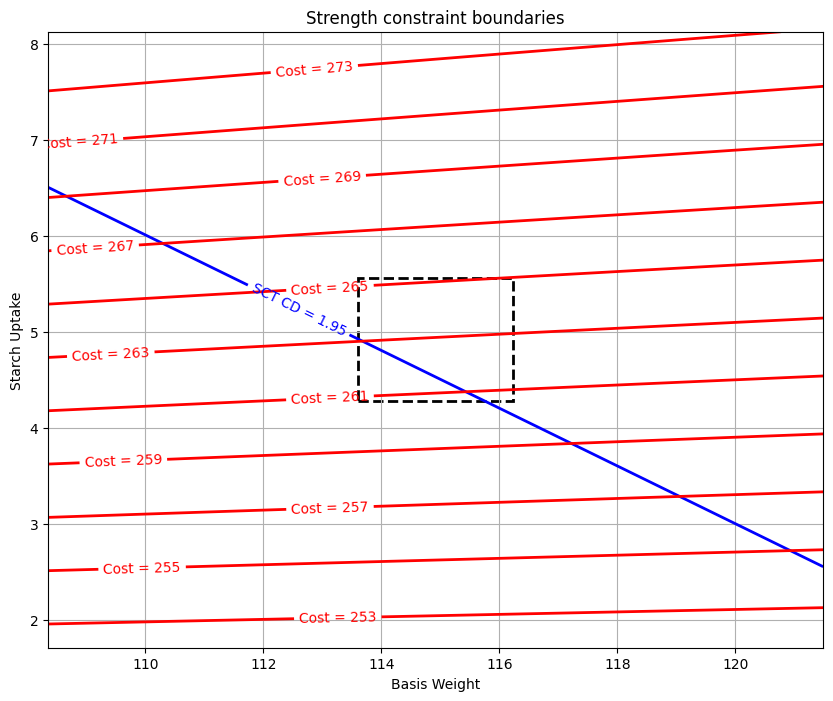

In [6]:
plt.figure(figsize=(10, 8))

# SCT CD = 1.95
cs1 = plt.contour(
    BW,
    STARCH,
    SCT,
    levels=[1.95],
    colors="blue",
    linewidths=2,
)

# Burst = 255
# cs2 = plt.contour(
#     BW,
#     STARCH,
#     BURST,
#     levels=[255],
#     colors="green",
#     linewidths=2,
# )

cs3 = plt.contour(
    BW,
    STARCH,
    COST_T,
    levels=np.arange(int(np.nanmin(COST_T)), int(np.nanmax(COST_T)),2),
    colors="red",
    linewidths=2,
)

plt.clabel(cs1, fmt="SCT CD = %.2f")
#plt.clabel(cs2, fmt="Burst = %.0f")
plt.clabel(cs3, fmt="Cost = %.0f")

plt.xlabel("Basis Weight")
plt.ylabel("Starch Uptake")
plt.title("Strength constraint boundaries")

plt.grid(True)

from matplotlib.patches import Rectangle

ax = plt.gca()

rect = Rectangle(
    (BW_min, SU_min),
    BW_max - BW_min,
    SU_max - SU_min,
    fill=False,
    linewidth=2,
    linestyle="--",
    label="Feasible region"
)

ax.add_patch(rect)

plt.show()





In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reference operating point
base = turnup_data[turnup_data.MBS_Current_reel_ID==12604077].copy()

# Ranges
bw_grid = np.linspace(
    BW_min - 2*(BW_max-BW_min),
    BW_max + 2*(BW_max-BW_min),
    100,
)

starch_grid = np.linspace(
    SU_min - 2*(SU_max-SU_min),
    SU_max + 2*(SU_max-SU_min),
    100,
)

BW, STARCH = np.meshgrid(bw_grid, starch_grid)

SCT = np.zeros_like(BW)
BURST = np.zeros_like(BW)
COST_m2 = np.zeros_like(BW)

for i in range(BW.shape[0]):
    for j in range(BW.shape[1]):

        x = base.copy()

        x["Current_basis_weight"] = BW[i, j]
        x['Starch_uptake_by_paper_Bottom_Roll__g/m2_'] = STARCH[i, j]
        x['Starch_uptake_by_paper_Top_Roll__g/m2_'] = 0

        bw_value = float(x["Current_basis_weight"].iloc[0])

        X = pd.DataFrame(x)

        SCT[i, j] = float(sctcd_strength(X)[0])
        BURST[i, j] = float(burst_strength(X)[0])
        COST_m2[i, j] = float(total_cost(X)[0] * bw_value)



In [8]:
with open(f"COST_m2.pkl", 'wb') as f:
        pickle.dump(COST_m2, f)

In [9]:
print("SCT range:", np.nanmin(SCT), np.nanmax(SCT))
print("Burst range:", np.nanmin(BURST), np.nanmax(BURST))
print("Cost range:", np.nanmin(COST_m2), np.nanmax(COST_m2))

SCT range: 1.8448090426944885 2.072227851906691
Burst range: 234.06481820963953 285.0797647196039
Cost range: 27317.51877317855 33152.653924498736


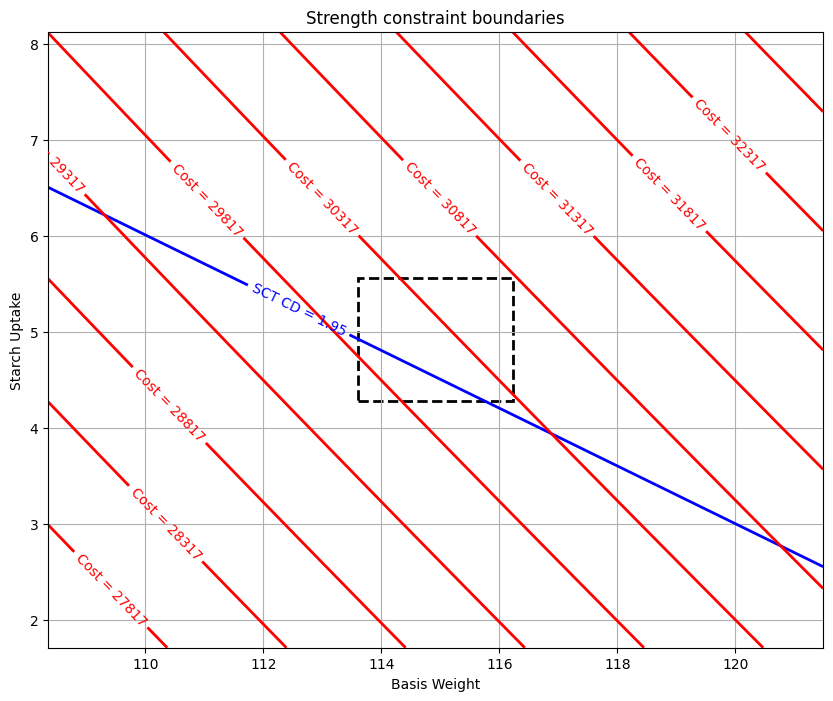

In [10]:
plt.figure(figsize=(10, 8))

# SCT CD = 1.95
cs1 = plt.contour(
    BW,
    STARCH,
    SCT,
    levels=[1.95],
    colors="blue",
    linewidths=2,
)

# Burst = 255
# cs2 = plt.contour(
#     BW,
#     STARCH,
#     BURST,
#     levels=[255],
#     colors="green",
#     linewidths=2,
# )

cs3 = plt.contour(
    BW,
    STARCH,
    COST_m2,
    levels=np.arange(int(np.nanmin(COST_m2)), int(np.nanmax(COST_m2)),500),
    colors="red",
    linewidths=2,
)

plt.clabel(cs1, fmt="SCT CD = %.2f")
#plt.clabel(cs2, fmt="Burst = %.0f")
plt.clabel(cs3, fmt="Cost = %.0f")

plt.xlabel("Basis Weight")
plt.ylabel("Starch Uptake")
plt.title("Strength constraint boundaries")

plt.grid(True)

from matplotlib.patches import Rectangle

ax = plt.gca()

rect = Rectangle(
    (BW_min, SU_min),
    BW_max - BW_min,
    SU_max - SU_min,
    fill=False,
    linewidth=2,
    linestyle="--",
    label="Feasible region"
)

ax.add_patch(rect)

plt.show()


# Knowledge

In [ ]:
_,_ = run_query("Que es la retencion en el proceso de fabricacion de papel")

HTTP status: 200


# Knowledge

# Retention in the Papermaking Process

## Definition

**Retention** in papermaking refers to the ability to keep solid materials—particularly **fibers, fines (small fiber fragments), and fillers (mineral pigments)**—in the paper sheet during the forming process, rather than losing them through drainage water as the sheet is formed on the paper machine.

## Why Retention Matters

Retention is critical because:
- **Economic efficiency**: Lost materials represent wasted raw materials and increased effluent treatment costs
- **Product quality**: Better retention leads to more homogeneous sheet structure
- **Environmental impact**: Reduces solid waste in process water
- **Machine runnability**: Affects drainage rates and formation quality

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1217:0]

## Types of Retention

### 1. **Mechanical (Filtration) Retention**
- Occurs when particles are physically trapped in the forming fiber mat
- More effective for **coarse particles**
- Particle shape matters: platelet-shaped particles (clay, talc) retain better than blocky particles (chalk)
- Very fine pigment can be trapped within fiber lumen or between fibrils

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1217:0], [papermaking_science_technology.pdf:d6f6f20ccb65b658:1216:1]

### 2. **Chemical Retention**
- Uses retention aid chemicals to attach particles to fiber surfaces through **co-flocculation** before web formation
- More effective for **fine particles**
- Creates agglomeration of filler particles, making them larger and easier to retain mechanically

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1217:0]

## Retention Mechanisms

Three principal categories exist:

1. **Charge neutralization**
2. **Patch-flocculation** - cationic patches on one particle interact with anionic patches on another
3. **Bridging** - the most common in practice, where polymers form bridges between particles

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1218:0], [papermaking_science_technology.pdf:d6f6f20ccb65b658:1183:0]

### Network Flocculation
A specialized mechanism based on hydrogen bonding interactions (e.g., phenolic resin with PEO or bentonite with anionic polyacrylamide), particularly useful in contaminated systems with high conductivity.

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1254:0]

## Retention Aid Systems

Modern paper machines typically use **multicomponent retention systems** rather than single polymers:

- **Single-polymer systems**: Seldom adequate for modern machines
- **Dual-component systems**: Common, often combining high molecular weight (HMW) cationic polyelectrolytes with inorganic microparticles (silica, bentonite)
- **Multi-component systems**: Increasingly applied for optimal performance

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1218:0], [papermaking_science_technology.pdf:d6f6f20ccb65b658:1254:0]

## Trade-offs

**Important consideration**: Retention, drainage, and formation are interrelated but often opposed to each other—improving one can impair the others. This is why the evolution toward multicomponent systems has been necessary to optimize all three simultaneously.

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1254:0]

## Key Factors Affecting Retention

- Furnish composition
- Particle size and shape
- Chemical environment and turbulence
- Polymer type, molecular weight, and charge
- Grammage and machine construction
- Running strategy (speed, turbulence level)

[papermaking_science_technology.pdf:d6f6f20ccb65b658:1218:0], [papermaking_science_technology.pdf:d6f6f20ccb65b658:1216:1]

In [6]:
_,_ = run_query("A question about papermaking: If I want to reduce starch uptake to keep SCT CD and Burst just over some minimum values, it may happen that this reduction is limited by the strength property closer to the minimum. Does it make sense that, by increasing the basis weight I would have more room to more starch reduction?")

HTTP status: 200


Yes, your reasoning makes excellent sense from a papermaking engineering perspective. Let me explain why:

## The Logic Behind Your Approach

**The Fundamental Relationship:**

When you reduce starch uptake, you're weakening multiple strength properties simultaneously (SCT CD, Burst, etc.). Whichever property is closest to its minimum specification becomes your **limiting constraint** - you can't reduce starch any further without falling below spec on that property.

**Why Increasing Basis Weight Creates More Room:**

By increasing basis weight, you're adding more fiber to the sheet structure, which provides:

1. **Inherent strength improvement** - More fibers = stronger base sheet
2. **Higher baseline properties** - All strength properties (SCT, Burst, etc.) improve with the additional fiber
3. **Greater margin above minimums** - This creates a "buffer" that allows for more starch reduction

## Evidence from the Context

The context supports this relationship:

**Basis Weight and Strength Correlation:**
The document discusses trials with different basis weights (95 g/m² FLU vs 160 g/m² TL) and shows that "the amount of starch is by far the most important factor contributing to the strength properties of board" [starch_sizing.pdf:953f472e38cd35ea:9:0].

**Starch Amount Impact:**
The data shows clear relationships between starch pickup and strength properties: "strength properties continue to increase from 60 to 70 kN/m" with increased starch amounts [starch_sizing.pdf:953f472e38cd35ea:16:0], and "burst increase can be explained through differences in starch pick up" [starch_sizing.pdf:953f472e38cd35ea:16:0].

## Practical Optimization Strategy

Your approach would work as follows:

1. **Current state**: Limited starch reduction due to Property X being closest to minimum
2. **Increase basis weight**: All properties improve, including Property X
3. **New opportunity**: Property X now has more margin, allowing further starch reduction
4. **Net result**: Potentially lower total cost (more fiber, less starch) while maintaining specs

## Important Consideration

The economic viability depends on the **relative costs** of fiber vs. starch and the **magnitude of improvement** you can achieve. You'd need to calculate whether the cost of additional fiber is offset by the savings from reduced starch usage.

This is a sound engineering optimization approach that leverages the complementary contributions of fiber and starch to paper strength.

# Benchmark

In [29]:
response = requests.get(
    "http://localhost:5000/process-data/grades",
)

response.json()["grades"]


params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "y_variable_summary_secondary": "Speed",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "grade",
    "color_variable_summary": "cost_grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Current_reel_weight'],
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Current_reel_weight'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)


tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [2],
    "objects": ["cost"],
    "secondary_objects":["chemicals", "steam", "electricity"],
    "summary": False,
    "output_format": "json",
}, endpoint="diagnosis",run_async=True, download_artifacts= True)



Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,Speed,cost,Cost__€/T_
0,12601665,2026,10,85,6010,1342.397705,Steam__€/T_,87.782578
1,12601666,2026,10,85,6010,1342.872314,Steam__€/T_,89.354004
2,12601667,2026,10,85,6010,1341.722290,Steam__€/T_,88.837769
3,12601668,2026,10,85,6010,1320.777100,Steam__€/T_,94.010635
4,12601669,2026,10,85,6010,1320.692871,Steam__€/T_,94.009995


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,6.196404,25
1,2026,9,Electricity__€/T_,32.898804,25
2,2026,9,Fibre_cost__€/T_,127.373787,25
3,2026,9,Starch__€/T_,23.865166,25
4,2026,9,Steam__€/T_,87.489822,25


metadata
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 50, 'prepared_rows': 7815, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 50, 'prepared_rows': 7815, 'x_variable': 'Wedge_Week'}
Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,AB_Grade_ID,grammage,paper_type,cost,Cost__€/T_
0,12601665,6010085,85,6010,Steam__€/T_,87.782578
1,12601666,6010085,85,6010,Steam__€/T_,89.354004
2,12601667,6010085,85,6010,Steam__€/T_,88.837769
3,12601668,6010085,85,6010,Steam__€/T_,94.010635
4,12601669,6010085,85,6010,Steam__€/T_,94.009995


... (24 outputs left out)

main


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.960114,152,TOTAL,285.423035,148.537079
1,current,3300100,353.155365,47,TOTAL,281.258698,71.896667
2,current,3300110,278.191772,57,TOTAL,286.205566,-8.013794
3,current,3300120,275.125885,23,TOTAL,291.348145,-16.222260
4,current,6010085,291.831665,155,TOTAL,301.260162,-9.428497


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.960114,152,TOTAL,285.423035,148.537079
1,current,3300100,353.155365,47,TOTAL,281.258698,71.896667
2,current,3300110,278.191772,57,TOTAL,286.205566,-8.013794
3,current,3300120,275.125885,23,TOTAL,291.348145,-16.222260
4,current,6010085,291.831665,155,TOTAL,301.260162,-9.428497


In [32]:
import pandas as pd
df = pd.read_parquet("aggregated_turned_up_20260825.parquet")

In [33]:
df.tail()

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Dry_Strength_Agent__€/T_,Natriumhydroxide__€/T_,Electricity__€/T_,Steam__€/T_,Fibre_cost__€/T_,Combined_cost__€/T_,Total_SQM_cost__€/hm2_,source_file,turn_up_rows_used,ambient_temp_C
9,2026-08-25 10:43:00,12606009,6010120,2.13,3.86,277.48,NaN,662.946509,1052.602857,48744.040234,...,0.0,0.092698,30.115634,80.337117,127.844686,263.569635,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,17.090000
10,2026-08-25 11:04:00,12606010,6010120,NaN,NaN,NaN,NaN,661.557178,1053.481836,15121.545996,...,0.0,0.603153,35.155347,88.004205,127.980130,276.889407,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,17.726667
11,2026-08-25 12:24:00,12606011,6010120,2.21,4.22,284.05,206.0,663.052179,1052.616650,49710.223828,...,0.0,0.601574,35.978729,79.196955,128.290938,268.848218,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,20.100000
12,2026-08-25 13:20:00,12606012,6010120,2.24,3.97,281.96,NaN,662.788000,1052.683166,48655.791406,...,0.0,0.607324,35.556722,83.132453,127.953114,272.267623,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,22.533333
13,2026-08-25 14:15:00,12606013,6010120,NaN,NaN,NaN,NaN,662.852344,1052.687988,47152.318360,...,0.0,0.604682,35.313322,81.104353,127.817965,269.825053,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,23.325000
